# Data Validation of the Sîrbu-Loreto Model on Italian Twitter

This notebook measures the model's key quantities — **φ** (polarization), **p_om** (open-mindedness), 
and **m** (mild-source fraction) — from Italian political Twitter data (2018–2022), 
and tests whether the qualitative predictions of the model hold on real data.

**Dataset:** ~425,000 normal users, 39 politicians, ~450 information sources (journalists, media, influencers). 
Interactions: retweets and annotated quote-tweets with agreement/disagreement labels.

## 1. Data Loading and Preprocessing

We load three datasets:
- `twitter_it_leaders`: all leaders (politicians + information sources) with metadata
- `twitter_it_tweets`: original tweets by leaders
- `twitter_it_retweets`: all retweets, with who retweeted whom and when

We filter retweets to keep only those where the retweeted author is a leader, 
remove self-retweets, and add temporal information (month/year).

In [1]:
from itertools import combinations
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx 
from community import community_louvain
from collections import defaultdict

In [ ]:

# Lettura dei file parquet
twitter_it_leaders = pd.read_parquet("twitter_it_leaders.parquet copy") #file con i leaders e il loro screen name etc.
twitter_it_tweets = pd.read_pickle("twitter_it_tweets.pkl copy") #file con tutti i tweet, con le informazioni su chi ha retweettato chi, e quando
twitter_it_retweets = pd.read_pickle("twitter_it_retweets.pkl copy") #file con tutti i retweet, con le informazioni su chi ha retweettato chi, e quando

# Rinomino la prima colonna di leaders in "reference_author"
twitter_it_leaders.columns = ["reference_author"] + list(twitter_it_leaders.columns[1:])

#Inner join: tieni solo i tweet i cui autori sono leader
leaders_unique = twitter_it_leaders[["reference_author"]].drop_duplicates()
twitter_it_tweets = twitter_it_tweets.merge(leaders_unique, on="reference_author", how="inner")

# Filtra retweets dove reference_author != referenced_author
twitter_it_retweets = twitter_it_retweets[
    twitter_it_retweets["reference_author"] != twitter_it_retweets["referenced_author"]
]

# Inner join: tieni solo retweet il cui referenced_author è un leader
twitter_it_retweets = twitter_it_retweets.merge(
    leaders_unique.rename(columns={"reference_author": "referenced_author"}),
    on="referenced_author",
    how="inner"
)

# Inner join con i tweets per ottenere reference_time del tweet originale (utile?)
tweets_subset = (
    twitter_it_tweets[["reference_time", "reference_id"]]    
    .drop_duplicates()
    .rename(columns={"reference_id": "referenced_id", "reference_time": "ref_time_from_tweets"})
)
twitter_it_retweets = twitter_it_retweets.merge(tweets_subset, on="referenced_id", how="inner")

twitter_it_retweets = twitter_it_retweets.rename(columns={"ref_time_from_tweets": "referenced_time"})


twitter_it_retweets["referenced_time"] = pd.to_datetime(twitter_it_retweets["referenced_time"], utc=True)

# Crea colonna month_year nel formato "MM/YYYY"
twitter_it_retweets["month_year"] = twitter_it_retweets["referenced_time"].dt.strftime("%m/%Y")

FileNotFoundError: [Errno 2] No such file or directory: 'twitter_it_leaders.parquet copy'

## 2. Defining Politicians and Political Communities

Politicians are identified as leaders with a non-null `pageCluster` and null `Rating`. 
We then assign them to three political communities based on domain knowledge:

- **Community 0 (Centro-destra):** FdI, Lega, Forza Italia, Berlusconi, etc.
- **Community 1 (M5S):** Movimento 5 Stelle, Paragone, Di Maio, Conte
- **Community 2 (Centro-sinistra + Sinistra):** PD, Italia Viva, Azione, SI, Verdi, etc.


In [ ]:
politici = twitter_it_leaders[twitter_it_leaders['pageCluster'].notna()]

In [ ]:
politici= politici[politici['Rating'].isna()]

In [ ]:
# 1. Extract the actual IDs from the correct column in your politicians dataframe
# Replace 'author_id' with whatever column actually holds the numeric IDs in that dataset
politici_set = set(politici['reference_author'].astype(str).str.strip())

# 2. Convert dataframe columns to string and strip any accidental whitespace
clean_ref_author = twitter_it_retweets['reference_author'].astype(str).str.strip()
clean_referenced_author = twitter_it_retweets['referenced_author'].astype(str).str.strip()

# 3. Apply the filters using the cleaned data
rt_pol = twitter_it_retweets[
    (twitter_it_retweets['reference_type'] == 'retweeted') &
    (clean_ref_author.isin(politici_set)) &
    (clean_referenced_author.isin(politici_set))
].copy()

print(f"Retweet edges (politician → politician): {len(rt_pol):,}")
print(f"Unique retweeters: {rt_pol['reference_author'].nunique()}")
print(f"Unique retweeted:  {rt_pol['referenced_author'].nunique()}")

Retweet edges (politician → politician): 50,853
Unique retweeters: 37
Unique retweeted:  36


In [ ]:
import networkx as nx
import community as community_louvain

# Build undirected graph — treating A→B and B→A as the same edge
G = nx.Graph()
G.add_edges_from(
    zip(rt_pol['reference_author'].astype(str),
        rt_pol['referenced_author'].astype(str))
)
G.remove_edges_from(list(nx.selfloop_edges(G)))

print(f"Nodes: {G.number_of_nodes()}  |  Edges: {G.number_of_edges()}")

# Aggiungi random_state (es. 42 o qualsiasi altro numero intero) per bloccare la casualità
partition = community_louvain.best_partition(G, random_state=42)

mod = community_louvain.modularity(partition, G)
print(f"Modularity: {mod:.4f}")
print(f"Communities found: {len(set(partition.values()))}")

Nodes: 37  |  Edges: 115
Modularity: 0.3986
Communities found: 3


In [ ]:
# Map author IDs → screen names using twitter_it_leaders
leaders_df = twitter_it_leaders.copy()
id_col = 'author_id' if 'author_id' in leaders_df.columns else 'reference_author'
leaders_df[id_col] = leaders_df[id_col].astype(str)
id_to_name = dict(zip(leaders_df[id_col], leaders_df['author_screen_name']))

comunita_nomi = defaultdict(list)
for author_id, comm_id in partition.items():
    name = id_to_name.get(str(author_id), f"ID sconosciuto ({author_id})")
    comunita_nomi[comm_id].append(name)

for comm_id, nomi in sorted(comunita_nomi.items()):
    print(f"Comunità {comm_id} ({len(nomi)} membri):")
    print("  " + ", ".join(sorted(nomi)))
    print("-" * 60)

Comunità 0 (14 membri):
  antoniodepoli, coraggio_italia, forza_italia, fratelliditalia, giorgiameloni, giovannitoti, italiaalcentro_, italiaviva, legasalvini, luigibrugnaro, matteorenzi, matteosalvinimi, maurizio_lupi, udcita
------------------------------------------------------------
Comunità 1 (14 membri):
  articolounomdp, azione_it, berlusconi, carlocalenda, ellyesse, emmabonino, enricoletta, giuseppeconteit, luigidimaio, mov5stelle, pdnetwork, piu_europa, robersperanza, sbonaccini
------------------------------------------------------------
Comunità 2 (9 membri):
  angelobonelli1, demagistris, direzioneprc, europaverde_it, manifesta_it, movimentodema, nfratoianni, si_sinistra, unione_popolare
------------------------------------------------------------


### Manual community assignment

We override the Louvain partition with domain-knowledge-based communities. 
This is necessary because Louvain groups Berlusconi with the centre-left cluster 
and merges M5S with PD, which is politically incorrect. 
The manual assignment reflects the actual Italian political landscape during 2018–2022.

In [ ]:
# --- Manual community assignment by screen_name ---
manual_groups = {
    0: ['fratelliditalia', 'giorgiameloni', 'legasalvini', 'forza_italia',
        'giovannitoti', 'matteosalvinimi', 'maurizio_lupi', 'berlusconi'],
    1: ['mov5stelle', 'gparagone', 'luigidimaio', 'giuseppeconteit'],
    2: ['italiaviva', 'emmabonino', 'europaverde_it', 'pdnetwork',
        'coraggio_italia', 'manifesta_it', 'unione_popolare', 'matteorenzi',
        'carlocalenda', 'direzioneprc', 'si_sinistra', 'demagistris',
        'movimentodema', 'luigibrugnaro', 'ellyesse', 'articolounomdp',
        'robersperanza', 'antoniodepoli', 'enricoletta', 'nfratoianni',
        'angelobonelli1', 'sbonaccini', 'piu_europa', 'potere_alpopolo',
        'azione_it']
}

# --- Map screen_name → reference_author (numeric ID) ---
leaders_df = twitter_it_leaders.copy()
leaders_df['reference_author'] = leaders_df['reference_author'].astype(str).str.strip()
leaders_df['author_screen_name'] = leaders_df['author_screen_name'].astype(str).str.strip().str.lower()

name_to_id = dict(zip(leaders_df['author_screen_name'], leaders_df['reference_author']))

# --- Build new partition dict (replaces Louvain partition) ---
partition = {}
for comm_id, screen_names in manual_groups.items():
    for sn in screen_names:
        rid = name_to_id.get(sn.lower())
        if rid:
            partition[rid] = comm_id
        else:
            print(f"WARNING: '{sn}' not found in twitter_it_leaders")

n_communities = len(manual_groups)  # 3
politici_ids = set(politici['reference_author'].astype(str).str.strip())
# --- Update politician_to_comm ---
politician_to_comm = {str(k): v for k, v in partition.items() if str(k) in politici_ids}

# --- Update politici_ids to include new politicians (e.g. gparagone, potere_alpopolo) ---
all_manual_ids = set(partition.keys())
politici_ids = politici_ids | all_manual_ids  # add any new ones

print(f"Partition size: {len(partition)}")
print(f"politician_to_comm size: {len(politician_to_comm)}")
for comm_id, screen_names in manual_groups.items():
    mapped = [sn for sn in screen_names if name_to_id.get(sn.lower())]
    print(f"Gruppo {comm_id}: {len(mapped)}/{len(screen_names)} mapped")

Partition size: 37
politician_to_comm size: 36
Gruppo 0: 8/8 mapped
Gruppo 1: 4/4 mapped
Gruppo 2: 25/25 mapped


## 3. Opinion Vectors of Normal Users

For each normal user (not a leader), we compute a monthly **opinion vector** 
by counting their retweets toward politicians in each community and normalizing.

The opinion vector **x** = (x₀, x₁, x₂) lies on the 2-simplex, where xₖ is the 
fraction of retweets directed at community k. We require ≥3 retweets/month to avoid noise.

This is the empirical analogue of the agent state in the Sîrbu-Loreto model.

In [ ]:
# --- 1. Define sets ---
politici_ids = set(politici['reference_author'].astype(str).str.strip())
all_leader_ids = set(twitter_it_leaders['reference_author'].astype(str).str.strip())

# --- 2. Politician one-hot vectors (community from Louvain) ---
n_communities = len(set(partition.values()))  # 3
politician_to_comm = {str(k): v for k, v in partition.items() if str(k) in politici_ids}

# --- 3. Filter retweets: normal user → politician ---
rt = twitter_it_retweets.copy()
rt['reference_author'] = rt['reference_author'].astype(str).str.strip()
rt['referenced_author'] = rt['referenced_author'].astype(str).str.strip()

rt_normal = rt[
    (rt['reference_type'] == 'retweeted') &
    (~rt['reference_author'].isin(all_leader_ids)) &
    (rt['referenced_author'].isin(politici_ids))
].copy()

# --- 4. Assign community of retweeted politician ---
rt_normal['comm'] = rt_normal['referenced_author'].map(politician_to_comm)
rt_normal = rt_normal.dropna(subset=['comm'])
rt_normal['comm'] = rt_normal['comm'].astype(int)

print(f"Retweets (normal user → politician): {len(rt_normal):,}")
print(f"Unique normal users: {rt_normal['reference_author'].nunique():,}")

# --- 5. Monthly opinion vectors (min 3 retweets) ---
counts = (
    rt_normal
    .groupby(['reference_author', 'month_year', 'comm'])
    .size()
    .unstack(fill_value=0)
)

for c in range(n_communities):
    if c not in counts.columns:
        counts[c] = 0
counts = counts[list(range(n_communities))]

# Filter: keep only user-month pairs with at least 3 total retweets
totals = counts.sum(axis=1)
counts = counts[totals >= 3]
totals = totals[totals >= 3]

# Normalize
opinion_vectors_monthly = counts.div(totals, axis=0)
opinion_vectors_monthly = opinion_vectors_monthly.reset_index()
opinion_vectors_monthly.columns = ['reference_author', 'month_year'] + [f'comm_{c}' for c in range(n_communities)]

print(f"\nRows after filter (≥3 retweets/month): {len(opinion_vectors_monthly):,}")
print(opinion_vectors_monthly.head(10))

Retweets (normal user → politician): 7,643,966
Unique normal users: 425,456

Rows after filter (≥3 retweets/month): 498,935
      reference_author month_year    comm_0    comm_1    comm_2
0            100000213    07/2020  0.000000  0.000000  1.000000
1            100000213    09/2022  0.000000  0.000000  1.000000
2            100000213    11/2020  0.000000  0.000000  1.000000
3            100000213    12/2022  0.000000  0.000000  1.000000
4  1000010057743065089    01/2019  0.966102  0.016949  0.016949
5  1000010057743065089    02/2019  1.000000  0.000000  0.000000
6  1000010057743065089    06/2018  0.921875  0.078125  0.000000
7  1000010057743065089    07/2018  0.778846  0.221154  0.000000
8  1000010057743065089    08/2018  0.982456  0.017544  0.000000
9  1000010057743065089    09/2018  0.969466  0.030534  0.000000


### Visualization on the simplex

We project opinion vectors onto a ternary plot for a random month. 
Each point is a user; clustering at corners indicates polarization.

Month: 02/2022 — 6284 users


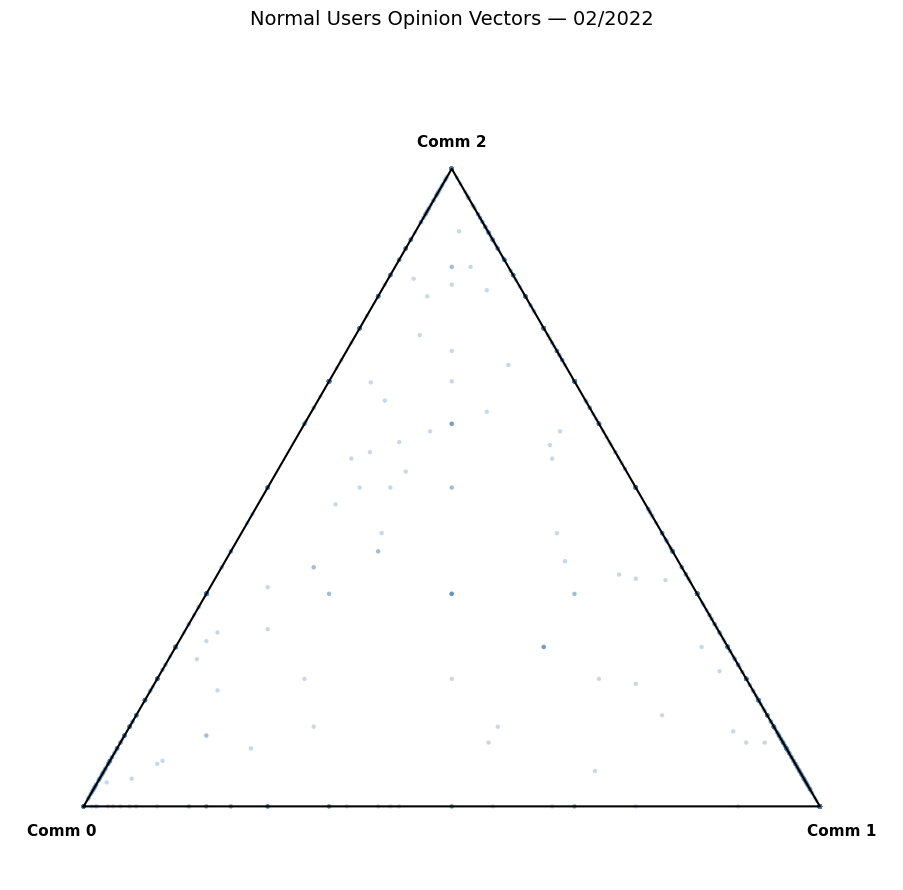

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- Pick a random month ---
months = opinion_vectors_monthly['month_year'].unique()
chosen_month = np.random.choice(months)
df_month = opinion_vectors_monthly[opinion_vectors_monthly['month_year'] == chosen_month]

print(f"Month: {chosen_month} — {len(df_month)} users")

# --- Ternary to Cartesian ---
def ternary_to_cartesian(p0, p1, p2):
    x = 0.5 * (2 * p1 + p2)
    y = (np.sqrt(3) / 2) * p2
    return x, y

# --- Plot ---
fig, ax = plt.subplots(figsize=(10, 9))

# Triangle
corners = np.array([[0, 0], [1, 0], [0.5, np.sqrt(3)/2], [0, 0]])
ax.plot(corners[:, 0], corners[:, 1], 'k-', lw=1.5)

# Points
x, y = ternary_to_cartesian(df_month['comm_0'].values, df_month['comm_1'].values, df_month['comm_2'].values)
ax.scatter(x, y, alpha=0.3, s=10, c='steelblue', edgecolors='none')

# Corner labels
ax.text(0 - 0.03, -0.04, 'Comm 0', ha='center', fontsize=11, fontweight='bold')
ax.text(1 + 0.03, -0.04, 'Comm 1', ha='center', fontsize=11, fontweight='bold')
ax.text(0.5, np.sqrt(3)/2 + 0.03, 'Comm 2', ha='center', fontsize=11, fontweight='bold')

ax.set_xlim(-0.1, 1.1)
ax.set_ylim(-0.1, 1.05)
ax.set_aspect('equal')
ax.axis('off')
ax.set_title(f"Normal Users Opinion Vectors — {chosen_month}", fontsize=14)
plt.tight_layout()
plt.show()

## 4. Order Parameter φ (Polarization)

We measure polarization using the order parameter from the model:

$$\phi = \frac{K}{K-1} \cdot \frac{1}{N} \sum_i \|\mathbf{x}_i - \mathbf{b}\|^2$$

where **b** = (1/K, ..., 1/K) is the barycentre. φ = 0 means consensus (all agents at centre), 
φ = 1 means full polarization (agents at corners), φ = 1/(K+1) means free exploration.

In [5]:

def phi(pop):
    K = pop.shape[1]
    b = np.ones(K) / K
    return float(np.mean(np.sum((pop - b)**2, axis=1)) * K / (K - 1))


events_lines = {
    '03/2018': 'Elezioni 2018',
    '06/2018': 'Conte I',
    '05/2019': 'Europee 2019',
    '09/2019': 'Conte II',
    '03/2020': 'Pandemia',
    '02/2021': 'Draghi',
    '02/2022': 'Guerra Ucraina',
    '09/2022': 'Elezioni 2022',
} 

event_colors = {
    'Elezioni 2018':  'purple',
    'Conte I':        'blue',
    'Europee 2019':   'green',
    'Conte II':       'red',
    'Pandemia':       'black',
    'Draghi':         'brown',
    'Guerra Ucraina': 'orange',
    'Elezioni 2022':  'purple',
}

# --- Define ordered months and events ---
all_months = sorted(opinion_vectors_monthly['month_year'].unique(),
                    key=lambda x: (int(x.split('/')[1]), int(x.split('/')[0]))) 

# --- Monthly phi ---
phi_monthly = {}
for m in all_months:
    df_m = opinion_vectors_monthly[opinion_vectors_monthly['month_year'] == m]
    pop = df_m[['comm_0', 'comm_1', 'comm_2']].values
    if len(pop) > 0:
        phi_monthly[m] = phi(pop)

# --- Plot ---
fig, ax = plt.subplots(figsize=(16, 5))
x = range(len(all_months))
phi_values = [phi_monthly.get(m, np.nan) for m in all_months]

ax.plot(x, phi_values, 'o-', color='steelblue', markersize=4)

# --- Event lines (CORRECTED) ---
# Swapped 'date' and 'event' to match the dictionary structure {date: event}
for date, event in events_lines.items():
    if date in all_months:
        idx = list(all_months).index(date)
        # Use the correct key for color lookup
        color = event_colors.get(event, 'gray') 
        
        ax.axvline(x=idx, color=color, linestyle='--', alpha=0.7, linewidth=1)
        ax.text(idx, ax.get_ylim()[1], event, rotation=90, va='top', ha='right',
                fontsize=7, color=color)

ax.set_xticks(x)
ax.set_xticklabels(all_months, rotation=90, fontsize=7)
ax.set_ylabel('φ (polarization)')
ax.set_title('Monthly Polarization φ of Normal Users')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

NameError: name 'opinion_vectors_monthly' is not defined

## 5. Measuring Open-Mindedness (p_om) from Quote-Tweets

We use ~12M annotated quote-tweets (with agreement/disagreement labels from a classifier) 
to measure open-mindedness. For each quote, we compute the **cosine distance** between 
the user's opinion vector and the quoted politician's community (one-hot vector).

The distance d(i) = 1 − o(x_user, e_comm) measures how far the user is from the 
quoted politician on the simplex.

In [ ]:
# --- Load annotated interactions (quotes) ---
annotated_interaction = pd.read_pickle("annotated_interactions.pkl copy")

# --- Clean IDs ---
annotated_interaction['reference_author'] = annotated_interaction['reference_author'].astype(str).str.strip()
annotated_interaction['referenced_author'] = annotated_interaction['referenced_author'].astype(str).str.strip()

# --- Filter: normal user quoting a politician ---
quotes_normal = annotated_interaction[
    (~annotated_interaction['reference_author'].isin(all_leader_ids)) &
    (annotated_interaction['referenced_author'].isin(politici_ids))
].copy()

# --- Assign community of quoted politician ---
quotes_normal['comm'] = quotes_normal['referenced_author'].map(politician_to_comm)
quotes_normal = quotes_normal.dropna(subset=['comm'])
quotes_normal['comm'] = quotes_normal['comm'].astype(int)

# --- Ensure month_year column exists ---
if 'month_year' not in quotes_normal.columns:
    quotes_normal['reference_time'] = pd.to_datetime(quotes_normal['reference_time'], utc=True)
    quotes_normal['month_year'] = quotes_normal['reference_time'].dt.strftime("%m/%Y")

print(f"Quotes (normal user → politician): {len(quotes_normal):,}")
print(f"Unique normal users: {quotes_normal['reference_author'].nunique():,}")
print(f"Available months: {sorted(quotes_normal['month_year'].unique())}")

# --- Pick an example month (e.g. 01/2019) ---
example_month = '01/2019'
q_month = quotes_normal[quotes_normal['month_year'] == example_month]



Quotes (normal user → politician): 12,264,479
Unique normal users: 689,847
Available months: ['01/2018', '01/2019', '01/2020', '01/2021', '01/2022', '01/2023', '02/2018', '02/2019', '02/2020', '02/2021', '02/2022', '02/2023', '03/2018', '03/2019', '03/2020', '03/2021', '03/2022', '03/2023', '04/2018', '04/2019', '04/2020', '04/2021', '04/2022', '04/2023', '05/2018', '05/2019', '05/2020', '05/2021', '05/2022', '05/2023', '06/2018', '06/2019', '06/2020', '06/2021', '06/2022', '07/2018', '07/2019', '07/2020', '07/2021', '07/2022', '08/2018', '08/2019', '08/2020', '08/2021', '08/2022', '09/2018', '09/2019', '09/2020', '09/2021', '09/2022', '10/2018', '10/2019', '10/2020', '10/2021', '10/2022', '11/2018', '11/2019', '11/2020', '11/2021', '11/2022', '12/2018', '12/2019', '12/2020', '12/2021', '12/2022']


In [ ]:
from scipy.spatial.distance import cosine

# --- 1. Prepare quotes dataset ---
annotated_interaction['reference_author'] = annotated_interaction['reference_author'].astype(str).str.strip()
annotated_interaction['referenced_author'] = annotated_interaction['referenced_author'].astype(str).str.strip()

# Ensure month_year exists
if 'month_year' not in annotated_interaction.columns:
    annotated_interaction['reference_time'] = pd.to_datetime(annotated_interaction['reference_time'], utc=True)
    annotated_interaction['month_year'] = annotated_interaction['reference_time'].dt.strftime("%m/%Y")

# Filter: normal user quoting a politician
quotes = annotated_interaction[
    (~annotated_interaction['reference_author'].isin(all_leader_ids)) &
    (annotated_interaction['referenced_author'].isin(politici_ids))
].copy()

# --- 2. Build opinion vector lookup: (user, month) → vector ---
ov_lookup = opinion_vectors_monthly.set_index(['reference_author', 'month_year'])
# columns: comm_0, comm_1, comm_2

# --- 3. Build politician one-hot vectors ---
pol_onehot = {}
for pol_id, comm in politician_to_comm.items():
    vec = np.zeros(n_communities)
    vec[comm] = 1.0
    pol_onehot[pol_id] = vec

# --- 4. Compute distance for each quote ---
distances = []
for _, row in quotes.iterrows():
    user = row['reference_author']
    month = row['month_year']
    pol = row['referenced_author']
    
    # Check if user has opinion vector for this month
    if (user, month) in ov_lookup.index and pol in pol_onehot:
        user_vec = ov_lookup.loc[(user, month)].values
        pol_vec = pol_onehot[pol]
        dist = 1 - np.dot(user_vec, pol_vec) / (np.linalg.norm(user_vec) * np.linalg.norm(pol_vec) + 1e-10)
        distances.append(dist)
    else:
        distances.append(np.nan)

quotes['distance'] = distances


### vediamo per un utente ed un mese la distribuzione dei suoi agreement 

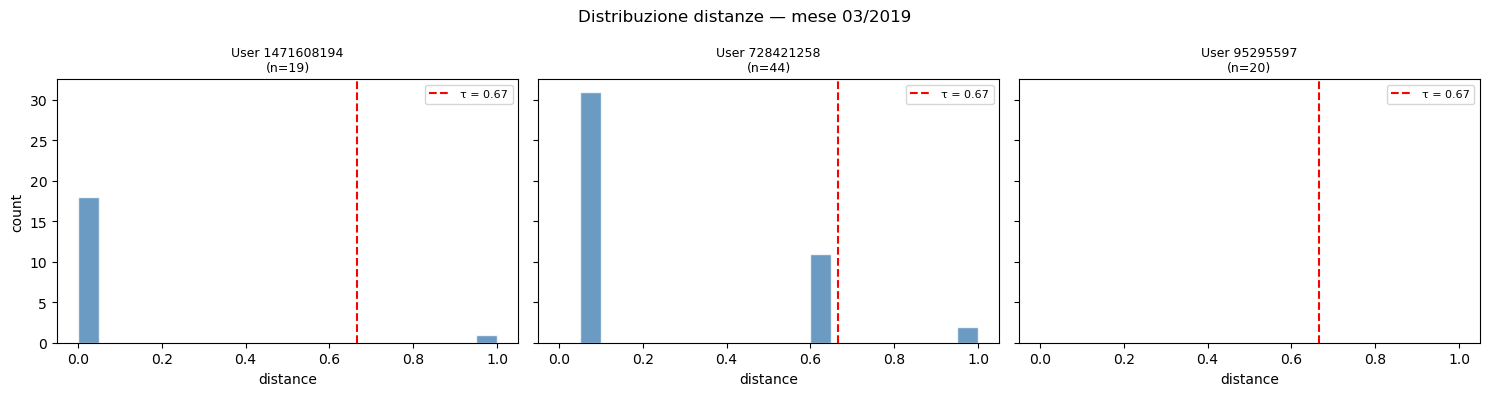

In [ ]:

tau = 2/3

# --- Mese a caso ---
month = np.random.choice(quotes['month_year'].unique())
df_month = quotes[quotes['month_year'] == month]

# --- 3 utenti a caso tra quelli con almeno 10 interazioni nel mese (per avere una distribuzione leggibile) ---
counts = df_month['reference_author'].value_counts()
eligible_users = counts[counts >= 19].index
users = np.random.choice(eligible_users, size=min(3, len(eligible_users)), replace=False)

fig, axes = plt.subplots(1, len(users), figsize=(15, 4), sharey=True)
if len(users) == 1:
    axes = [axes]

for ax, user in zip(axes, users):
    dists = df_month[df_month['reference_author'] == user]['distance']
    ax.hist(dists, bins=20, range=(0, 1), color='steelblue', edgecolor='white', alpha=0.8)
    ax.axvline(tau, color='red', linestyle='--', linewidth=1.5, label=f'τ = {tau:.2f}')
    ax.set_title(f'User {user}\n(n={len(dists)})', fontsize=9)
    ax.set_xlabel('distance')
    ax.legend(fontsize=8)

axes[0].set_ylabel('count')
fig.suptitle(f'Distribuzione distanze — mese {month}', fontsize=12)
plt.tight_layout()
plt.show()

### Validation: distance vs agreement

We verify that the distance measure is meaningful: positive-agreement quotes should have 
low distance (echo chamber), while negative-agreement quotes should have high distance (cross-camp criticism).

In [ ]:
# Drop rows without opinion vector
quotes_with_dist = quotes.dropna(subset=['distance'])

print(f"Quotes with distance computed: {len(quotes_with_dist):,} / {len(quotes):,}")

# --- Separate positive and negative agreement ---
quotes_with_dist = quotes_with_dist.copy()
quotes_with_dist['agreement'] = pd.to_numeric(quotes_with_dist['agreement'], errors='coerce')

quotes_positive = quotes_with_dist[quotes_with_dist['agreement'] > 0].copy()
quotes_negative = quotes_with_dist[quotes_with_dist['agreement'] < 0].copy()

print(f"Positive agreement: {len(quotes_positive):,}  — mean distance: {quotes_positive['distance'].mean():.4f}")
print(f"Negative agreement: {len(quotes_negative):,}  — mean distance: {quotes_negative['distance'].mean():.4f}")

Quotes with distance computed: 8,306,557 / 12,264,482
Positive agreement: 7,445,862  — mean distance: 0.0459
Negative agreement: 860,695  — mean distance: 0.6868


### Defining open-minded interactions

An interaction is classified as **open-minded** if:
- Positive agreement with a **distant** politician (d > τ), or
- Negative agreement with a **close** politician (d < 1 − τ)

with threshold τ = 2/3. This captures cross-camp approval and within-camp criticism.

For each user-month, **p_om = fraction of open-minded interactions**. 
The population p_om is the mean across users.

In [ ]:

events = {
    '03/2018': 'Elezioni 2018',
    '06/2018': 'Conte I',
    '05/2019': 'Europee 2019',
    '09/2019': 'Conte II',
    '03/2020': 'Pandemia',
    '02/2021': 'Draghi',
    '02/2022': 'Guerra Ucraina',
    '09/2022': 'Elezioni 2022',
} 

event_colors = {
    'Elezioni 2018':  'purple',
    'Conte I':        'blue',
    'Europee 2019':   'green',
    'Conte II':       'red',
    'Pandemia':       'black',
    'Draghi':         'brown',
    'Guerra Ucraina': 'orange',
    'Elezioni 2022':  'purple',
}


print(f'Months: {len(all_months)} from {all_months[0]} to {all_months[-1]}')

Months: 60 from 01/2018 to 12/2022


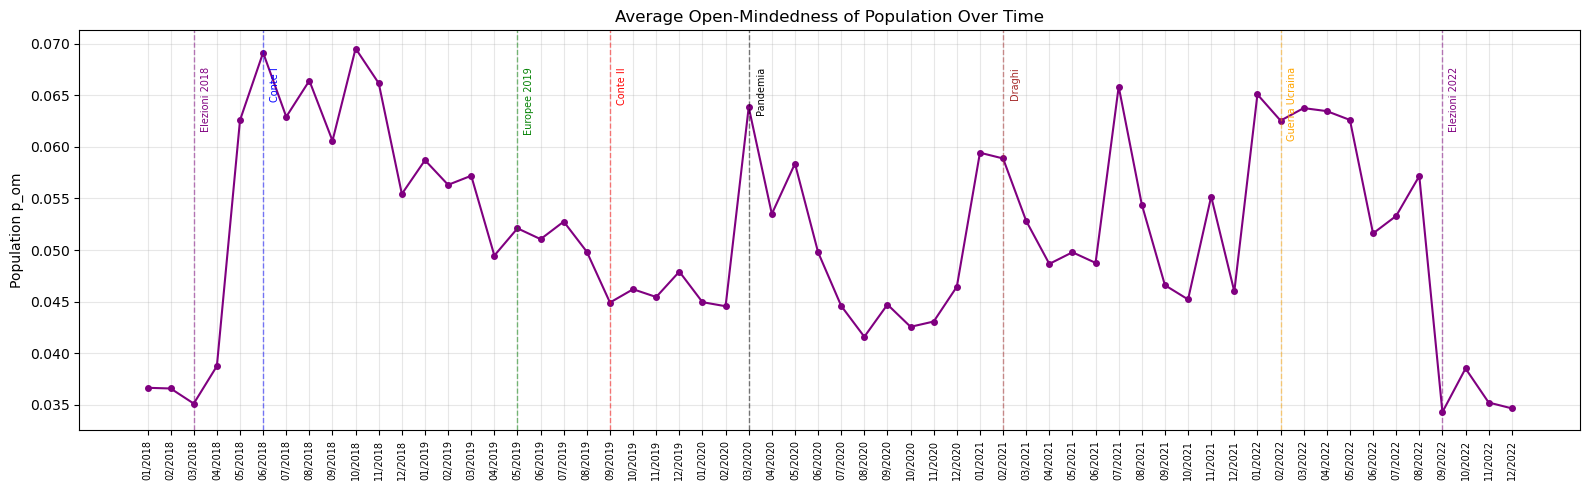

p_om range: [0.0343, 0.0695]


In [ ]:
# --- Tag each quote as open-minded ---
quotes_with_dist['open_minded'] = (
    ((quotes_with_dist['agreement'] > 0) & (quotes_with_dist['distance'] > 2/3))
    |
    ((quotes_with_dist['agreement'] < 0) & (quotes_with_dist['distance'] < 1/3))
)

# --- Per user per month: p_om = fraction of open-minded interactions ---
user_monthly_pom = (
    quotes_with_dist
    .groupby(['reference_author', 'month_year'])['open_minded']
    .mean()
    .reset_index()
    .rename(columns={'open_minded': 'p_om'})
)

# --- Population p_om per month ---
pop_om_series = user_monthly_pom.groupby('month_year')['p_om'].mean()

# --- Plot ---
fig, ax = plt.subplots(figsize=(16, 5))
pom_values = [pop_om_series.get(m, np.nan) for m in all_months]
x = range(len(all_months))

ax.plot(x, pom_values, 'o-', color='purple', markersize=4)
ax.set_xticks(x)
ax.set_xticklabels(all_months, rotation=90, fontsize=7)
ax.set_ylabel('Population p_om')
ax.set_title('Average Open-Mindedness of Population Over Time')
ax.grid(alpha=0.3)
plt.tight_layout()

# Event lines
month_to_x = {m: i for i, m in enumerate(all_months)}
ymax = ax.get_ylim()[1]
for event_date, label in events.items():
    month_key = event_date
    if month_key in month_to_x:
        xi = month_to_x[month_key]
        color = event_colors.get(label, 'red')
        ax.axvline(xi, color=color, alpha=0.5, linestyle='--', linewidth=1)
        ax.text(xi + 0.3, ymax * 0.95, label, rotation=90, va='top', fontsize=7, color=color)
plt.show()

print(f"p_om range: [{min(pom_values):.4f}, {max(pom_values):.4f}]")

## 6. Robustness Analysis

We verify that the temporal dynamics of p_om are robust to the choice of threshold τ. 
We vary τ from 0.5 to 0.8: the shape of the curve is preserved across all thresholds, 
only the absolute magnitude shifts. This confirms that our measure captures a genuine signal, 
not an artifact of the threshold choice.

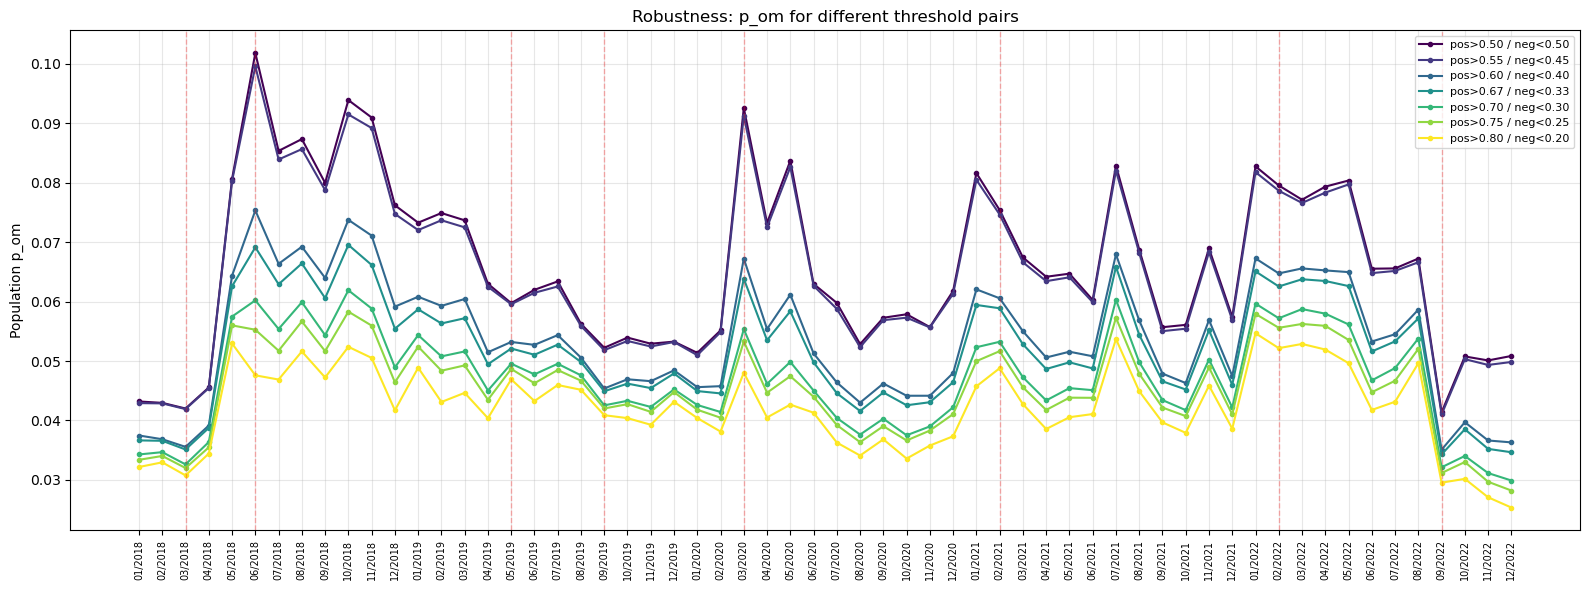

In [ ]:
# --- Robustness analysis: vary thresholds ---
threshold_pairs = [
    (0.5, 0.5),
    (0.55, 0.45),
    (0.6, 0.4),
    (2/3, 1/3),
    (0.7, 0.3),
    (0.75, 0.25),
    (0.8, 0.2),
]

fig, ax = plt.subplots(figsize=(16, 6))
colors = plt.cm.viridis(np.linspace(0, 1, len(threshold_pairs)))

for idx, (t_pos, t_neg) in enumerate(threshold_pairs):
    om_flag = (
        ((quotes_with_dist['agreement'] > 0) & (quotes_with_dist['distance'] > t_pos))
        |
        ((quotes_with_dist['agreement'] < 0) & (quotes_with_dist['distance'] < t_neg))
    )
    
    temp = quotes_with_dist[['reference_author', 'month_year']].copy()
    temp['om'] = om_flag
    
    user_monthly = temp.groupby(['reference_author', 'month_year'])['om'].mean()
    pop_monthly = user_monthly.groupby('month_year').mean()
    
    pom_vals = [pop_monthly.get(m, np.nan) for m in all_months]
    ax.plot(range(len(all_months)), pom_vals, 'o-', color=colors[idx], markersize=3,
            label=f'pos>{t_pos:.2f} / neg<{t_neg:.2f}')

# Event lines
month_to_x = {m: i for i, m in enumerate(all_months)}
for event_date, label in events.items():
    parts = event_date.split('-')
    month_key = event_date
    if month_key in month_to_x:
        ax.axvline(month_to_x[month_key], color='red', alpha=0.3, linestyle='--', linewidth=1)

ax.set_xticks(range(len(all_months)))
ax.set_xticklabels(all_months, rotation=90, fontsize=7)
ax.set_ylabel('Population p_om')
ax.set_title('Robustness: p_om for different threshold pairs')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Mild Source Fraction (m)



In [ ]:
# === CELLA 1: Sostituisce la vecchia cella b4ae9a26 (sezione 7) ===

# --- 1. Define sources ---
source_ids = all_leader_ids - politici_ids
print(f"Sources (non-politician leaders): {len(source_ids)}")

# --- 2. RT normal users → sources (con opinion vector) ---
rt_u2s = twitter_it_retweets[
    (twitter_it_retweets['reference_type'] == 'retweeted') &
    (~twitter_it_retweets['reference_author'].astype(str).str.strip().isin(all_leader_ids)) &
    (twitter_it_retweets['referenced_author'].astype(str).str.strip().isin(source_ids))
].copy()
rt_u2s['reference_author'] = rt_u2s['reference_author'].astype(str).str.strip()
rt_u2s['referenced_author'] = rt_u2s['referenced_author'].astype(str).str.strip()

# Merge con opinion vectors degli utenti
rt_u2s = rt_u2s.merge(
    opinion_vectors_monthly[['reference_author', 'month_year', 'comm_0', 'comm_1', 'comm_2']],
    on=['reference_author', 'month_year'],
    how='inner'
)
print(f"RT con opinion vector: {len(rt_u2s):,}")
print(f"Sources coperte: {rt_u2s['referenced_author'].nunique()}")

# --- 3. Source profiles: media dei vettori opinione di chi le RT ---
source_profiles = (
    rt_u2s
    .groupby(['referenced_author', 'month_year'])[['comm_0', 'comm_1', 'comm_2']]
    .mean()
    .reset_index()
)

# --- 4. Mildness = 1 - dist(profilo, baricentro) / max_dist ---
barycenter = np.ones(3) / 3
max_dist = np.sqrt(np.sum((np.array([1, 0, 0]) - barycenter)**2))

source_profiles['dist_from_bary'] = np.sqrt(
    (source_profiles['comm_0'] - 1/3)**2 +
    (source_profiles['comm_1'] - 1/3)**2 +
    (source_profiles['comm_2'] - 1/3)**2
)
source_profiles['mildness'] = 1 - (source_profiles['dist_from_bary'] / max_dist)

print(f"\nSource-month profiles: {len(source_profiles):,}")
print(f"Mildness range: [{source_profiles['mildness'].min():.3f}, {source_profiles['mildness'].max():.3f}]")
print(f"Mean mildness: {source_profiles['mildness'].mean():.3f}")

# --- 5. Assegna mildness a ogni RT user→source ---
source_mild_lookup = source_profiles.set_index(['referenced_author', 'month_year'])['mildness']

rt_u2s['mildness'] = rt_u2s.set_index(['referenced_author', 'month_year']).index.map(
    lambda x: source_mild_lookup.get(x, np.nan)
)
rt_u2s = rt_u2s.dropna(subset=['mildness'])

# --- 6. m mensile ---
m_monthly_new = rt_u2s.groupby('month_year')['mildness'].mean()
m_vals_new = [m_monthly_new.get(m, np.nan) for m in all_months]


Sources (non-politician leaders): 544
RT con opinion vector: 6,769,695
Sources coperte: 277

Source-month profiles: 6,417
Mildness range: [0.000, 1.000]
Mean mildness: 0.363


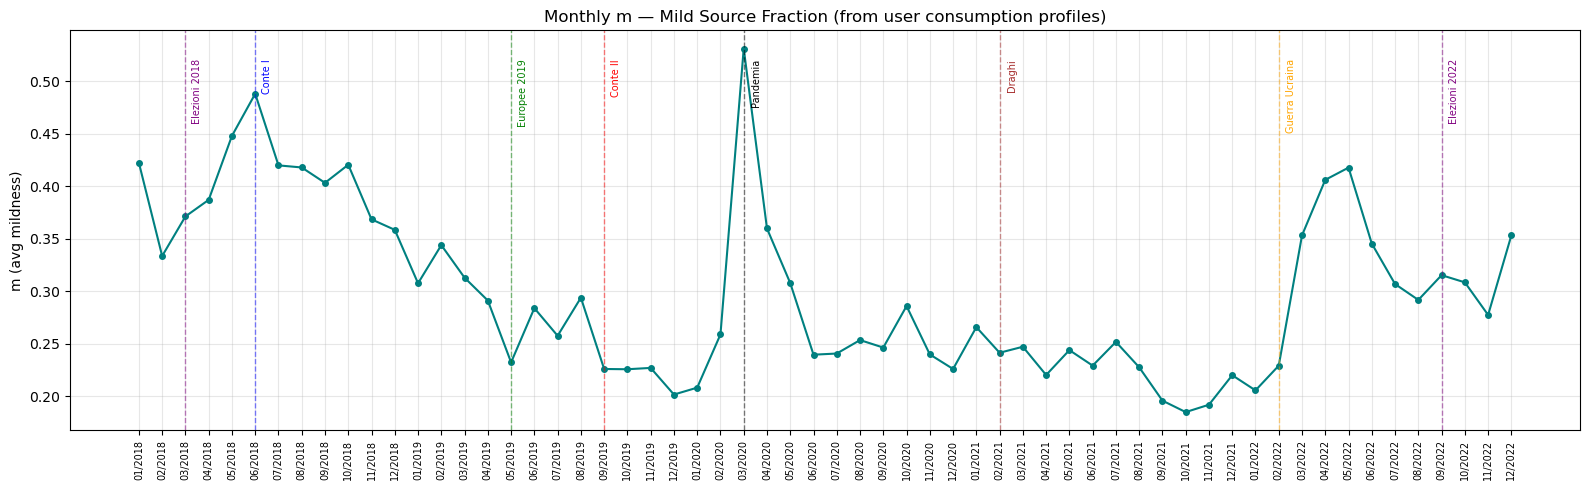

m range: [0.1848, 0.5312]
m vs φ: r=-0.577, p=1.36e-06


In [ ]:

# --- 7. Plot ---
fig, ax = plt.subplots(figsize=(16, 5))
x = range(len(all_months))
ax.plot(x, m_vals_new, 'o-', color='teal', markersize=4)
ax.set_xticks(x)
ax.set_xticklabels(all_months, rotation=90, fontsize=7)
ax.set_ylabel('m (avg mildness)')
ax.set_title('Monthly m — Mild Source Fraction (from user consumption profiles)')
ax.grid(alpha=0.3)

month_to_x = {m: i for i, m in enumerate(all_months)}
ymax = ax.get_ylim()[1]
for event_date, label in events.items():
    month_key = event_date
    if month_key in month_to_x:
        xi = month_to_x[month_key]
        color = event_colors.get(label, 'red')
        ax.axvline(xi, color=color, alpha=0.5, linestyle='--', linewidth=1)
        ax.text(xi + 0.3, ymax * 0.95, label, rotation=90, va='top', fontsize=7, color=color)
plt.tight_layout()
plt.show()

print(f"m range: [{min(v for v in m_vals_new if not np.isnan(v)):.4f}, "
      f"{max(v for v in m_vals_new if not np.isnan(v)):.4f}]")

from scipy.stats import pearsonr
valid_m_phi = [(mv, phi_monthly.get(m, np.nan)) for m, mv in zip(all_months, m_vals_new)]
valid_m_phi = [(mv, pv) for mv, pv in valid_m_phi if not (np.isnan(mv) or np.isnan(pv))]
m_v, phi_v = zip(*valid_m_phi)
r, p = pearsonr(m_v, phi_v)
print(f"m vs φ: r={r:.3f}, p={p:.2e}")





## 8. Analysis of Information Sources

We characterize the information ecosystem by examining which sources are mild (mildness > 0.3) 
and how much engagement they receive compared to polarized sources.

Top 10 fonti MILD (generaliste):
  economyup: 0.669
  corriere: 0.670
  agenzia_italia: 0.671
  la7tv: 0.672
  radioitalia: 0.681
  adnkronos: 0.713
  tgla7: 0.718
  skytg24: 0.744
  agenzia_ansa: 0.795
  reggionline: 0.855

Top 10 fonti POLARIZZATE:
  targatocn: 0.000
  italy4science: 0.000
  ilquaderno: 0.000
  cdsnews: 0.000
  lavoceredazione: 0.000
  lametino: 0.000
  sanremonews: 0.000
  grandangoloag: 0.000
  monzatoday: 0.000
  sicilianews24: 0.000


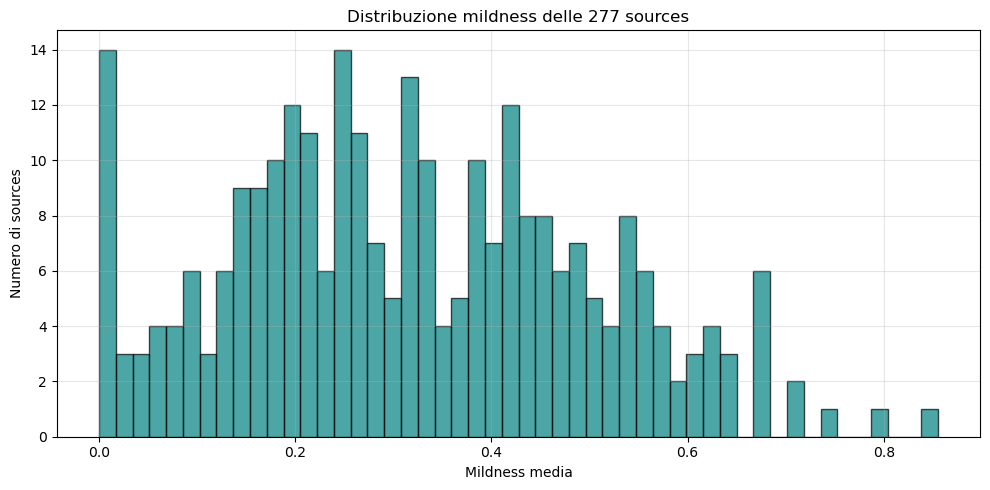

In [ ]:
# === CELLA 2: Sostituisce la vecchia sezione 8 (source analysis) ===

# --- Sanity check: top sources mild e polarizzate ---
avg_mild = source_profiles.groupby('referenced_author')['mildness'].mean().sort_values()

print("Top 10 fonti MILD (generaliste):")
for sid, m in avg_mild.tail(10).items():
    print(f"  {id_to_name.get(sid, sid)}: {m:.3f}")

print("\nTop 10 fonti POLARIZZATE:")
for sid, m in avg_mild.head(10).items():
    print(f"  {id_to_name.get(sid, sid)}: {m:.3f}")

# --- Distribuzione mildness ---
fig, ax = plt.subplots(figsize=(10, 5))
avg_mild.hist(bins=50, ax=ax, color='teal', edgecolor='black', alpha=0.7)
ax.set_xlabel('Mildness media')
ax.set_ylabel('Numero di sources')
ax.set_title(f'Distribuzione mildness delle {len(avg_mild)} sources')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Main Results

### 9.1 Temporal dynamics

We plot the three model quantities (φ, p_om, m) over time, with Italian political events marked.

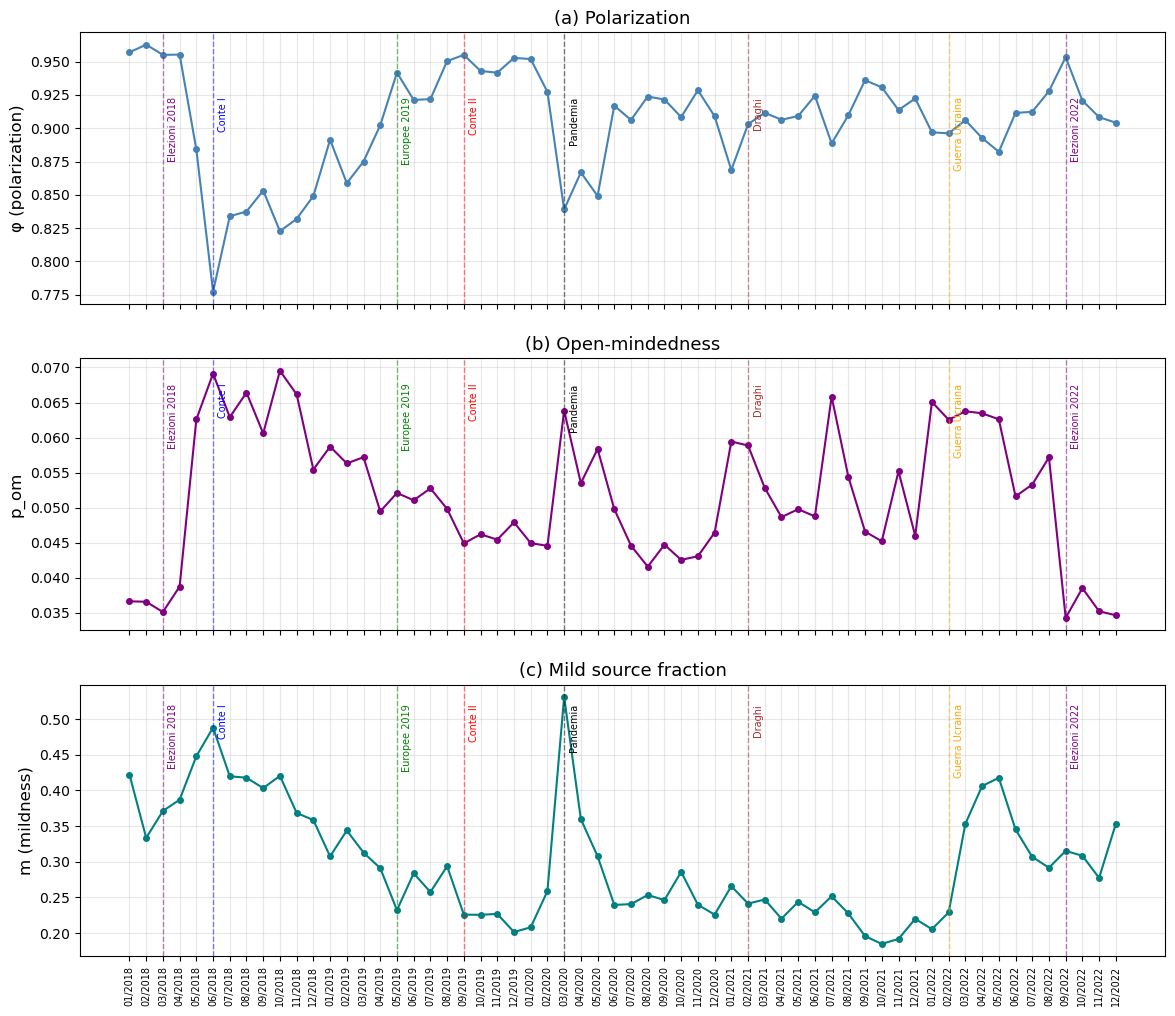

In [ ]:
# === CELLA 3: Sostituisce le figure paper (sezione 9.1) ===

import matplotlib.pyplot as plt
from scipy.stats import pearsonr

months = all_months
x = range(len(months))
phi_vals = [phi_monthly.get(m, np.nan) for m in months]
pom_vals = [pop_om_series.get(m, np.nan) for m in months]
m_vals_ts = [m_monthly_new.get(m, np.nan) for m in months]

def add_events(ax, months, events, event_colors, ypos=None):
    month_to_x = {m: i for i, m in enumerate(months)}
    if ypos is None:
        ypos = ax.get_ylim()[1]
    for event_date, label in events.items():
        month_key = event_date
        if month_key in month_to_x:
            xi = month_to_x[month_key]
            color = event_colors.get(label, 'red')
            ax.axvline(xi, color=color, alpha=0.5, linestyle='--', linewidth=1)
            ax.text(xi + 0.3, ypos * 0.95, label, rotation=90, va='top', fontsize=7, color=color)

# FIGURE 1: Time series (3 panels)
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)

axes[0].plot(x, phi_vals, 'o-', color='steelblue', markersize=4)
axes[0].set_ylabel('φ (polarization)', fontsize=12)
axes[0].set_title('(a) Polarization', fontsize=13)
axes[0].grid(alpha=0.3)
add_events(axes[0], months, events, event_colors)

axes[1].plot(x, pom_vals, 'o-', color='purple', markersize=4)
axes[1].set_ylabel('p_om', fontsize=12)
axes[1].set_title('(b) Open-mindedness', fontsize=13)
axes[1].grid(alpha=0.3)
add_events(axes[1], months, events, event_colors)

axes[2].plot(x, m_vals_ts, 'o-', color='teal', markersize=4)
axes[2].set_ylabel('m (mildness)', fontsize=12)
axes[2].set_title('(c) Mild source fraction', fontsize=13)
axes[2].grid(alpha=0.3)
axes[2].set_xticks(x)
axes[2].set_xticklabels(months, rotation=90, fontsize=7)
add_events(axes[2], months, events, event_colors)

plt.savefig('Fig1_timeseries_IT.png', dpi=300, bbox_inches='tight')
plt.show()

### 9.2 Scatter plots: model predictions

The model predicts that higher p_om should decrease φ (open-mindedness reduces polarization) 
and higher m should decrease φ (mild sources promote consensus). We test both relationships.

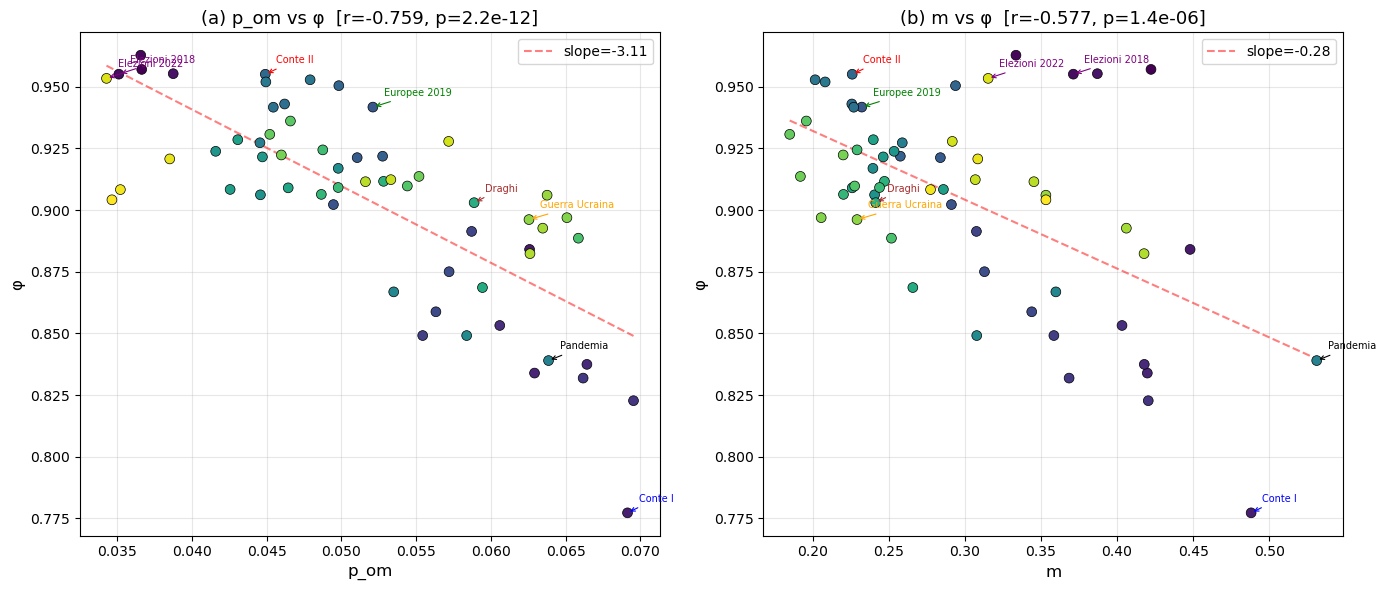

In [ ]:
# === CELLA 4: Scatter plots aggiornati (sezione 9.2) ===

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# (a) p_om vs phi
ax = axes[0]
valid = [(p, phi) for p, phi in zip(pom_vals, phi_vals) if not (np.isnan(p) or np.isnan(phi))]
valid_months_pom = [m for m, p, phi in zip(months, pom_vals, phi_vals) if not (np.isnan(p) or np.isnan(phi))]
pom_v, phi_v = zip(*valid)

colors_s = plt.cm.viridis(np.linspace(0, 1, len(pom_v)))
ax.scatter(pom_v, phi_v, c=colors_s, s=50, edgecolors='black', linewidths=0.5, zorder=3)

for event_date, label in events.items():
    parts = event_date.split('-')
    month_key = event_date
    if month_key in valid_months_pom:
        idx = valid_months_pom.index(month_key)
        ax.annotate(label, (pom_v[idx], phi_v[idx]),
                    textcoords="offset points", xytext=(8, 8), fontsize=7,
                    color=event_colors.get(label, 'red'),
                    arrowprops=dict(arrowstyle='->', color=event_colors.get(label, 'red'), lw=0.8))

z = np.polyfit(pom_v, phi_v, 1)
x_line = np.linspace(min(pom_v), max(pom_v), 100)
ax.plot(x_line, np.poly1d(z)(x_line), 'r--', alpha=0.5, label=f'slope={z[0]:.2f}')
r, pval = pearsonr(pom_v, phi_v)
ax.set_xlabel('p_om', fontsize=12)
ax.set_ylabel('φ', fontsize=12)
ax.set_title(f'(a) p_om vs φ  [r={r:.3f}, p={pval:.1e}]', fontsize=13)
ax.legend()
ax.grid(alpha=0.3)

# (b) m vs phi — NUOVO
ax2 = axes[1]
valid_m = [(mv, phi) for mv, phi in zip(m_vals_ts, phi_vals) if not (np.isnan(mv) or np.isnan(phi))]
valid_m_months = [m for m, mv, phi in zip(months, m_vals_ts, phi_vals) if not (np.isnan(mv) or np.isnan(phi))]
m_v, phi_vm = zip(*valid_m)

colors_s2 = plt.cm.viridis(np.linspace(0, 1, len(m_v)))
ax2.scatter(m_v, phi_vm, c=colors_s2, s=50, edgecolors='black', linewidths=0.5, zorder=3)

for event_date, label in events.items():
    parts = event_date.split('-')
    month_key = event_date
    if month_key in valid_m_months:
        idx = valid_m_months.index(month_key)
        ax2.annotate(label, (m_v[idx], phi_vm[idx]),
                    textcoords="offset points", xytext=(8, 8), fontsize=7,
                    color=event_colors.get(label, 'red'),
                    arrowprops=dict(arrowstyle='->', color=event_colors.get(label, 'red'), lw=0.8))

z2 = np.polyfit(m_v, phi_vm, 1)
x_line2 = np.linspace(min(m_v), max(m_v), 100)
ax2.plot(x_line2, np.poly1d(z2)(x_line2), 'r--', alpha=0.5, label=f'slope={z2[0]:.2f}')
r2, pval2 = pearsonr(m_v, phi_vm)
ax2.set_xlabel('m', fontsize=12)
ax2.set_ylabel('φ', fontsize=12)
ax2.set_title(f'(b) m vs φ  [r={r2:.3f}, p={pval2:.1e}]', fontsize=13)
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('Fig2_scatter_IT.png', dpi=300, bbox_inches='tight')
plt.show()

### 9.3 Multivariate regression

We test whether m adds explanatory power beyond p_om using a linear regression φ ~ p_om + m.

In [ ]:
# === CELLA 5: Regressione multivariata aggiornata (sezione 9.3) ===

from sklearn.linear_model import LinearRegression

data = []
for month in all_months:
    phi_v = phi_monthly.get(month, np.nan)
    pom_v = pop_om_series.get(month, np.nan)
    m_v = m_monthly_new.get(month, np.nan)
    if not any(np.isnan([phi_v, pom_v, m_v])):
        data.append((pom_v, m_v, phi_v))

data = np.array(data)
X = data[:, :2]
y = data[:, 2]

reg = LinearRegression().fit(X, y)
print(f"φ = {reg.coef_[0]:.2f}·p_om + {reg.coef_[1]:.2f}·m + {reg.intercept_:.2f}")
print(f"R² (p_om + m) = {reg.score(X, y):.4f}")

reg1 = LinearRegression().fit(data[:, 0:1], y)
r2_pom = reg1.score(data[:, 0:1], y)
print(f"R² (solo p_om) = {r2_pom:.4f}")

reg2 = LinearRegression().fit(data[:, 1:2], y)
print(f"R² (solo m) = {reg2.score(data[:, 1:2], y):.4f}")

print(f"\nΔR² da m (oltre p_om) = {reg.score(X, y) - r2_pom:.4f}")

φ = -2.59·p_om + -0.17·m + 1.09
R² (p_om + m) = 0.6838
R² (solo p_om) = 0.5758
R² (solo m) = 0.3334

ΔR² da m (oltre p_om) = 0.1080


## 10. Summary of Results

1. **φ, p_om, and m are all measurable** from real Twitter data.

2. **p_om vs φ: strong negative correlation** (r = −0.76, p < 10⁻¹²).  
   The model's prediction — more open-mindedness reduces polarization — holds strongly.

3. **m vs φ: significant negative correlation** (r = −0.58, p = 10⁻⁶).  
   The model's prediction — more mild sources reduce polarization — is confirmed.  
   Previous null result (r ≈ 0) was due to a coverage bug: only 17/544 sources had mildness estimates.  
   The corrected method computes source mildness from the opinion profile of users who retweet the source, covering 277 sources and 6.7M interactions.

4. **Multivariate regression**: φ = −2.59·p_om − 0.17·m + 1.09 (R² = 0.68).  
   Both levers contribute: p_om alone explains 58% of variance, m adds 11%.

5. **Robustness:** the p_om signal is stable across threshold choices (τ = 0.5 to 0.8).

6. **Mild sources** are mainstream generalist media (ANSA, SkyTG24, TgLa7, Corriere, Adnkronos, Repubblica).  
   Polarized sources are small local/niche outlets consumed by a single political community.

### Intervention implications

The model identifies two levers to reduce polarization, and the data confirms both are active:
- **Increase p_om**: platform design that promotes cross-camp dialogue
- **Increase m**: algorithmic amplification of generalist, multi-audience media sources

# MOBILITY ANALYSIS

Computing displacement sequences...
Displacement records: 411,644
Turning records: 89,310
Users with ≥2 observations: 50,877


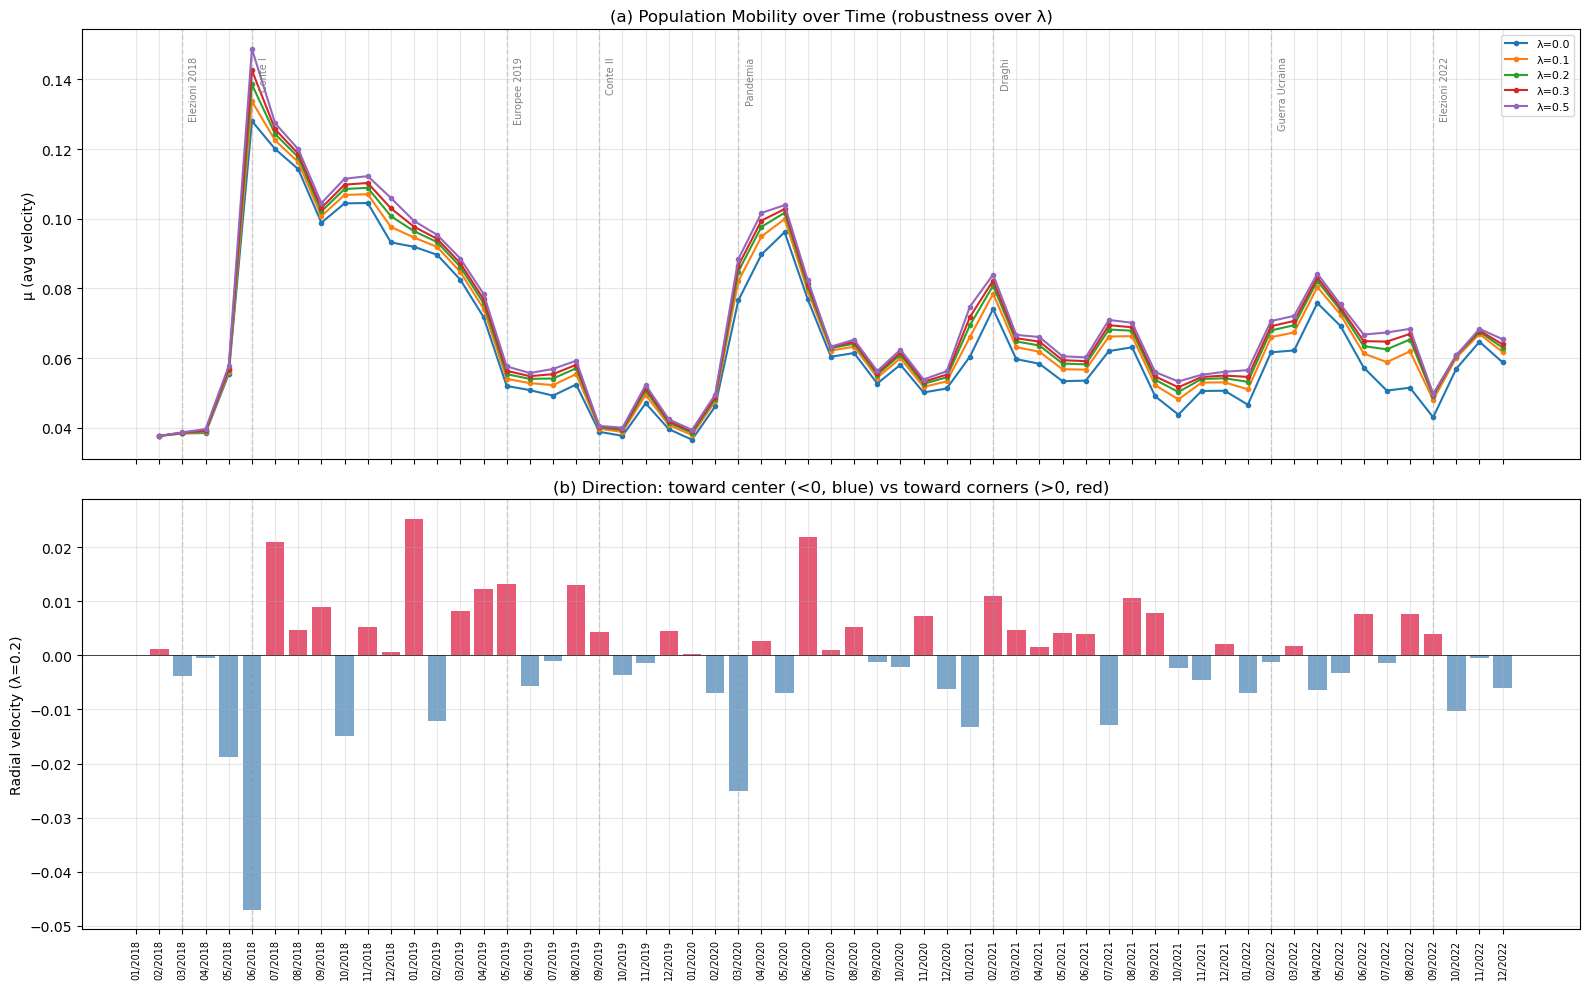

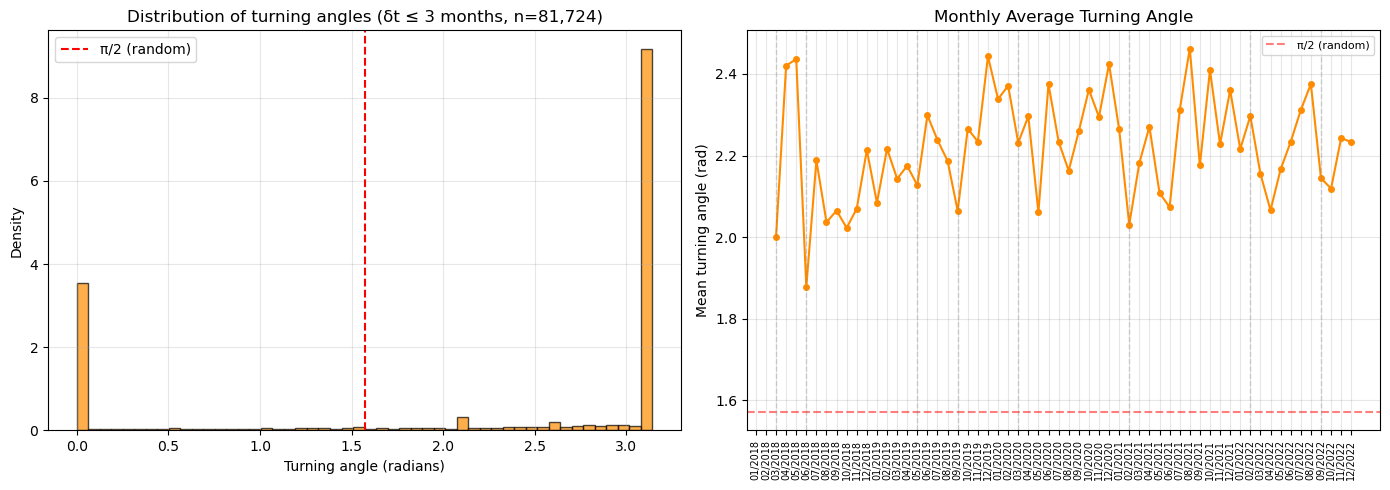


CORRELATIONS: mobility measures vs φ
  Mobility (λ=0.2) vs φ:    r=-0.924, p=1.64e-25
  Radial velocity vs Δφ:         r=0.958, p=1.51e-32
  Turning angle vs φ:            r=0.409, p=1.45e-03
  Mobility (λ=0.2) vs p_om: r=0.685, p=2.25e-09


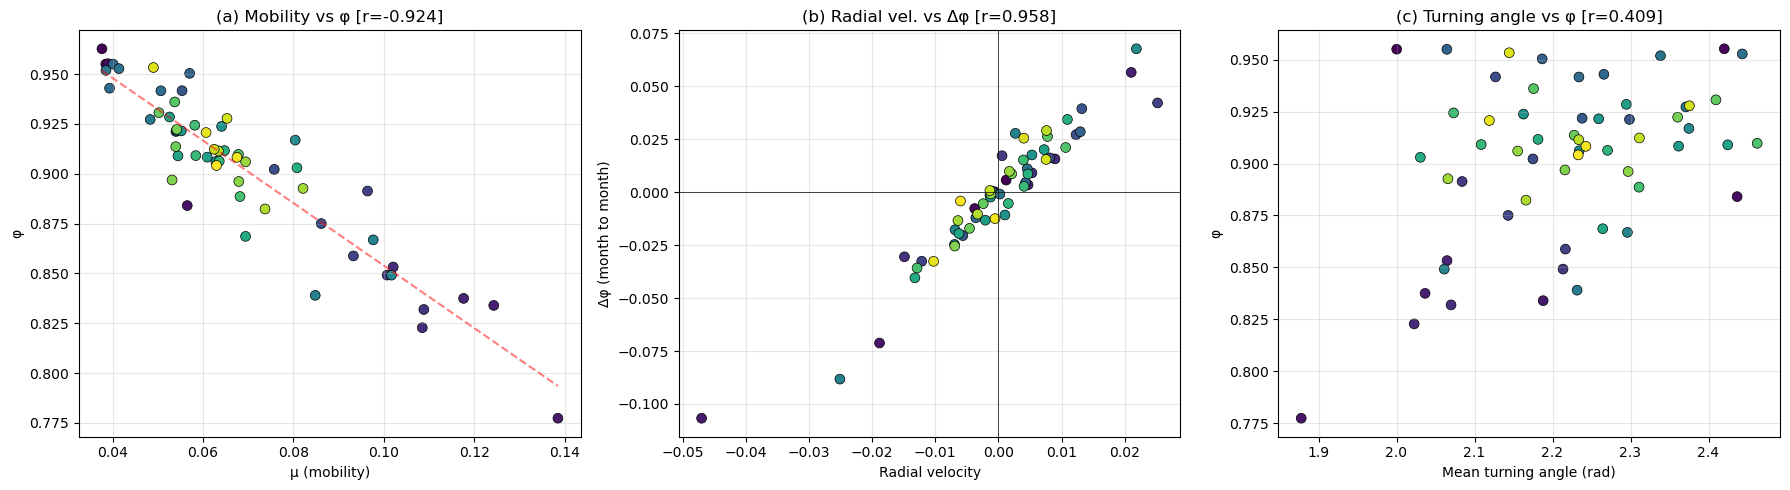


INTERPRETATION GUIDE

Mobility μ:
  High μ → agents are actively moving on the simplex (dynamic system)
  Low μ  → agents are stuck (frozen polarization or stable consensus)

Radial velocity:
  > 0 → population drifting AWAY from center (toward polarization)
  < 0 → population drifting TOWARD center (toward consensus)
  ≈ 0 → no net radial drift (equilibrium or cancellation)

Turning angle:
  ≈ 0    → persistent motion (agents keep moving in same direction)
  ≈ π/2  → random walk (no directional memory)
  ≈ π    → oscillatory/reversal (agents bouncing back and forth)



In [ ]:
# =============================================================================
# Agent Mobility on the Simplex
# =============================================================================
#
# For each user i with opinion vectors at times t_1 < t_2 < ... < t_n:
#
#   Velocity:     v_k = ||Δx_k|| / δ_k       (displacement per month)
#   Mobility:     μ_i = Σ w_k v_k / Σ w_k    (exponentially weighted avg velocity)
#                 w_k = exp(-λ · δ_k)
#
# Direction analysis:
#   - Radial component: projection of Δx_k onto (x_k - b) direction
#     > 0 → moving AWAY from center (toward polarization)
#     < 0 → moving TOWARD center (toward consensus)
#   - Angular change: angle between consecutive Δx vectors (turning)
#
# =============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# --- 0. Parse month_year to ordinal for time gaps ---
def month_year_to_ordinal(my_str):
    """Convert 'MM/YYYY' to integer months since 01/2018."""
    parts = my_str.split('/')
    return (int(parts[1]) - 2018) * 12 + int(parts[0])

# --- 1. Sort opinion vectors by user and time ---
ov = opinion_vectors_monthly.copy()
ov['t_ord'] = ov['month_year'].apply(month_year_to_ordinal)
ov = ov.sort_values(['reference_author', 't_ord'])

# --- 2. Compute per-user displacement sequences ---
print("Computing displacement sequences...")

barycenter = np.ones(3) / 3

records = []  # (user, month_year, t_ord, velocity, radial_velocity, delta_t)
turning_records = []  # (user, month_year, turning_angle)

for user, group in ov.groupby('reference_author'):
    if len(group) < 2:
        continue

    vecs = group[['comm_0', 'comm_1', 'comm_2']].values
    times = group['t_ord'].values
    months = group['month_year'].values

    prev_displacement = None

    for k in range(1, len(vecs)):
        dx = vecs[k] - vecs[k-1]
        dt = times[k] - times[k-1]

        if dt <= 0:
            continue

        displacement_norm = np.linalg.norm(dx)
        velocity = displacement_norm / dt

        # Radial component: project displacement onto radial direction (from barycenter)
        # Radial direction at midpoint
        midpoint = (vecs[k] + vecs[k-1]) / 2
        radial_dir = midpoint - barycenter
        radial_norm = np.linalg.norm(radial_dir)
        if radial_norm > 1e-10:
            radial_velocity = np.dot(dx, radial_dir / radial_norm) / dt
        else:
            radial_velocity = 0.0

        records.append((user, months[k], times[k], velocity, radial_velocity, dt))

        # Turning angle between consecutive displacements
        if prev_displacement is not None and np.linalg.norm(prev_displacement) > 1e-10 and displacement_norm > 1e-10:
            cos_angle = np.dot(prev_displacement, dx) / (np.linalg.norm(prev_displacement) * displacement_norm)
            cos_angle = np.clip(cos_angle, -1, 1)
            angle = np.arccos(cos_angle)  # in radians [0, π]
            turning_records.append((user, months[k], angle, dt))

        prev_displacement = dx

df_disp = pd.DataFrame(records, columns=['user', 'month_year', 't_ord', 'velocity', 'radial_velocity', 'delta_t'])
df_turn = pd.DataFrame(turning_records, columns=['user', 'month_year', 'angle', 'delta_t'])

print(f"Displacement records: {len(df_disp):,}")
print(f"Turning records: {len(df_turn):,}")
print(f"Users with ≥2 observations: {df_disp['user'].nunique():,}")

# --- 3. Exponentially weighted mobility per user per month ---
def weighted_mobility(group, lam):
    """Compute exponential-decay-weighted average velocity for a group of displacements."""
    weights = np.exp(-lam * group['delta_t'].values)
    velocities = group['velocity'].values
    if weights.sum() < 1e-10:
        return np.nan
    return np.average(velocities, weights=weights)

# --- 4. Population-level monthly mobility for multiple λ ---
lambdas = [0.0, 0.1, 0.2, 0.3, 0.5]

fig, axes = plt.subplots(2, 1, figsize=(16, 10), sharex=True)

# Panel (a): Total mobility (speed) for different λ
ax = axes[0]
mobility_series = {}

for lam in lambdas:
    # Weight each record
    df_disp['weight'] = np.exp(-lam * df_disp['delta_t'])
    df_disp['weighted_v'] = df_disp['velocity'] * df_disp['weight']

    # Monthly population mobility: weighted mean of velocities
    monthly = df_disp.groupby('month_year').apply(
        lambda g: g['weighted_v'].sum() / g['weight'].sum() if g['weight'].sum() > 0 else np.nan
    )

    mobility_series[lam] = monthly
    vals = [monthly.get(m, np.nan) for m in all_months]
    ax.plot(range(len(all_months)), vals, 'o-', markersize=3, label=f'λ={lam}')

ax.set_ylabel('μ (avg velocity)')
ax.set_title('(a) Population Mobility over Time (robustness over λ)')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

# Add events
month_to_x = {m: i for i, m in enumerate(all_months)}
ymax = ax.get_ylim()[1]
for event_date, label in events.items():
    parts = event_date.split('-')
    month_key = event_date
    if month_key in month_to_x:
        xi = month_to_x[month_key]
        ax.axvline(xi, color='gray', alpha=0.3, linestyle='--', linewidth=1)
        ax.text(xi + 0.3, ymax * 0.95, label, rotation=90, va='top', fontsize=7, color='gray')

# Panel (b): Radial velocity (toward center < 0, away from center > 0)
ax2 = axes[1]

# Use λ=0.2 as default
lam_default = 0.2
df_disp['weight'] = np.exp(-lam_default * df_disp['delta_t'])
df_disp['weighted_rv'] = df_disp['radial_velocity'] * df_disp['weight']

monthly_radial = df_disp.groupby('month_year').apply(
    lambda g: g['weighted_rv'].sum() / g['weight'].sum() if g['weight'].sum() > 0 else np.nan
)

rv_vals = [monthly_radial.get(m, np.nan) for m in all_months]
colors_rv = ['crimson' if v > 0 else 'steelblue' for v in rv_vals]
ax2.bar(range(len(all_months)), rv_vals, color=colors_rv, alpha=0.7, width=0.8)
ax2.axhline(0, color='black', linewidth=0.5)
ax2.set_ylabel('Radial velocity (λ=0.2)')
ax2.set_title('(b) Direction: toward center (<0, blue) vs toward corners (>0, red)')
ax2.set_xticks(range(len(all_months)))
ax2.set_xticklabels(all_months, rotation=90, fontsize=7)
ax2.grid(alpha=0.3)

# Events
ymax2 = max(abs(ax2.get_ylim()[0]), abs(ax2.get_ylim()[1]))
for event_date, label in events.items():
    parts = event_date.split('-')
    month_key = event_date
    if month_key in month_to_x:
        xi = month_to_x[month_key]
        ax2.axvline(xi, color='gray', alpha=0.3, linestyle='--', linewidth=1)

plt.tight_layout()
plt.savefig('Fig_mobility_timeseries.png', dpi=300, bbox_inches='tight')
plt.show()

# --- 5. Turning angle analysis ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (a) Distribution of turning angles
ax = axes[0]
# Filter: only consider turns where delta_t ≤ 3 months (to avoid meaningless long-gap turns)
turns_close = df_turn[df_turn['delta_t'] <= 3]
ax.hist(turns_close['angle'].values, bins=50, density=True, color='darkorange', edgecolor='black', alpha=0.7)
ax.axvline(np.pi/2, color='red', linestyle='--', label='π/2 (random)')
ax.set_xlabel('Turning angle (radians)')
ax.set_ylabel('Density')
ax.set_title(f'Distribution of turning angles (δt ≤ 3 months, n={len(turns_close):,})')
ax.legend()
ax.grid(alpha=0.3)

# (b) Monthly average turning angle
ax2 = axes[1]
monthly_turn = turns_close.groupby('month_year')['angle'].mean()
turn_vals = [monthly_turn.get(m, np.nan) for m in all_months]
ax2.plot(range(len(all_months)), turn_vals, 'o-', color='darkorange', markersize=4)
ax2.axhline(np.pi/2, color='red', linestyle='--', alpha=0.5, label='π/2 (random)')
ax2.set_xticks(range(len(all_months)))
ax2.set_xticklabels(all_months, rotation=90, fontsize=7)
ax2.set_ylabel('Mean turning angle (rad)')
ax2.set_title('Monthly Average Turning Angle')
ax2.legend(fontsize=8)
ax2.grid(alpha=0.3)

for event_date, label in events.items():
    parts = event_date.split('-')
    month_key = event_date
    if month_key in month_to_x:
        xi = month_to_x[month_key]
        ax2.axvline(xi, color='gray', alpha=0.3, linestyle='--', linewidth=1)

plt.tight_layout()
plt.savefig('Fig_turning_angles.png', dpi=300, bbox_inches='tight')
plt.show()

# --- 6. Correlations with φ ---
print("\n" + "="*60)
print("CORRELATIONS: mobility measures vs φ")
print("="*60)

# Mobility (λ=0.2) vs φ
lam_report = 0.2
mob_vals = [mobility_series[lam_report].get(m, np.nan) for m in all_months]
phi_vals_list = [phi_monthly.get(m, np.nan) for m in all_months]

valid = [(a, b) for a, b in zip(mob_vals, phi_vals_list) if not (np.isnan(a) or np.isnan(b))]
if valid:
    a, b = zip(*valid)
    r, p = pearsonr(a, b)
    print(f"  Mobility (λ={lam_report}) vs φ:    r={r:.3f}, p={p:.2e}")

# Radial velocity vs Δφ (does radial movement predict CHANGE in polarization?)
dphi = [phi_vals_list[i] - phi_vals_list[i-1] if i > 0 and not (np.isnan(phi_vals_list[i]) or np.isnan(phi_vals_list[i-1])) else np.nan for i in range(len(all_months))]
valid_rv = [(a, b) for a, b in zip(rv_vals, dphi) if not (np.isnan(a) or np.isnan(b))]
if valid_rv:
    a, b = zip(*valid_rv)
    r, p = pearsonr(a, b)
    print(f"  Radial velocity vs Δφ:         r={r:.3f}, p={p:.2e}")

# Turning angle vs φ
valid_ta = [(a, b) for a, b in zip(turn_vals, phi_vals_list) if not (np.isnan(a) or np.isnan(b))]
if valid_ta:
    a, b = zip(*valid_ta)
    r, p = pearsonr(a, b)
    print(f"  Turning angle vs φ:            r={r:.3f}, p={p:.2e}")

# Mobility vs p_om
pom_vals_list = [pop_om_series.get(m, np.nan) for m in all_months]
valid_mp = [(a, b) for a, b in zip(mob_vals, pom_vals_list) if not (np.isnan(a) or np.isnan(b))]
if valid_mp:
    a, b = zip(*valid_mp)
    r, p = pearsonr(a, b)
    print(f"  Mobility (λ={lam_report}) vs p_om: r={r:.3f}, p={p:.2e}")

# --- 7. Scatter: mobility vs φ, radial velocity vs Δφ ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# (a) Mobility vs φ
ax = axes[0]
valid = [(a, b, m) for a, b, m in zip(mob_vals, phi_vals_list, all_months) if not (np.isnan(a) or np.isnan(b))]
if valid:
    a, b, ms = zip(*valid)
    colors_s = plt.cm.viridis(np.linspace(0, 1, len(a)))
    ax.scatter(a, b, c=colors_s, s=50, edgecolors='black', linewidths=0.5)
    z = np.polyfit(a, b, 1)
    xl = np.linspace(min(a), max(a), 100)
    ax.plot(xl, np.poly1d(z)(xl), 'r--', alpha=0.5)
    r, p = pearsonr(a, b)
    ax.set_title(f'(a) Mobility vs φ [r={r:.3f}]')
ax.set_xlabel('μ (mobility)')
ax.set_ylabel('φ')
ax.grid(alpha=0.3)

# (b) Radial velocity vs Δφ
ax2 = axes[1]
valid = [(a, b) for a, b in zip(rv_vals, dphi) if not (np.isnan(a) or np.isnan(b))]
if valid:
    a, b = zip(*valid)
    colors_s = plt.cm.viridis(np.linspace(0, 1, len(a)))
    ax2.scatter(a, b, c=colors_s, s=50, edgecolors='black', linewidths=0.5)
    ax2.axhline(0, color='black', linewidth=0.5)
    ax2.axvline(0, color='black', linewidth=0.5)
    r, p = pearsonr(a, b)
    ax2.set_title(f'(b) Radial vel. vs Δφ [r={r:.3f}]')
ax2.set_xlabel('Radial velocity')
ax2.set_ylabel('Δφ (month to month)')
ax2.grid(alpha=0.3)

# (c) Turning angle vs φ
ax3 = axes[2]
valid = [(a, b) for a, b in zip(turn_vals, phi_vals_list) if not (np.isnan(a) or np.isnan(b))]
if valid:
    a, b = zip(*valid)
    colors_s = plt.cm.viridis(np.linspace(0, 1, len(a)))
    ax3.scatter(a, b, c=colors_s, s=50, edgecolors='black', linewidths=0.5)
    r, p = pearsonr(a, b)
    ax3.set_title(f'(c) Turning angle vs φ [r={r:.3f}]')
ax3.set_xlabel('Mean turning angle (rad)')
ax3.set_ylabel('φ')
ax3.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('Fig_mobility_scatter.png', dpi=300, bbox_inches='tight')
plt.show()

# --- 8. Summary ---
print("\n" + "="*60)
print("INTERPRETATION GUIDE")
print("="*60)
print("""
Mobility μ:
  High μ → agents are actively moving on the simplex (dynamic system)
  Low μ  → agents are stuck (frozen polarization or stable consensus)

Radial velocity:
  > 0 → population drifting AWAY from center (toward polarization)
  < 0 → population drifting TOWARD center (toward consensus)
  ≈ 0 → no net radial drift (equilibrium or cancellation)

Turning angle:
  ≈ 0    → persistent motion (agents keep moving in same direction)
  ≈ π/2  → random walk (no directional memory)
  ≈ π    → oscillatory/reversal (agents bouncing back and forth)
""")

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def month_to_quarter(m):
    mm, yyyy = m.split('/')
    q = (int(mm) - 1) // 3 + 1
    return f"{yyyy}Q{q}"

df_disp_q = df_disp.copy()
df_disp_q['quarter'] = df_disp_q['month_year'].map(month_to_quarter)

all_quarters = sorted(df_disp_q['quarter'].unique(), key=lambda q: (int(q[:4]), int(q[-1])))
event_quarters = {month_to_quarter(m): label for m, label in events_lines.items()}

is_om = df_disp_q['user'].isin(om_cohort)
disp_om = df_disp_q[is_om]
disp_rest = df_disp_q[~is_om]

def quarterly_mobility(df):
    g = df.groupby('quarter')
    return pd.DataFrame({
        'mean_v':  g['velocity'].mean(),
        'sem_v':   g['velocity'].sem(),
        'mean_rv': g['radial_velocity'].mean(),
        'sem_rv':  g['radial_velocity'].sem(),
        'n':       g.size(),
    }).reindex(all_quarters)

agg_om  = quarterly_mobility(disp_om)
agg_rest = quarterly_mobility(disp_rest)

x = range(len(all_quarters))
fig, axes = plt.subplots(2, 1, figsize=(16, 10), sharex=True)

# --- Mobilità (velocità totale) ---
axes[0].errorbar(x, agg_om['mean_v'], yerr=agg_om['sem_v'], fmt='o-', color='purple',
                  markersize=4, capsize=3, label='Coorte open-minded')
axes[0].errorbar(x, agg_rest['mean_v'], yerr=agg_rest['sem_v'], fmt='o-', color='gray',
                  markersize=4, capsize=3, label='Resto popolazione', alpha=0.7)
axes[0].set_ylabel('μ (mobilità)')
axes[0].set_title('Mobilità individuale: coorte open-minded vs resto, per trimestre')
axes[0].legend()
axes[0].grid(alpha=0.3)

# --- Velocità radiale (direzione: verso vertice > 0, verso centro < 0) ---
axes[1].errorbar(x, agg_om['mean_rv'], yerr=agg_om['sem_rv'], fmt='o-', color='purple',
                  markersize=4, capsize=3, label='Coorte open-minded')
axes[1].errorbar(x, agg_rest['mean_rv'], yerr=agg_rest['sem_rv'], fmt='o-', color='gray',
                  markersize=4, capsize=3, label='Resto popolazione', alpha=0.7)
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set_ylabel('Velocità radiale')
axes[1].set_title('Direzione: verso il vertice (>0) o verso il centro (<0), per trimestre')
axes[1].legend()
axes[1].grid(alpha=0.3)

for ax in axes:
    ymax = ax.get_ylim()[1]
    for q, label in event_quarters.items():
        if q in all_quarters:
            xi = all_quarters.index(q)
            ax.axvline(xi, color='red', alpha=0.5, linestyle='--', linewidth=1)
            ax.text(xi + 0.1, ymax * 0.95, label, rotation=90, fontsize=7, color='red', va='top')

axes[1].set_xticks(x)
axes[1].set_xticklabels(all_quarters, rotation=90, fontsize=7)
plt.tight_layout()
plt.show()

print(pd.DataFrame({'v_om': agg_om['mean_v'], 'v_rest': agg_rest['mean_v'],
                     'rv_om': agg_om['mean_rv'], 'rv_rest': agg_rest['mean_rv']}))

NameError: name 'om_cohort' is not defined

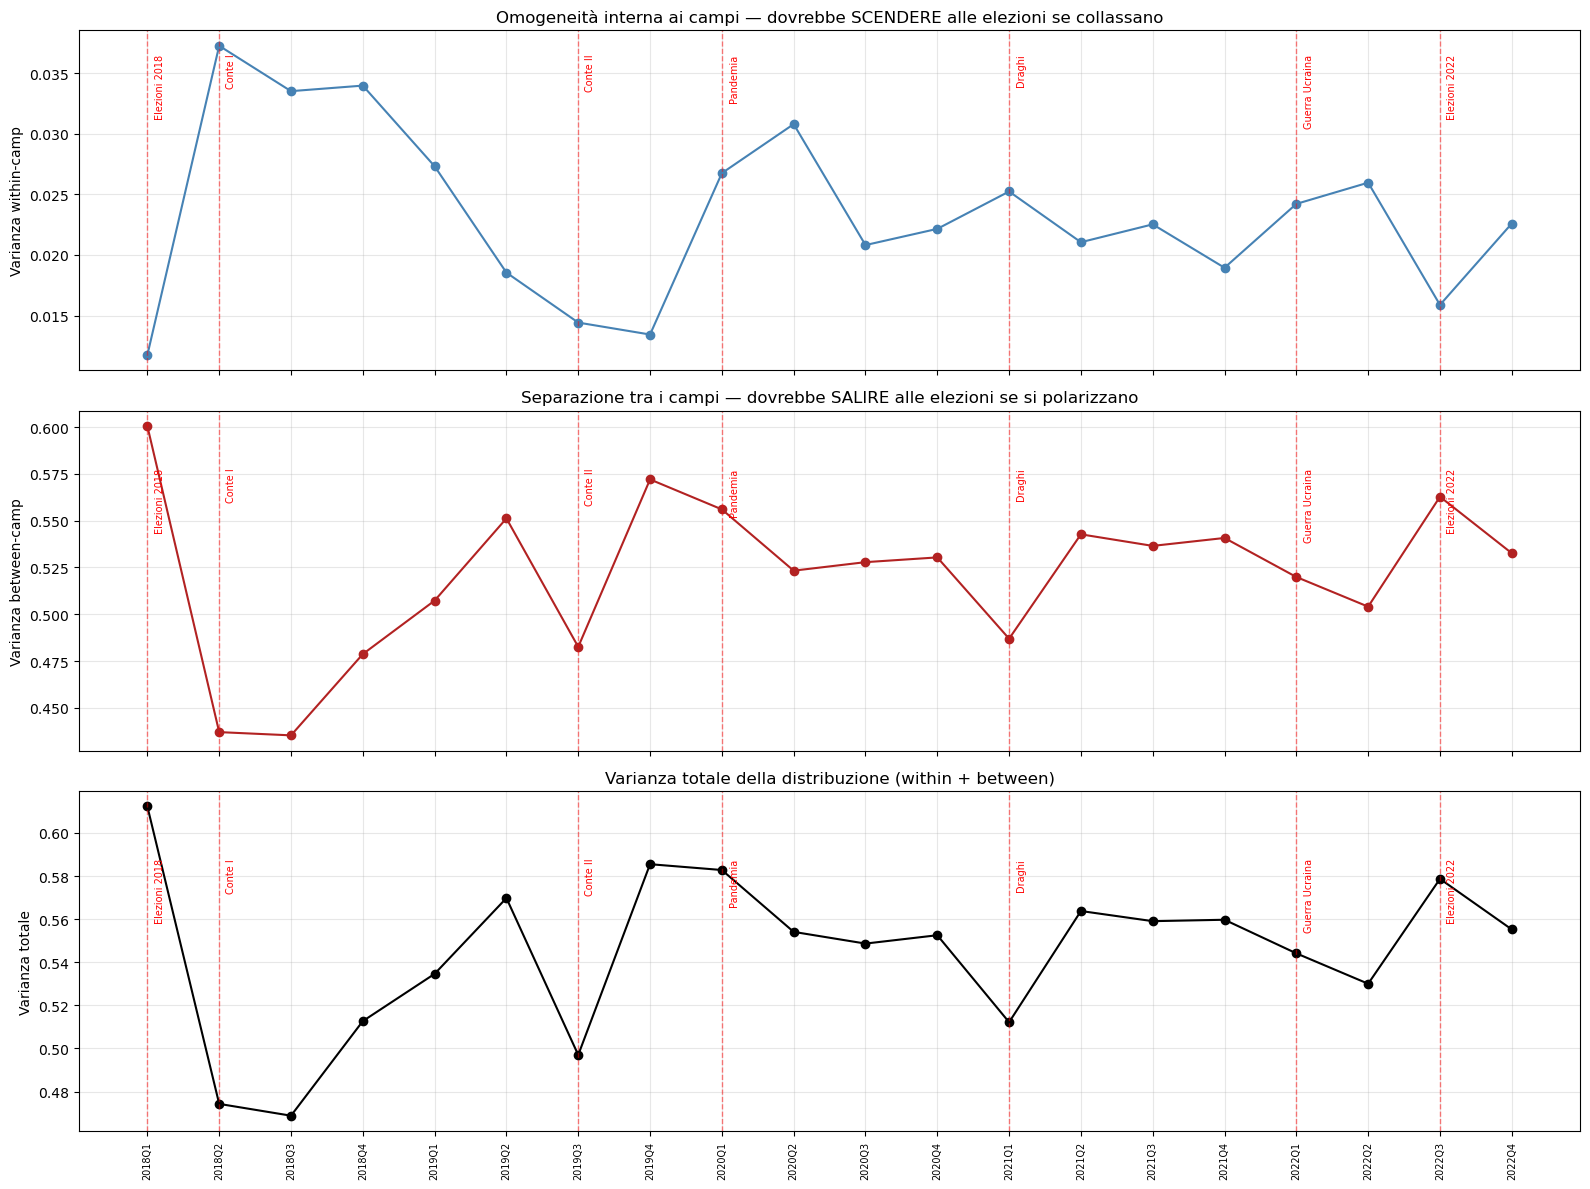

         total_var  within_var  between_var      n
quarter                                           
2018Q1    0.612260    0.011748     0.600512  14705
2018Q2    0.474265    0.037257     0.437008  15972
2018Q3    0.468792    0.033515     0.435277  25601
2018Q4    0.512669    0.033972     0.478697  28159
2019Q1    0.534601    0.027319     0.507282  24222
2019Q2    0.569759    0.018546     0.551213  22797
2019Q3    0.496978    0.014423     0.482555  31436
2019Q4    0.585476    0.013438     0.572037  30060
2020Q1    0.582776    0.026750     0.556025  35050
2020Q2    0.554075    0.030793     0.523281  37005
2020Q3    0.548644    0.020817     0.527827  28548
2020Q4    0.552521    0.022155     0.530366  19340
2021Q1    0.512161    0.025238     0.486923  22948
2021Q2    0.563752    0.021053     0.542699  21962
2021Q3    0.559046    0.022527     0.536519  19024
2021Q4    0.559700    0.018947     0.540753  18173
2022Q1    0.544113    0.024215     0.519898  19101
2022Q2    0.530011    0.025966 

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def month_to_quarter(m):
    mm, yyyy = m.split('/')
    q = (int(mm) - 1) // 3 + 1
    return f"{yyyy}Q{q}"

ov = opinion_vectors_monthly.copy()
ov['quarter'] = ov['month_year'].map(month_to_quarter)

comm_cols = ['comm_0', 'comm_1', 'comm_2']
ov['camp'] = ov[comm_cols].values.argmax(axis=1)  # campo più vicino

all_quarters = sorted(ov['quarter'].unique(), key=lambda q: (int(q[:4]), int(q[-1])))
event_quarters = {month_to_quarter(m): label for m, label in events_lines.items()}

records = []
for q, g in ov.groupby('quarter'):
    X = g[comm_cols].values
    grand_mean = X.mean(axis=0)
    total_var = np.mean(np.sum((X - grand_mean)**2, axis=1))

    within, between, n_tot = 0.0, 0.0, len(g)
    for camp, gc in g.groupby('camp'):
        Xc = gc[comm_cols].values
        n_c = len(Xc)
        mean_c = Xc.mean(axis=0)
        within += n_c * np.mean(np.sum((Xc - mean_c)**2, axis=1))
        between += n_c * np.sum((mean_c - grand_mean)**2)
    within /= n_tot
    between /= n_tot

    records.append({'quarter': q, 'total_var': total_var, 'within_var': within,
                     'between_var': between, 'n': n_tot})

var_decomp = pd.DataFrame(records).set_index('quarter').reindex(all_quarters)

x = range(len(all_quarters))
fig, axes = plt.subplots(3, 1, figsize=(16, 12), sharex=True)

axes[0].plot(x, var_decomp['within_var'], 'o-', color='steelblue')
axes[0].set_ylabel('Varianza within-camp')
axes[0].set_title('Omogeneità interna ai campi — dovrebbe SCENDERE alle elezioni se collassano')
axes[0].grid(alpha=0.3)

axes[1].plot(x, var_decomp['between_var'], 'o-', color='firebrick')
axes[1].set_ylabel('Varianza between-camp')
axes[1].set_title('Separazione tra i campi — dovrebbe SALIRE alle elezioni se si polarizzano')
axes[1].grid(alpha=0.3)

axes[2].plot(x, var_decomp['total_var'], 'o-', color='black')
axes[2].set_ylabel('Varianza totale')
axes[2].set_title('Varianza totale della distribuzione (within + between)')
axes[2].grid(alpha=0.3)

for ax in axes:
    ymax = ax.get_ylim()[1]
    for q, label in event_quarters.items():
        if q in all_quarters:
            xi = all_quarters.index(q)
            ax.axvline(xi, color='red', alpha=0.5, linestyle='--', linewidth=1)
            ax.text(xi + 0.1, ymax * 0.95, label, rotation=90, fontsize=7, color='red', va='top')

axes[2].set_xticks(x)
axes[2].set_xticklabels(all_quarters, rotation=90, fontsize=7)
plt.tight_layout()
plt.show()

print(var_decomp)

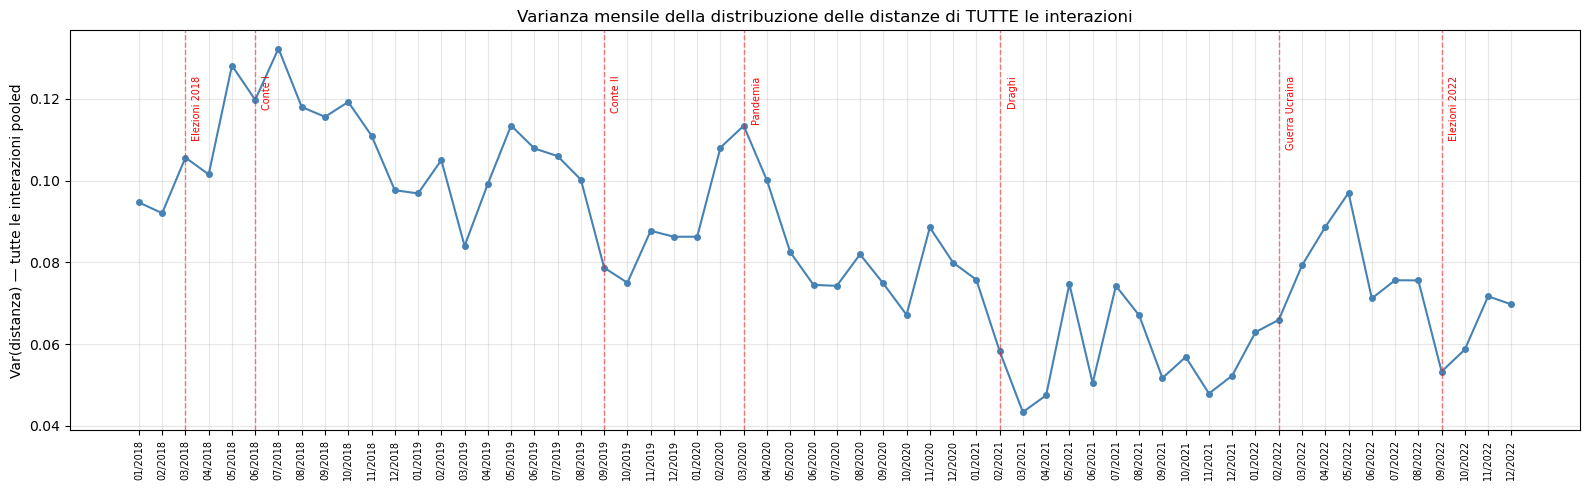

month_year
01/2018    0.094648
02/2018    0.092011
03/2018    0.105617
04/2018    0.101487
05/2018    0.128108
06/2018    0.119709
07/2018    0.132268
08/2018    0.117971
09/2018    0.115570
10/2018    0.119200
11/2018    0.110981
12/2018    0.097632
01/2019    0.096837
02/2019    0.104983
03/2019    0.084010
04/2019    0.099163
05/2019    0.113439
06/2019    0.107837
07/2019    0.105962
08/2019    0.100210
09/2019    0.078684
10/2019    0.075006
11/2019    0.087712
12/2019    0.086245
01/2020    0.086262
02/2020    0.108047
03/2020    0.113389
04/2020    0.100007
05/2020    0.082489
06/2020    0.074490
07/2020    0.074245
08/2020    0.081959
09/2020    0.074833
10/2020    0.067165
11/2020    0.088532
12/2020    0.079938
01/2021    0.075741
02/2021    0.058311
03/2021    0.043388
04/2021    0.047498
05/2021    0.074704
06/2021    0.050477
07/2021    0.074258
08/2021    0.067021
09/2021    0.051714
10/2021    0.056868
11/2021    0.047922
12/2021    0.052322
01/2022    0.062929
02/2022  

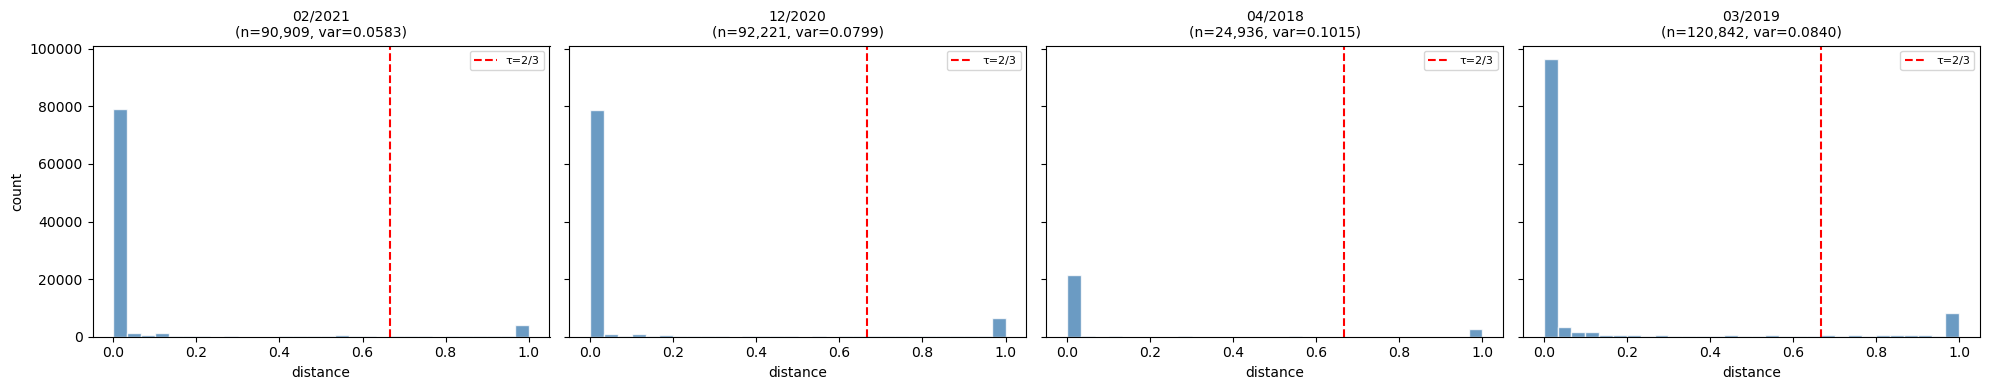

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- Varianza mensile della distribuzione di TUTTE le interazioni (pooled, non per utente) ---
monthly_var = quotes_with_dist.groupby('month_year')['distance'].var()
monthly_var = monthly_var.reindex(all_months)

fig, ax = plt.subplots(figsize=(16, 5))
x = range(len(all_months))
ax.plot(x, monthly_var.values, 'o-', color='steelblue', markersize=4)

ymax = monthly_var.max()
for event_date, label in events.items():
    parts = event_date.split('-')
    month_key = event_date
    if month_key in all_months:
        xi = all_months.index(month_key)
        ax.axvline(xi, color='red', alpha=0.5, linestyle='--', linewidth=1)
        ax.text(xi + 0.3, ymax * 0.95, label, rotation=90, va='top', fontsize=7, color='red')

ax.set_xticks(x)
ax.set_xticklabels(all_months, rotation=90, fontsize=7)
ax.set_ylabel('Var(distanza) — tutte le interazioni pooled')
ax.set_title('Varianza mensile della distribuzione delle distanze di TUTTE le interazioni')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(monthly_var)

# --- 4 istogrammi a caso (mesi diversi) ---
random_months = np.random.choice(quotes_with_dist['month_year'].unique(), size=4, replace=False)

fig, axes = plt.subplots(1, 4, figsize=(20, 4), sharey=True)
for ax, month in zip(axes, random_months):
    dists = quotes_with_dist[quotes_with_dist['month_year'] == month]['distance']
    ax.hist(dists, bins=30, range=(0, 1), color='steelblue', edgecolor='white', alpha=0.8)
    ax.axvline(2/3, color='red', linestyle='--', linewidth=1.5, label='τ=2/3')
    ax.set_title(f'{month}\n(n={len(dists):,}, var={dists.var():.4f})', fontsize=10)
    ax.set_xlabel('distance')
    ax.legend(fontsize=8)

axes[0].set_ylabel('count')
plt.tight_layout()
plt.show()

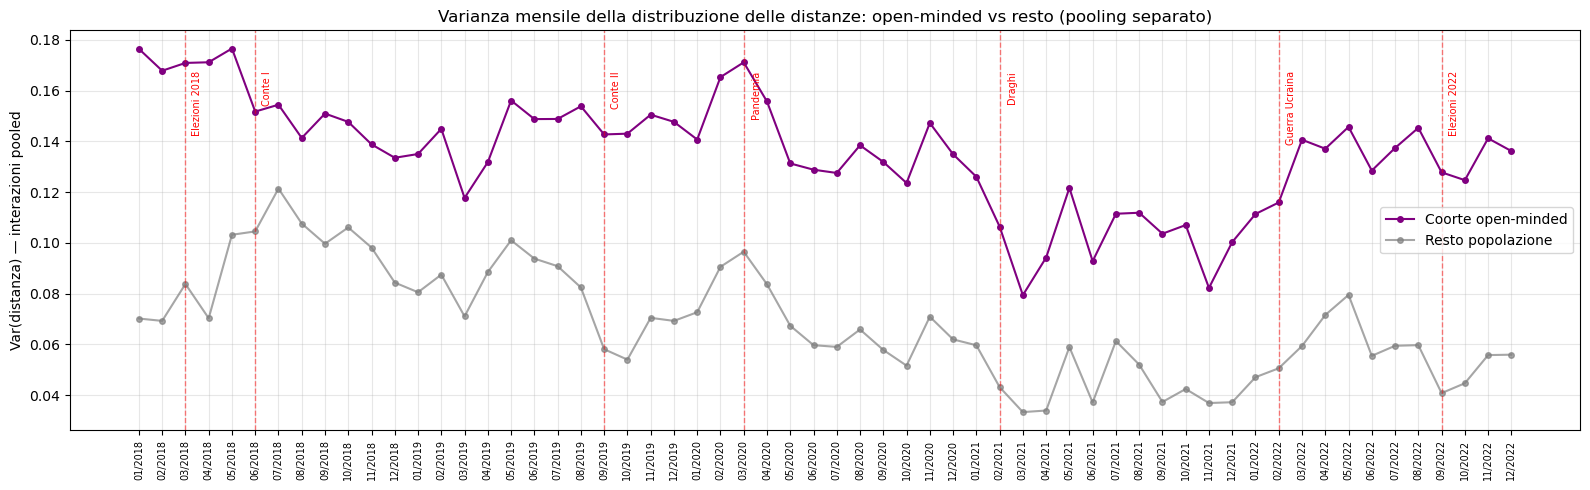

              var_om   n_om  var_rest  n_rest
month_year                                   
01/2018     0.176431  10246  0.070144   46428
02/2018     0.167817  14616  0.069217   60991
03/2018     0.170892   9238  0.083773   34925
04/2018     0.171155   6477  0.070260   18459
05/2018     0.176577  14167  0.103158   35462
06/2018     0.151720  38553  0.104486  101737
07/2018     0.154424  34793  0.121363   88324
08/2018     0.141313  38259  0.107584   99593
09/2018     0.150937  40731  0.099620  109507
10/2018     0.147657  37638  0.106048  106779
11/2018     0.138800  31325  0.098121   88609
12/2018     0.133509  58058  0.084321  192440
01/2019     0.134993  40230  0.080502  110009
02/2019     0.144910  32051  0.087451   93242
03/2019     0.117688  29192  0.070991   91650
04/2019     0.131790  23727  0.088457   86015
05/2019     0.156079  27765  0.100983  113792
06/2019     0.148755  28074  0.093769   98149
07/2019     0.148807  48468  0.090781  161377
08/2019     0.153806  47525  0.082

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

is_om = quotes_with_dist['reference_author'].isin(om_cohort)
quotes_om = quotes_with_dist[is_om]
quotes_rest = quotes_with_dist[~is_om]

monthly_var_om = quotes_om.groupby('month_year')['distance'].var().reindex(all_months)
monthly_var_rest = quotes_rest.groupby('month_year')['distance'].var().reindex(all_months)
n_om = quotes_om.groupby('month_year').size().reindex(all_months)
n_rest = quotes_rest.groupby('month_year').size().reindex(all_months)

fig, ax = plt.subplots(figsize=(16, 5))
x = range(len(all_months))
ax.plot(x, monthly_var_om.values, 'o-', color='purple', markersize=4, label='Coorte open-minded')
ax.plot(x, monthly_var_rest.values, 'o-', color='gray', markersize=4, label='Resto popolazione', alpha=0.7)

ymax = max(monthly_var_om.max(), monthly_var_rest.max())
for event_date, label in events.items():
    parts = event_date.split('-')
    month_key = event_date
    if month_key in all_months:
        xi = all_months.index(month_key)
        ax.axvline(xi, color='red', alpha=0.5, linestyle='--', linewidth=1)
        ax.text(xi + 0.3, ymax * 0.95, label, rotation=90, va='top', fontsize=7, color='red')

ax.set_xticks(x)
ax.set_xticklabels(all_months, rotation=90, fontsize=7)
ax.set_ylabel('Var(distanza) — interazioni pooled')
ax.set_title('Varianza mensile della distribuzione delle distanze: open-minded vs resto (pooling separato)')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(pd.DataFrame({'var_om': monthly_var_om, 'n_om': n_om,
                     'var_rest': monthly_var_rest, 'n_rest': n_rest}))

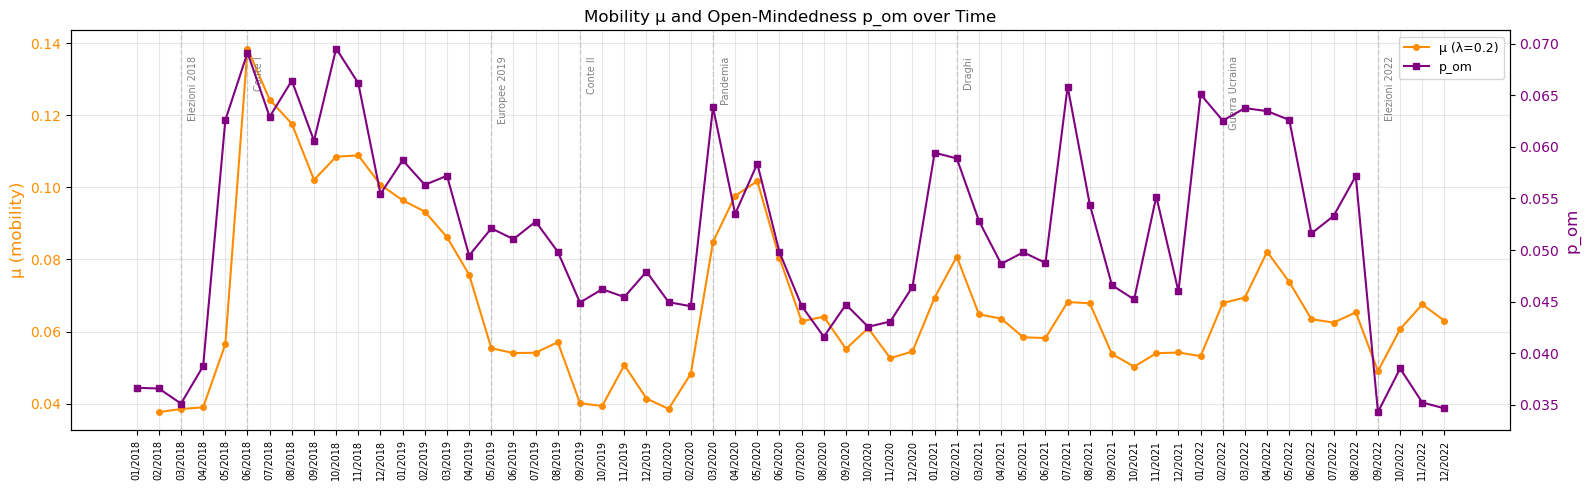

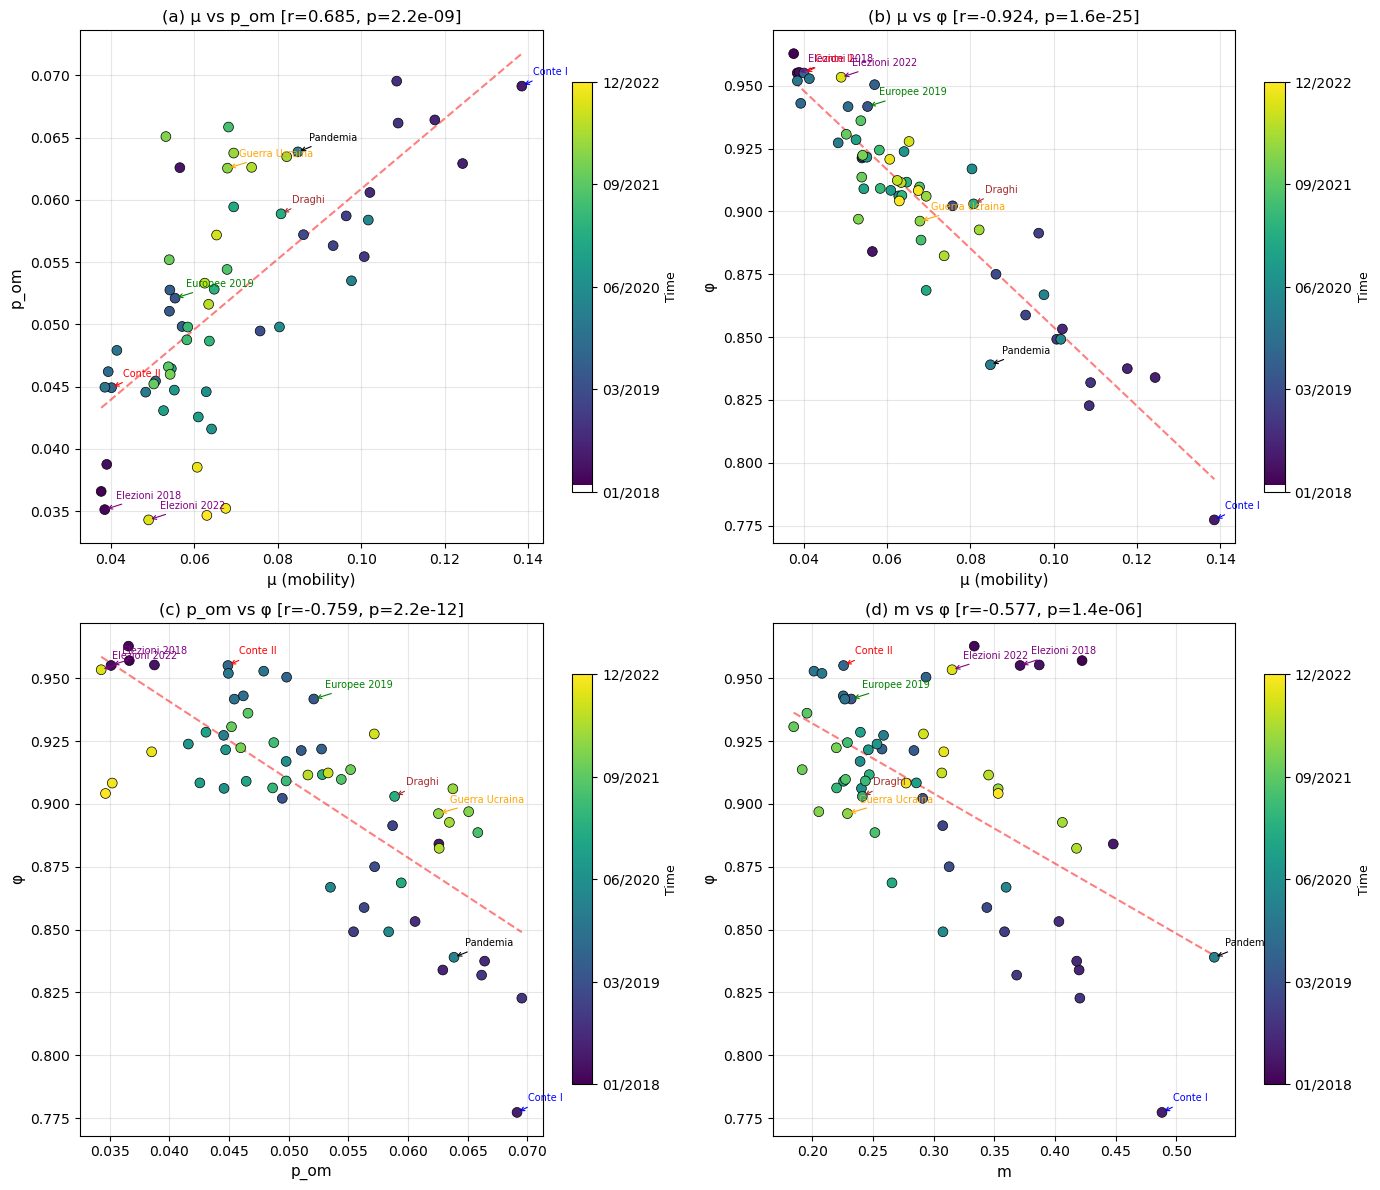


CORRELATION SUMMARY
  μ vs p_om           : r=0.685, p=2.25e-09
  μ vs φ              : r=-0.924, p=1.64e-25
  μ vs m              : r=0.605, p=3.95e-07
  p_om vs φ           : r=-0.759, p=2.15e-12
  m vs φ              : r=-0.577, p=1.36e-06
  p_om vs m           : r=0.356, p=5.20e-03


In [ ]:
# =============================================================================
# Mobility vs Open-Mindedness (+ colorbar temporale su tutti gli scatter)
# =============================================================================
# Presuppone che siano già calcolati:
#   - mobility_series[0.2]  (da mobility_analysis.py)
#   - pop_om_series          (da sezione 5-6 del notebook)
#   - phi_monthly            (da sezione 4)
#   - all_months, events, event_colors
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import matplotlib.cm as cm
from scipy.stats import pearsonr

lam_default = 0.2
mob_monthly = mobility_series[lam_default]

# --- Build aligned arrays ---
mob_vals = [mob_monthly.get(m, np.nan) for m in all_months]
pom_vals = [pop_om_series.get(m, np.nan) for m in all_months]
phi_vals = [phi_monthly.get(m, np.nan) for m in all_months]
m_vals   = [m_monthly_new.get(m, np.nan) for m in all_months]
t_norm   = np.linspace(0, 1, len(all_months))  # for colormap

# =====================================================================
# FIGURE 1: Time series — μ and p_om on same plot (dual y-axis)
# =====================================================================
fig, ax1 = plt.subplots(figsize=(16, 5))
x = range(len(all_months))

color_mob = 'darkorange'
color_pom = 'purple'

ax1.plot(x, mob_vals, 'o-', color=color_mob, markersize=4, label=f'μ (λ={lam_default})')
ax1.set_ylabel('μ (mobility)', color=color_mob, fontsize=12)
ax1.tick_params(axis='y', labelcolor=color_mob)

ax2 = ax1.twinx()
ax2.plot(x, pom_vals, 's-', color=color_pom, markersize=4, label='p_om')
ax2.set_ylabel('p_om', color=color_pom, fontsize=12)
ax2.tick_params(axis='y', labelcolor=color_pom)

ax1.set_xticks(x)
ax1.set_xticklabels(all_months, rotation=90, fontsize=7)
ax1.set_title('Mobility μ and Open-Mindedness p_om over Time')
ax1.grid(alpha=0.3)

# Events
month_to_x = {m: i for i, m in enumerate(all_months)}
for event_date, label in events.items():
    parts = event_date.split('-')
    month_key = event_date
    if month_key in month_to_x:
        xi = month_to_x[month_key]
        ax1.axvline(xi, color='gray', alpha=0.3, linestyle='--', linewidth=1)
        ax1.text(xi + 0.3, ax1.get_ylim()[1] * 0.95, label, rotation=90,
                 va='top', fontsize=7, color='gray')

# Combined legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right', fontsize=9)

plt.tight_layout()
plt.savefig('Fig_mobility_pom_timeseries.png', dpi=300, bbox_inches='tight')
plt.show()

# =====================================================================
# FIGURE 2: Scatter plots con COLORBAR temporale
# =====================================================================
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

def scatter_with_colorbar(ax, xvals, yvals, xlabel, ylabel, title_prefix):
    """Scatter with temporal colorbar + correlation."""
    valid_idx = [i for i in range(len(xvals)) if not (np.isnan(xvals[i]) or np.isnan(yvals[i]))]
    if not valid_idx:
        ax.set_title(f'{title_prefix} — no data')
        return

    xv = [xvals[i] for i in valid_idx]
    yv = [yvals[i] for i in valid_idx]
    tv = [t_norm[i] for i in valid_idx]
    mv = [all_months[i] for i in valid_idx]

    sc = ax.scatter(xv, yv, c=tv, cmap='viridis', s=50, edgecolors='black', linewidths=0.5, zorder=3)
    cbar = plt.colorbar(sc, ax=ax, shrink=0.8)
    # Colorbar ticks: show a few month labels
    n_ticks = 5
    tick_positions = np.linspace(0, 1, n_ticks)
    tick_indices = [int(p * (len(all_months) - 1)) for p in tick_positions]
    cbar.set_ticks(tick_positions)
    cbar.set_ticklabels([all_months[i] for i in tick_indices])
    cbar.set_label('Time', fontsize=9)

    # Annotate events
    for event_date, label in events.items():
        parts = event_date.split('-')
        month_key = event_date
        if month_key in mv:
            idx = mv.index(month_key)
            ax.annotate(label, (xv[idx], yv[idx]),
                        textcoords="offset points", xytext=(8, 8), fontsize=7,
                        color=event_colors.get(label, 'red'),
                        arrowprops=dict(arrowstyle='->', color=event_colors.get(label, 'red'), lw=0.8))

    # Regression line
    z = np.polyfit(xv, yv, 1)
    xl = np.linspace(min(xv), max(xv), 100)
    ax.plot(xl, np.poly1d(z)(xl), 'r--', alpha=0.5)

    r, p = pearsonr(xv, yv)
    ax.set_xlabel(xlabel, fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_title(f'{title_prefix} [r={r:.3f}, p={p:.1e}]', fontsize=12)
    ax.grid(alpha=0.3)

# (a) μ vs p_om
scatter_with_colorbar(axes[0, 0], mob_vals, pom_vals, 'μ (mobility)', 'p_om', '(a) μ vs p_om')

# (b) μ vs φ
scatter_with_colorbar(axes[0, 1], mob_vals, phi_vals, 'μ (mobility)', 'φ', '(b) μ vs φ')

# (c) p_om vs φ (con colorbar ora)
scatter_with_colorbar(axes[1, 0], pom_vals, phi_vals, 'p_om', 'φ', '(c) p_om vs φ')

# (d) m vs φ (con colorbar ora)
scatter_with_colorbar(axes[1, 1], m_vals, phi_vals, 'm', 'φ', '(d) m vs φ')

plt.tight_layout()
plt.savefig('Fig_scatter_all_with_colorbar.png', dpi=300, bbox_inches='tight')
plt.show()

# =====================================================================
# CORRELATIONS
# =====================================================================
print("\n" + "="*60)
print("CORRELATION SUMMARY")
print("="*60)

pairs = [
    ('μ vs p_om', mob_vals, pom_vals),
    ('μ vs φ', mob_vals, phi_vals),
    ('μ vs m', mob_vals, m_vals),
    ('p_om vs φ', pom_vals, phi_vals),
    ('m vs φ', m_vals, phi_vals),
    ('p_om vs m', pom_vals, m_vals),
]

for name, a_list, b_list in pairs:
    valid = [(a, b) for a, b in zip(a_list, b_list) if not (np.isnan(a) or np.isnan(b))]
    if valid:
        a, b = zip(*valid)
        r, p = pearsonr(a, b)
        print(f"  {name:20s}: r={r:.3f}, p={p:.2e}")

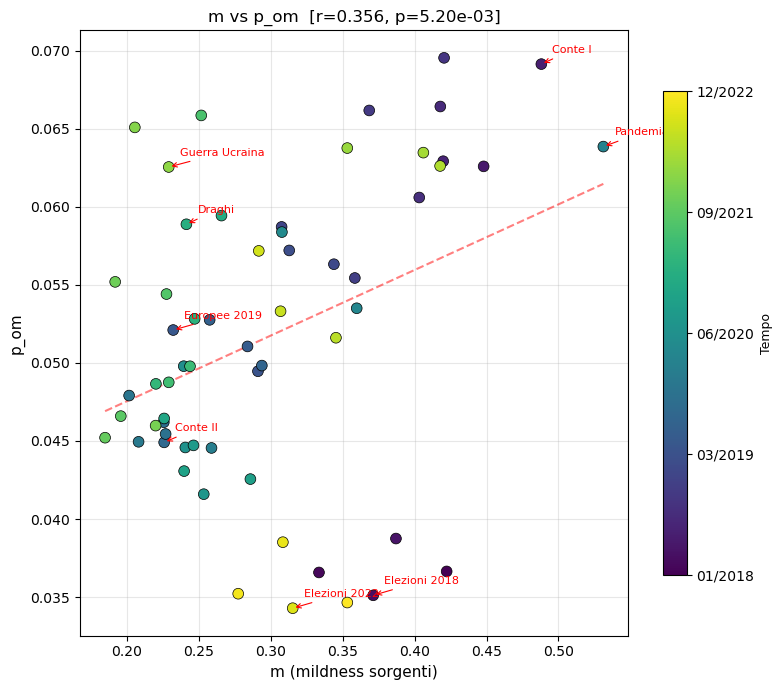

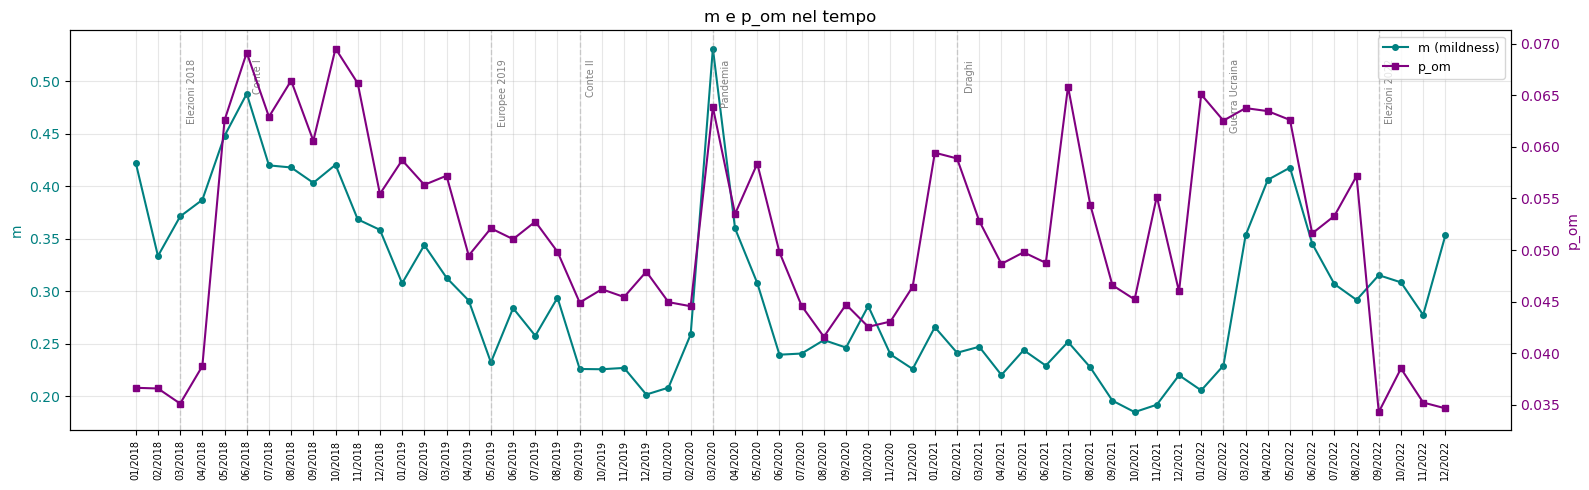

Pearson r (m vs p_om): 0.356, p=5.20e-03


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

m_vals = [m_monthly_new.get(mo, np.nan) for mo in all_months]
pom_vals = [pop_om_series.get(mo, np.nan) for mo in all_months]
t_norm = np.linspace(0, 1, len(all_months))

valid_idx = [i for i in range(len(all_months)) if not (np.isnan(m_vals[i]) or np.isnan(pom_vals[i]))]
xv = [m_vals[i] for i in valid_idx]
yv = [pom_vals[i] for i in valid_idx]
tv = [t_norm[i] for i in valid_idx]
mv = [all_months[i] for i in valid_idx]

# --- Scatter con colorbar temporale ---
fig, ax = plt.subplots(figsize=(8, 7))
sc = ax.scatter(xv, yv, c=tv, cmap='viridis', s=60, edgecolors='black', linewidths=0.5, zorder=3)
cbar = plt.colorbar(sc, ax=ax, shrink=0.8)
n_ticks = 5
tick_positions = np.linspace(0, 1, n_ticks)
tick_indices = [int(p * (len(all_months) - 1)) for p in tick_positions]
cbar.set_ticks(tick_positions)
cbar.set_ticklabels([all_months[i] for i in tick_indices])
cbar.set_label('Tempo', fontsize=9)

for event_date, label in events.items():
    parts = event_date.split('-')
    month_key = event_date
    if month_key in mv:
        idx = mv.index(month_key)
        ax.annotate(label, (xv[idx], yv[idx]), textcoords="offset points", xytext=(8, 8),
                    fontsize=8, color='red', arrowprops=dict(arrowstyle='->', color='red', lw=0.8))

z = np.polyfit(xv, yv, 1)
xl = np.linspace(min(xv), max(xv), 100)
ax.plot(xl, np.poly1d(z)(xl), 'r--', alpha=0.5)

r, p = pearsonr(xv, yv)
ax.set_xlabel('m (mildness sorgenti)', fontsize=11)
ax.set_ylabel('p_om', fontsize=11)
ax.set_title(f'm vs p_om  [r={r:.3f}, p={p:.2e}]', fontsize=12)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# --- Serie temporale affiancata (dual y-axis) ---
fig, ax1 = plt.subplots(figsize=(16, 5))
x = range(len(all_months))
ax1.plot(x, m_vals, 'o-', color='teal', markersize=4, label='m (mildness)')
ax1.set_ylabel('m', color='teal')
ax1.tick_params(axis='y', labelcolor='teal')

ax2 = ax1.twinx()
ax2.plot(x, pom_vals, 's-', color='purple', markersize=4, label='p_om')
ax2.set_ylabel('p_om', color='purple')
ax2.tick_params(axis='y', labelcolor='purple')

ax1.set_xticks(x)
ax1.set_xticklabels(all_months, rotation=90, fontsize=7)
ax1.set_title('m e p_om nel tempo')
ax1.grid(alpha=0.3)

month_to_x = {mo: i for i, mo in enumerate(all_months)}
for event_date, label in events.items():
    parts = event_date.split('-')
    month_key = event_date
    if month_key in month_to_x:
        xi = month_to_x[month_key]
        ax1.axvline(xi, color='gray', alpha=0.3, linestyle='--', linewidth=1)
        ax1.text(xi + 0.3, ax1.get_ylim()[1] * 0.95, label, rotation=90, va='top', fontsize=7, color='gray')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right', fontsize=9)
plt.tight_layout()
plt.show()

print(f"Pearson r (m vs p_om): {r:.3f}, p={p:.2e}")

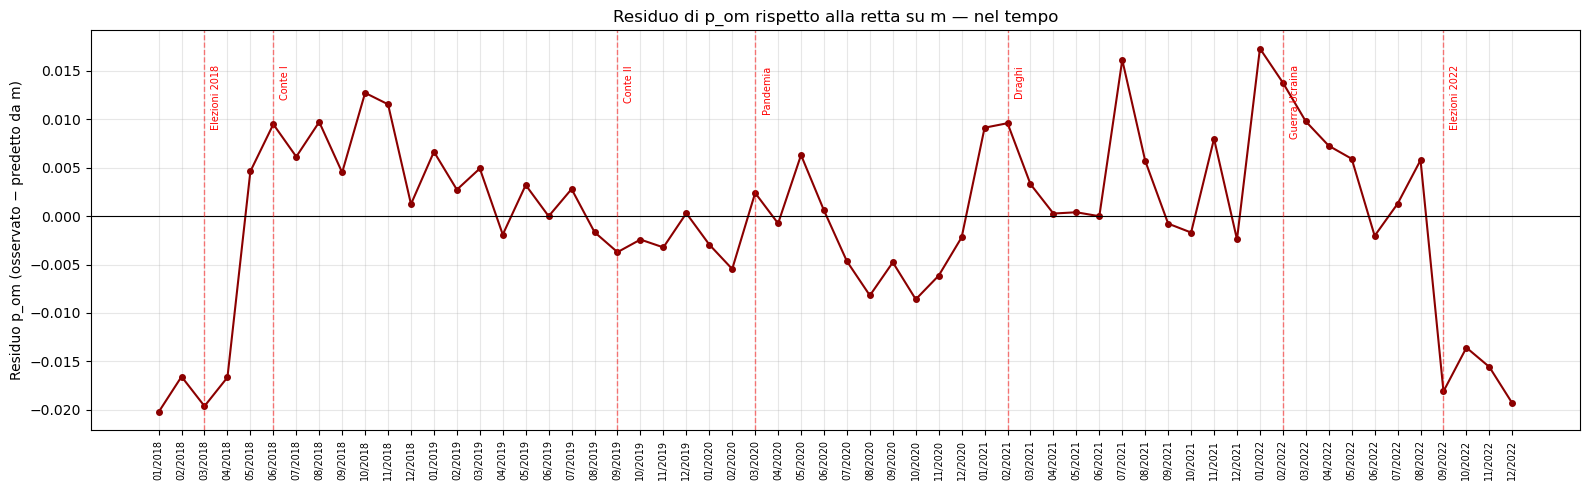

Tutti i mesi ordinati per residuo (dal più negativo al più positivo):
month_year  residual  percentile
   01/2018 -0.020240    1.666667
   03/2018 -0.019625    3.333333
   12/2022 -0.019331    5.000000
   09/2022 -0.018100    6.666667
   04/2018 -0.016654    8.333333
   02/2018 -0.016577   10.000000
   11/2022 -0.015580   11.666667
   10/2022 -0.013584   13.333333
   10/2020 -0.008596   15.000000
   08/2020 -0.008200   16.666667
   11/2020 -0.006148   18.333333
   02/2020 -0.005465   20.000000
   09/2020 -0.004775   21.666667
   07/2020 -0.004670   23.333333
   09/2019 -0.003725   25.000000
   11/2019 -0.003232   26.666667
   01/2020 -0.002941   28.333333
   10/2019 -0.002424   30.000000
   12/2021 -0.002403   31.666667
   12/2020 -0.002194   33.333333
   06/2022 -0.002042   35.000000
   04/2019 -0.001910   36.666667
   10/2021 -0.001699   38.333333
   08/2019 -0.001661   40.000000
   09/2021 -0.000778   41.666667
   04/2020 -0.000761   43.333333
   06/2019 -0.000016   45.000000
   06/

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

m_vals = [m_monthly_new.get(mo, np.nan) for mo in all_months]
pom_vals = [pop_om_series.get(mo, np.nan) for mo in all_months]

valid_idx = [i for i in range(len(all_months)) if not (np.isnan(m_vals[i]) or np.isnan(pom_vals[i]))]
xv = np.array([m_vals[i] for i in valid_idx])
yv = np.array([pom_vals[i] for i in valid_idx])
mv = [all_months[i] for i in valid_idx]

# --- Regressione e residui ---
z = np.polyfit(xv, yv, 1)
pred = np.poly1d(z)(xv)
resid = yv - pred

resid_series = pd.Series(resid, index=mv).reindex(all_months)

# --- Plot residuo nel tempo ---
fig, ax = plt.subplots(figsize=(16, 5))
x = range(len(all_months))
ax.plot(x, resid_series.values, 'o-', color='darkred', markersize=4)
ax.axhline(0, color='black', linewidth=0.8)

ymax = resid_series.max()
ymin = resid_series.min()
month_to_x = {mo: i for i, mo in enumerate(all_months)}
for event_date, label in events.items():
    parts = event_date.split('-')
    month_key = event_date
    if month_key in month_to_x:
        xi = month_to_x[month_key]
        ax.axvline(xi, color='red', alpha=0.5, linestyle='--', linewidth=1)
        ax.text(xi + 0.3, ymax * 0.9, label, rotation=90, va='top', fontsize=7, color='red')

ax.set_xticks(x)
ax.set_xticklabels(all_months, rotation=90, fontsize=7)
ax.set_ylabel('Residuo p_om (osservato − predetto da m)')
ax.set_title('Residuo di p_om rispetto alla retta su m — nel tempo')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# --- Rank dei mesi-evento rispetto a tutti i mesi validi ---
resid_valid = resid_series.dropna().sort_values()
resid_valid_ranked = resid_valid.reset_index()
resid_valid_ranked.columns = ['month_year', 'residual']
resid_valid_ranked['percentile'] = (resid_valid_ranked.index + 1) / len(resid_valid_ranked) * 100

print("Tutti i mesi ordinati per residuo (dal più negativo al più positivo):")
print(resid_valid_ranked.to_string(index=False))

print("\nDove cadono i mesi-evento nel ranking:")
for event_date, label in events.items():
    parts = event_date.split('-')
    month_key = event_date
    row = resid_valid_ranked[resid_valid_ranked['month_year'] == month_key]
    if not row.empty:
        r = row.iloc[0]
        print(f"  {label:20s} ({month_key}): residuo={r['residual']:+.4f}, percentile={r['percentile']:.1f}%")

# hysteresis analysis

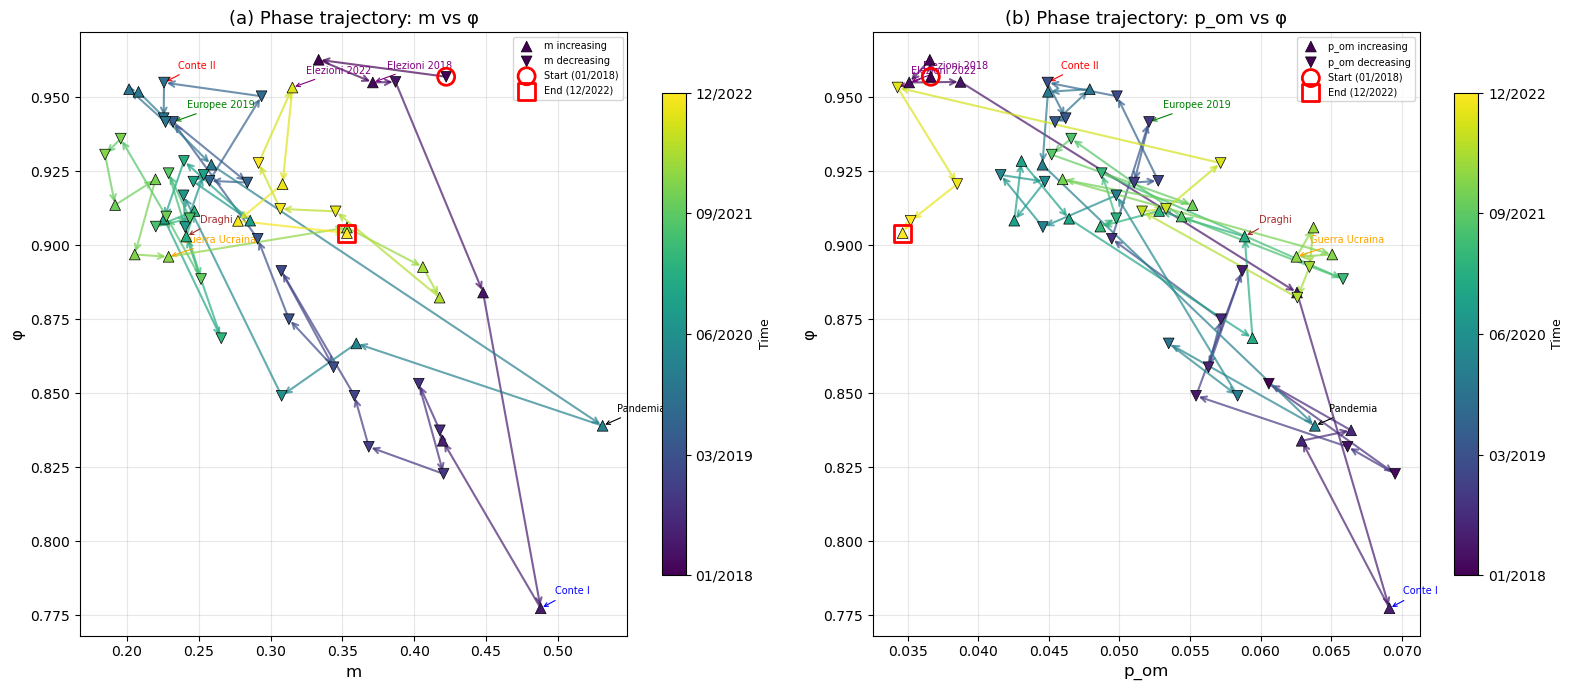

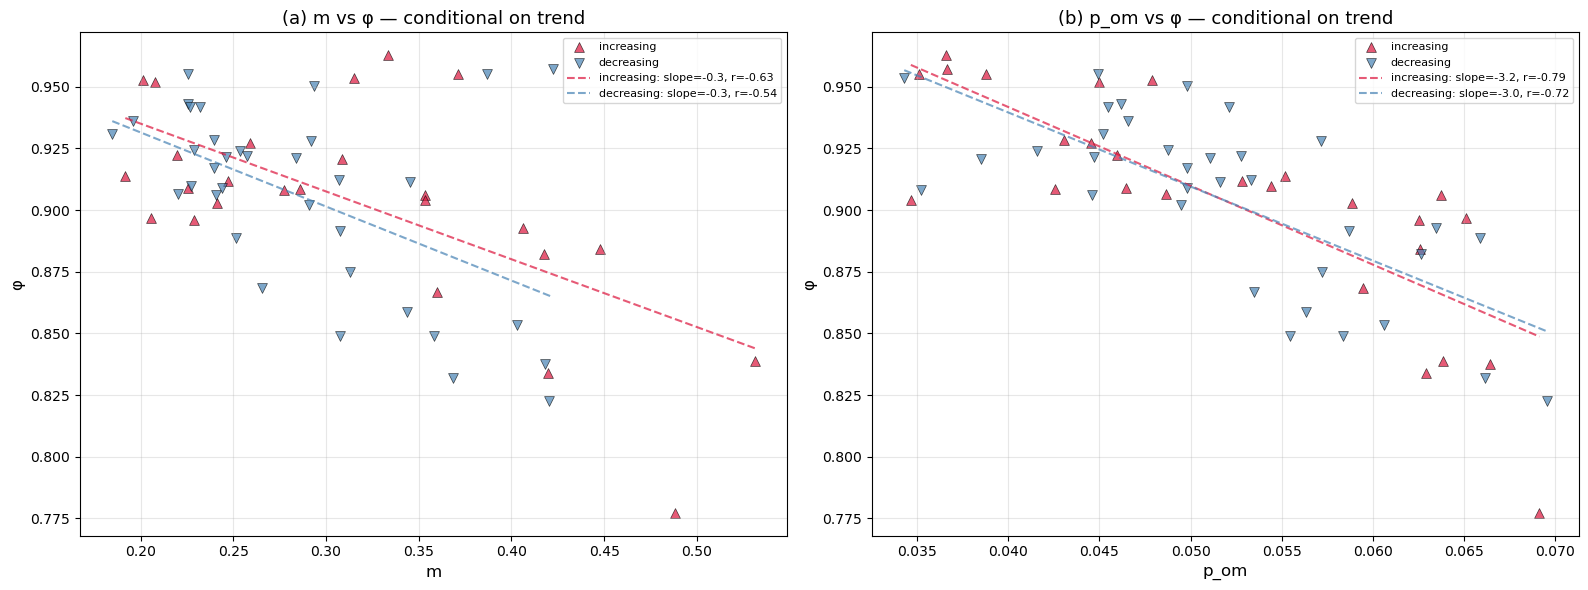

LOOP AREA (shoelace formula)
  (m, φ) trajectory:    area = -0.015194  (sign: CW)
  (p_om, φ) trajectory: area = -0.000234  (sign: CW)

  Normalized (area/bbox):
    (m, φ):    0.2365
    (p_om, φ): 0.0358


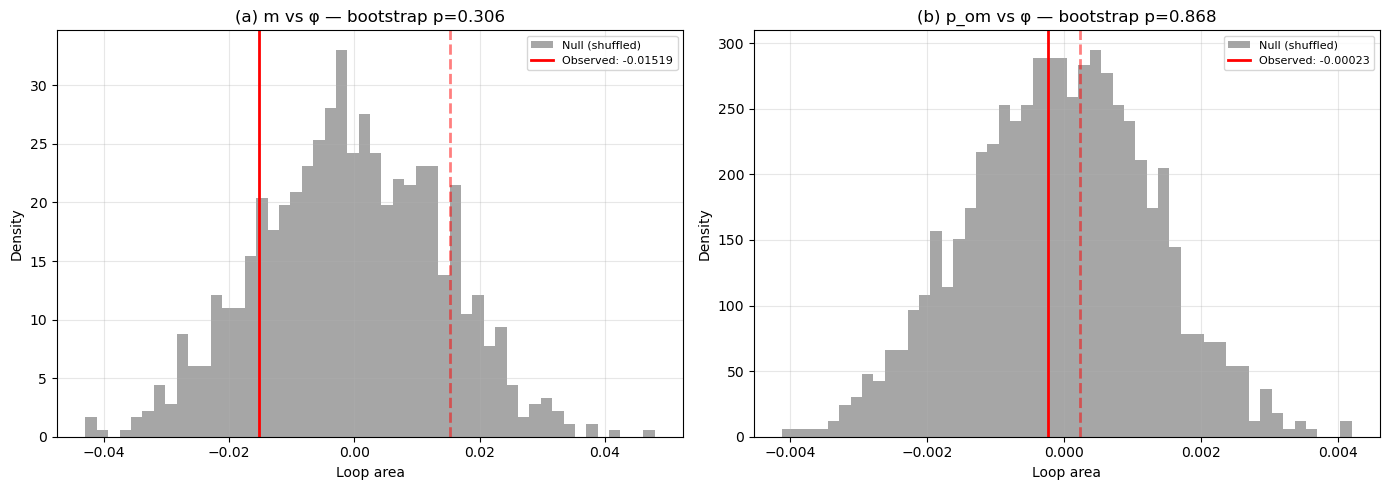


HYSTERESIS ANALYSIS SUMMARY

THEORY PREDICTION (Fokker-Planck, Section 9.2):
  - m:   changes landscape shape → bistability → hysteresis EXPECTED
  - p_om: changes noise level only → monotone transition → NO hysteresis

EMPIRICAL RESULTS:

  (m, φ) trajectory:
    Loop area (normalized): 0.2365
    Bootstrap p-value:      0.306
    Conditional regressions: {'increasing': {'slope': np.float64(-0.2748118395361085), 'intercept': np.float64(0.9899815960891923), 'r': np.float64(-0.6331867672782383), 'p': np.float64(0.0006803982363582285)}, 'decreasing': {'slope': np.float64(-0.30017404199063746), 'intercept': np.float64(0.9914864734052821), 'r': np.float64(-0.5350826362119244), 'p': np.float64(0.0009266633117556124)}}

  (p_om, φ) trajectory:
    Loop area (normalized): 0.0358
    Bootstrap p-value:      0.868
    Conditional regressions: {'increasing': {'slope': np.float64(-3.192972040031352), 'intercept': np.float64(1.0694419596837885), 'r': np.float64(-0.789810922697997), 'p': np.float6

In [ ]:
# =============================================================================
# Hysteresis Analysis in Empirical Phase Diagrams
# =============================================================================
#
# From the Fokker-Planck derivation (Section 9.2, p.16):
#   - m changes the landscape shape → bistability → hysteresis expected
#   - p_om changes only noise level → monotone transition, no hysteresis
#
# We test this prediction on the empirical (m, φ) and (p_om, φ) diagrams.
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch
from scipy.stats import pearsonr, linregress
from shapely.geometry import Polygon  # for loop area

# --- 0. Build aligned monthly arrays ---
mob_vals  = [mobility_series[0.2].get(m, np.nan) for m in all_months]
pom_vals  = [pop_om_series.get(m, np.nan) for m in all_months]
phi_vals  = [phi_monthly.get(m, np.nan) for m in all_months]
m_vals    = [m_monthly_new.get(m, np.nan) for m in all_months]
t_norm    = np.linspace(0, 1, len(all_months))

# --- Helper: identify increasing/decreasing segments ---
def classify_trend(vals, window=3):
    """For each point, classify if the variable is locally increasing or decreasing.
    Uses a centered moving average of the finite difference."""
    trends = np.full(len(vals), np.nan)
    for i in range(len(vals)):
        diffs = []
        for j in range(max(0, i - window), min(len(vals) - 1, i + window)):
            if not (np.isnan(vals[j]) or np.isnan(vals[j+1])):
                diffs.append(vals[j+1] - vals[j])
        if diffs:
            trends[i] = np.mean(diffs)
    return trends

m_trend   = classify_trend(m_vals)
pom_trend = classify_trend(pom_vals)

# =====================================================================
# FIGURE 1: Phase trajectories with arrows
# =====================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

def plot_trajectory(ax, xvals, yvals, xlabel, ylabel, title, trend_vals):
    """Plot phase trajectory with arrows colored by time and trend markers."""
    # Filter valid points
    valid_idx = [i for i in range(len(xvals)) if not (np.isnan(xvals[i]) or np.isnan(yvals[i]))]
    if len(valid_idx) < 2:
        return

    xv = np.array([xvals[i] for i in valid_idx])
    yv = np.array([yvals[i] for i in valid_idx])
    tv = np.array([t_norm[i] for i in valid_idx])
    mv = [all_months[i] for i in valid_idx]
    tr = np.array([trend_vals[i] if not np.isnan(trend_vals[i]) else 0 for i in valid_idx])

    # Color by time
    cmap = plt.cm.viridis
    colors = cmap(tv)

    # Draw arrows between consecutive points
    for i in range(len(xv) - 1):
        ax.annotate('', xy=(xv[i+1], yv[i+1]), xytext=(xv[i], yv[i]),
                     arrowprops=dict(arrowstyle='->', color=colors[i], lw=1.5, alpha=0.7))

    # Scatter: increasing = triangle up, decreasing = triangle down
    mask_up   = tr > 0
    mask_down = tr <= 0

    sc_up = ax.scatter(xv[mask_up], yv[mask_up], c=tv[mask_up], cmap='viridis',
                       s=60, marker='^', edgecolors='black', linewidths=0.5, zorder=5,
                       label=f'{xlabel} increasing')
    sc_dn = ax.scatter(xv[mask_down], yv[mask_down], c=tv[mask_down], cmap='viridis',
                       s=60, marker='v', edgecolors='black', linewidths=0.5, zorder=5,
                       label=f'{xlabel} decreasing')

    # Colorbar
    sm = plt.cm.ScalarMappable(cmap='viridis', norm=plt.Normalize(0, 1))
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax, shrink=0.8)
    n_ticks = 5
    tick_positions = np.linspace(0, 1, n_ticks)
    tick_indices = [int(p * (len(all_months) - 1)) for p in tick_positions]
    cbar.set_ticks(tick_positions)
    cbar.set_ticklabels([all_months[i] for i in tick_indices])
    cbar.set_label('Time', fontsize=9)

    # Annotate key events
    for event_date, label in events.items():
        parts = event_date.split('-')
        month_key = event_date
        if month_key in mv:
            idx = mv.index(month_key)
            ax.annotate(label, (xv[idx], yv[idx]),
                        textcoords="offset points", xytext=(10, 10), fontsize=7,
                        color=event_colors.get(label, 'red'),
                        arrowprops=dict(arrowstyle='->', color=event_colors.get(label, 'red'), lw=0.8))

    # Mark start and end
    ax.scatter([xv[0]], [yv[0]], s=150, marker='o', facecolors='none',
               edgecolors='red', linewidths=2, zorder=10, label='Start (01/2018)')
    ax.scatter([xv[-1]], [yv[-1]], s=150, marker='s', facecolors='none',
               edgecolors='red', linewidths=2, zorder=10, label='End (12/2022)')

    ax.set_xlabel(xlabel, fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.set_title(title, fontsize=13)
    ax.legend(fontsize=7, loc='best')
    ax.grid(alpha=0.3)

plot_trajectory(axes[0], m_vals, phi_vals, 'm', 'φ',
                '(a) Phase trajectory: m vs φ', m_trend)
plot_trajectory(axes[1], pom_vals, phi_vals, 'p_om', 'φ',
                '(b) Phase trajectory: p_om vs φ', pom_trend)

plt.tight_layout()
plt.savefig('Fig_hysteresis_trajectories.png', dpi=300, bbox_inches='tight')
plt.show()

# =====================================================================
# FIGURE 2: Conditional scatter — increasing vs decreasing ramps
# =====================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

def conditional_scatter(ax, xvals, yvals, trend_vals, xlabel, ylabel, title):
    """Separate scatter + regression for increasing vs decreasing phases."""
    valid_idx = [i for i in range(len(xvals))
                 if not (np.isnan(xvals[i]) or np.isnan(yvals[i]) or np.isnan(trend_vals[i]))]

    xv = np.array([xvals[i] for i in valid_idx])
    yv = np.array([yvals[i] for i in valid_idx])
    tr = np.array([trend_vals[i] for i in valid_idx])

    mask_up   = tr > 0
    mask_down = tr <= 0

    # Scatter
    ax.scatter(xv[mask_up], yv[mask_up], color='crimson', s=50, alpha=0.7,
               edgecolors='black', linewidths=0.5, label='increasing', marker='^')
    ax.scatter(xv[mask_down], yv[mask_down], color='steelblue', s=50, alpha=0.7,
               edgecolors='black', linewidths=0.5, label='decreasing', marker='v')

    # Separate regressions
    results = {}
    for mask, color, name in [(mask_up, 'crimson', 'increasing'), (mask_down, 'steelblue', 'decreasing')]:
        if mask.sum() >= 3:
            slope, intercept, r, p, se = linregress(xv[mask], yv[mask])
            xl = np.linspace(xv[mask].min(), xv[mask].max(), 100)
            ax.plot(xl, slope * xl + intercept, '--', color=color, alpha=0.7,
                    label=f'{name}: slope={slope:.1f}, r={r:.2f}')
            results[name] = {'slope': slope, 'intercept': intercept, 'r': r, 'p': p}

    ax.set_xlabel(xlabel, fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.set_title(title, fontsize=13)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
    return results

res_m = conditional_scatter(axes[0], m_vals, phi_vals, m_trend,
                            'm', 'φ', '(a) m vs φ — conditional on trend')
res_pom = conditional_scatter(axes[1], pom_vals, phi_vals, pom_trend,
                              'p_om', 'φ', '(b) p_om vs φ — conditional on trend')

plt.tight_layout()
plt.savefig('Fig_hysteresis_conditional.png', dpi=300, bbox_inches='tight')
plt.show()

# =====================================================================
# FIGURE 3: Loop area computation
# =====================================================================
def compute_loop_area(xvals, yvals):
    """Compute signed area enclosed by the trajectory using the shoelace formula.
    Positive area = counterclockwise loop, negative = clockwise."""
    valid_idx = [i for i in range(len(xvals)) if not (np.isnan(xvals[i]) or np.isnan(yvals[i]))]
    if len(valid_idx) < 3:
        return 0.0, None

    xv = [xvals[i] for i in valid_idx]
    yv = [yvals[i] for i in valid_idx]

    # Close the loop
    xv_closed = xv + [xv[0]]
    yv_closed = yv + [yv[0]]

    # Shoelace formula (signed area)
    area = 0.0
    for i in range(len(xv)):
        area += xv_closed[i] * yv_closed[i+1] - xv_closed[i+1] * yv_closed[i]
    area /= 2.0

    return area, list(zip(xv_closed, yv_closed))

area_m, coords_m = compute_loop_area(m_vals, phi_vals)
area_pom, coords_pom = compute_loop_area(pom_vals, phi_vals)

print("="*60)
print("LOOP AREA (shoelace formula)")
print("="*60)
print(f"  (m, φ) trajectory:    area = {area_m:.6f}  (sign: {'CCW' if area_m > 0 else 'CW'})")
print(f"  (p_om, φ) trajectory: area = {area_pom:.6f}  (sign: {'CCW' if area_pom > 0 else 'CW'})")

# --- Normalize areas by bounding box for comparison ---
def bbox_area(xvals, yvals):
    valid = [(x, y) for x, y in zip(xvals, yvals) if not (np.isnan(x) or np.isnan(y))]
    xs, ys = zip(*valid)
    return (max(xs) - min(xs)) * (max(ys) - min(ys))

bbox_m = bbox_area(m_vals, phi_vals)
bbox_pom = bbox_area(pom_vals, phi_vals)

print(f"\n  Normalized (area/bbox):")
print(f"    (m, φ):    {abs(area_m)/bbox_m:.4f}")
print(f"    (p_om, φ): {abs(area_pom)/bbox_pom:.4f}")

# =====================================================================
# FIGURE 4: Bootstrap significance test for loop area
# =====================================================================
def bootstrap_loop_area(xvals, yvals, n_boot=1000, seed=42):
    """Shuffle temporal order and recompute loop area to get null distribution."""
    rng = np.random.RandomState(seed)
    valid_idx = [i for i in range(len(xvals)) if not (np.isnan(xvals[i]) or np.isnan(yvals[i]))]
    xv = np.array([xvals[i] for i in valid_idx])
    yv = np.array([yvals[i] for i in valid_idx])

    observed_area = compute_loop_area(xvals, yvals)[0]

    null_areas = []
    for _ in range(n_boot):
        perm = rng.permutation(len(xv))
        xp = xv[perm].tolist()
        yp = yv[perm].tolist()
        a, _ = compute_loop_area(xp, yp)
        null_areas.append(a)

    null_areas = np.array(null_areas)
    p_value = np.mean(np.abs(null_areas) >= np.abs(observed_area))
    return observed_area, null_areas, p_value

obs_m, null_m, p_m = bootstrap_loop_area(m_vals, phi_vals)
obs_pom, null_pom, p_pom = bootstrap_loop_area(pom_vals, phi_vals)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, obs, null, p, title in [
    (axes[0], obs_m, null_m, p_m, '(a) m vs φ'),
    (axes[1], obs_pom, null_pom, p_pom, '(b) p_om vs φ')
]:
    ax.hist(null, bins=50, density=True, color='gray', alpha=0.7, label='Null (shuffled)')
    ax.axvline(obs, color='red', linewidth=2, label=f'Observed: {obs:.5f}')
    ax.axvline(-obs, color='red', linewidth=2, linestyle='--', alpha=0.5)
    ax.set_xlabel('Loop area')
    ax.set_ylabel('Density')
    ax.set_title(f'{title} — bootstrap p={p:.3f}')
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('Fig_hysteresis_bootstrap.png', dpi=300, bbox_inches='tight')
plt.show()

# =====================================================================
# SUMMARY
# =====================================================================
print("\n" + "="*60)
print("HYSTERESIS ANALYSIS SUMMARY")
print("="*60)
print(f"""
THEORY PREDICTION (Fokker-Planck, Section 9.2):
  - m:   changes landscape shape → bistability → hysteresis EXPECTED
  - p_om: changes noise level only → monotone transition → NO hysteresis

EMPIRICAL RESULTS:

  (m, φ) trajectory:
    Loop area (normalized): {abs(area_m)/bbox_m:.4f}
    Bootstrap p-value:      {p_m:.3f}
    Conditional regressions: {res_m}

  (p_om, φ) trajectory:
    Loop area (normalized): {abs(area_pom)/bbox_pom:.4f}
    Bootstrap p-value:      {p_pom:.3f}
    Conditional regressions: {res_pom}

INTERPRETATION:
  If (m, φ) has significant loop area and different slopes for
  increasing vs decreasing ramps, this is consistent with hysteresis.
  If (p_om, φ) does NOT show these signatures, the theory is confirmed.
""")

# DOBBIAMO VEDERE SE PHI E M NON SONO MECCANICISTICAMENTE CORRELATE FACENDO UNO SPLITTING

Total normal users with opinion vectors: 87,291
Retweets normal→source: 18,448,004

Running 100 random splits...
  20/100 done
  40/100 done
  60/100 done
  80/100 done
  100/100 done

Split-sample correlations (n=100 valid splits):
  r: mean=-0.577, std=0.022, range=[-0.629, -0.530]
  p: median=1.63e-06, all significant (p<0.05)? True

Full-sample correlation: r=-0.577, p=1.36e-06


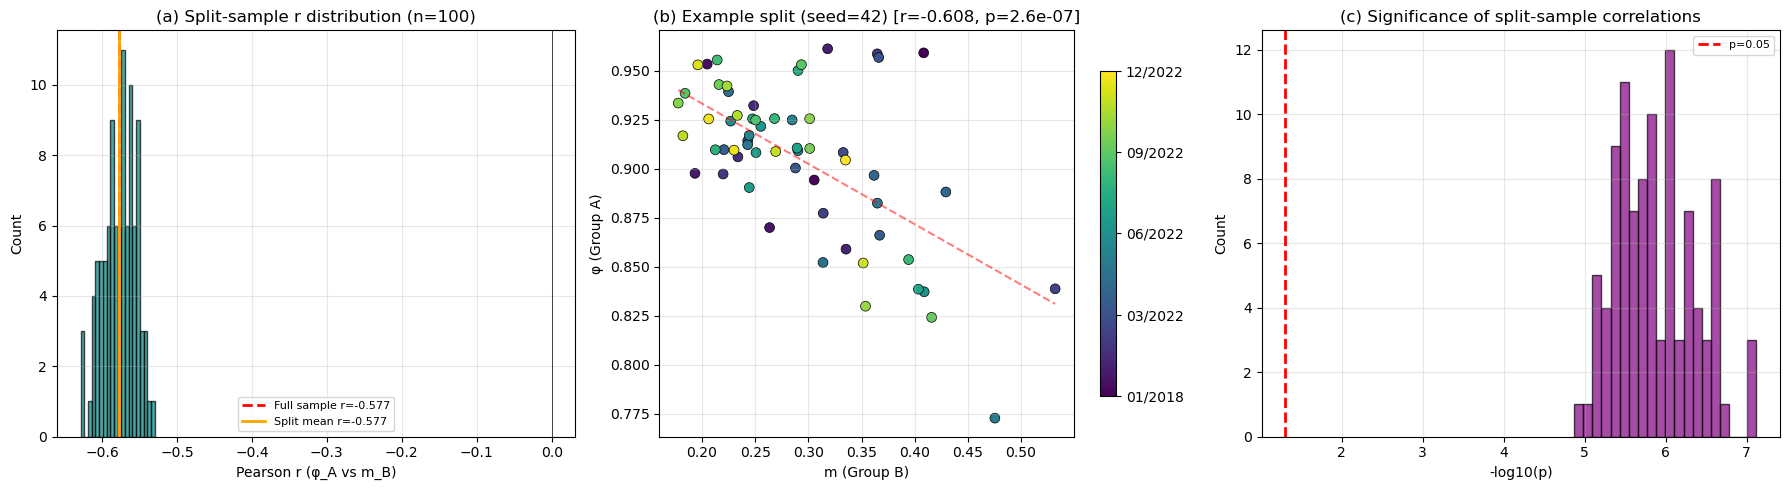


SPLIT-SAMPLE TEST SUMMARY

  Full-sample:     r = -0.577, p = 1.36e-06
  Split-sample:    r = -0.577 ± 0.022
  Splits significant (p<0.05): 100%

  CONCLUSION:
  If split-sample r ≈ full-sample r and most splits are significant,
  the m-φ correlation is NOT a mechanical artifact of shared data.
  It reflects genuine echo-chamber structure: audience segregation
  simultaneously drives φ high and m low.



In [ ]:
# =============================================================================
# Split-Sample Test: is the m-φ correlation an artifact of shared data?
# =============================================================================
#
# Problem: φ and m are both computed from the same opinion vectors (from retweets).
# If the correlation is purely mechanical, it would vanish when we compute
# φ from one set of users and m from a completely disjoint set.
#
# Method:
#   1. Split normal users randomly into Group A and Group B (50/50)
#   2. Compute φ using ONLY Group A's opinion vectors
#   3. Compute source profiles and m using ONLY Group B's retweets
#   4. Check correlation between φ_A and m_B
#   5. Repeat 100 times with different random splits for stability
# =============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# --- 0. Prepare base data ---
# opinion_vectors_monthly already exists: (reference_author, month_year, comm_0, comm_1, comm_2)
# twitter_it_retweets already exists
# source_ids, all_leader_ids, politici_ids, politician_to_comm already defined

ov = opinion_vectors_monthly.copy()
all_normal_users = ov['reference_author'].unique()
print(f"Total normal users with opinion vectors: {len(all_normal_users):,}")

# Prepare retweet data: normal users → sources (for m calculation)
rt_sources = twitter_it_retweets[
    (twitter_it_retweets['reference_type'] == 'retweeted') &
    (~twitter_it_retweets['reference_author'].astype(str).str.strip().isin(all_leader_ids)) &
    (twitter_it_retweets['referenced_author'].astype(str).str.strip().isin(source_ids))
].copy()
rt_sources['reference_author'] = rt_sources['reference_author'].astype(str).str.strip()
rt_sources['referenced_author'] = rt_sources['referenced_author'].astype(str).str.strip()

print(f"Retweets normal→source: {len(rt_sources):,}")

# --- 1. Define phi function ---
def compute_phi_monthly(ov_subset, months):
    """Compute monthly φ from a subset of opinion vectors."""
    phi_dict = {}
    for m in months:
        df_m = ov_subset[ov_subset['month_year'] == m]
        pop = df_m[['comm_0', 'comm_1', 'comm_2']].values
        if len(pop) >= 10:  # minimum users
            K = 3
            b = np.ones(K) / K
            phi_dict[m] = float(np.mean(np.sum((pop - b)**2, axis=1)) * K / (K - 1))
    return phi_dict

# --- 2. Define m function ---
barycenter = np.ones(3) / 3
max_dist = np.sqrt(np.sum((np.array([1, 0, 0]) - barycenter)**2))

def compute_m_monthly(user_set, months):
    """Compute monthly m using only users in user_set for source profiles."""
    # Filter retweets to only these users
    rt_sub = rt_sources[rt_sources['reference_author'].isin(user_set)]

    # Merge with opinion vectors of these users
    ov_sub = ov[ov['reference_author'].isin(user_set)]
    rt_merged = rt_sub.merge(
        ov_sub[['reference_author', 'month_year', 'comm_0', 'comm_1', 'comm_2']],
        on=['reference_author', 'month_year'],
        how='inner'
    )

    if len(rt_merged) == 0:
        return {}

    # Source profiles
    source_profiles = (
        rt_merged
        .groupby(['referenced_author', 'month_year'])[['comm_0', 'comm_1', 'comm_2']]
        .mean()
        .reset_index()
    )

    # Mildness
    source_profiles['dist_bary'] = np.sqrt(
        (source_profiles['comm_0'] - 1/3)**2 +
        (source_profiles['comm_1'] - 1/3)**2 +
        (source_profiles['comm_2'] - 1/3)**2
    )
    source_profiles['mildness'] = 1 - (source_profiles['dist_bary'] / max_dist)

    # Count user RTs per source-month (for weighting)
    consumption = (
        rt_merged
        .groupby(['referenced_author', 'month_year'])
        .size()
        .reset_index(name='n_rt')
    )

    merged = source_profiles.merge(consumption, on=['referenced_author', 'month_year'], how='inner')

    # Weighted monthly m
    m_dict = {}
    for month in months:
        df_m = merged[merged['month_year'] == month]
        if len(df_m) >= 5 and df_m['n_rt'].sum() > 0:  # minimum sources
            m_dict[month] = np.average(df_m['mildness'], weights=df_m['n_rt'])

    return m_dict

# --- 3. Single split test ---
def run_split(seed, months):
    """Run one split-sample test. Returns (r, p, phi_dict, m_dict)."""
    rng = np.random.RandomState(seed)
    shuffled = rng.permutation(all_normal_users)
    half = len(shuffled) // 2
    group_A = set(shuffled[:half])
    group_B = set(shuffled[half:])

    ov_A = ov[ov['reference_author'].isin(group_A)]
    phi_A = compute_phi_monthly(ov_A, months)
    m_B = compute_m_monthly(group_B, months)

    # Align
    common_months = sorted(set(phi_A.keys()) & set(m_B.keys()))
    if len(common_months) < 10:
        return np.nan, np.nan, phi_A, m_B

    phi_vals = [phi_A[m] for m in common_months]
    m_vals = [m_B[m] for m in common_months]

    r, p = pearsonr(phi_vals, m_vals)
    return r, p, phi_A, m_B

# --- 4. Run 100 splits ---
N_SPLITS = 100
print(f"\nRunning {N_SPLITS} random splits...")

results = []
for seed in range(N_SPLITS):
    r, p, _, _ = run_split(seed, all_months)
    results.append((r, p))
    if (seed + 1) % 20 == 0:
        print(f"  {seed+1}/{N_SPLITS} done")

rs = [r for r, p in results if not np.isnan(r)]
ps = [p for r, p in results if not np.isnan(p)]

print(f"\nSplit-sample correlations (n={len(rs)} valid splits):")
print(f"  r: mean={np.mean(rs):.3f}, std={np.std(rs):.3f}, range=[{np.min(rs):.3f}, {np.max(rs):.3f}]")
print(f"  p: median={np.median(ps):.2e}, all significant (p<0.05)? {all(p < 0.05 for p in ps)}")

# --- 5. Compare with full-sample correlation ---
r_full, p_full = pearsonr(
    [phi_monthly[m] for m in all_months if m in phi_monthly and m in m_monthly_new],
    [m_monthly_new[m] for m in all_months if m in phi_monthly and m in m_monthly_new]
)
print(f"\nFull-sample correlation: r={r_full:.3f}, p={p_full:.2e}")

# --- 6. Plot ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# (a) Distribution of split-sample r values
ax = axes[0]
ax.hist(rs, bins=20, color='teal', edgecolor='black', alpha=0.7)
ax.axvline(r_full, color='red', linewidth=2, linestyle='--', label=f'Full sample r={r_full:.3f}')
ax.axvline(np.mean(rs), color='orange', linewidth=2, label=f'Split mean r={np.mean(rs):.3f}')
ax.axvline(0, color='black', linewidth=0.5)
ax.set_xlabel('Pearson r (φ_A vs m_B)')
ax.set_ylabel('Count')
ax.set_title(f'(a) Split-sample r distribution (n={N_SPLITS})')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

# (b) Example split: scatter φ_A vs m_B
ax2 = axes[1]
r_ex, p_ex, phi_ex, m_ex = run_split(42, all_months)
common = sorted(set(phi_ex.keys()) & set(m_ex.keys()))
phi_v = [phi_ex[m] for m in common]
m_v = [m_ex[m] for m in common]
t_v = np.linspace(0, 1, len(common))

sc = ax2.scatter(m_v, phi_v, c=t_v, cmap='viridis', s=50, edgecolors='black', linewidths=0.5)
z = np.polyfit(m_v, phi_v, 1)
xl = np.linspace(min(m_v), max(m_v), 100)
ax2.plot(xl, np.poly1d(z)(xl), 'r--', alpha=0.5)
cbar = plt.colorbar(sc, ax=ax2, shrink=0.8)
n_ticks = 5
tick_pos = np.linspace(0, 1, n_ticks)
tick_idx = [int(p * (len(common) - 1)) for p in tick_pos]
cbar.set_ticks(tick_pos)
cbar.set_ticklabels([common[i] for i in tick_idx])
ax2.set_xlabel('m (Group B)')
ax2.set_ylabel('φ (Group A)')
ax2.set_title(f'(b) Example split (seed=42) [r={r_ex:.3f}, p={p_ex:.1e}]')
ax2.grid(alpha=0.3)

# (c) Distribution of p-values
ax3 = axes[2]
ax3.hist([-np.log10(p) for p in ps], bins=20, color='purple', edgecolor='black', alpha=0.7)
ax3.axvline(-np.log10(0.05), color='red', linewidth=2, linestyle='--', label='p=0.05')
ax3.set_xlabel('-log10(p)')
ax3.set_ylabel('Count')
ax3.set_title('(c) Significance of split-sample correlations')
ax3.legend(fontsize=8)
ax3.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('Fig_split_sample_m_phi.png', dpi=300, bbox_inches='tight')
plt.show()

# --- 7. Summary ---
print("\n" + "="*60)
print("SPLIT-SAMPLE TEST SUMMARY")
print("="*60)
pct_sig = 100 * sum(1 for p in ps if p < 0.05) / len(ps)
print(f"""
  Full-sample:     r = {r_full:.3f}, p = {p_full:.2e}
  Split-sample:    r = {np.mean(rs):.3f} ± {np.std(rs):.3f}
  Splits significant (p<0.05): {pct_sig:.0f}%

  CONCLUSION:
  If split-sample r ≈ full-sample r and most splits are significant,
  the m-φ correlation is NOT a mechanical artifact of shared data.
  It reflects genuine echo-chamber structure: audience segregation
  simultaneously drives φ high and m low.
""")

# tentativo con definizione di mobility di bracci 

Grouping by user...
Users with ≥2 observations: 50,877

Computing unweighted mobility for different k...
  k=3: 59 months
  k=4: 59 months
  k=5: 59 months
  k=6: 59 months

Computing weighted mobility (λ=0.2) for different k...
  k=3: 59 months
  k=4: 59 months
  k=5: 59 months
  k=6: 59 months


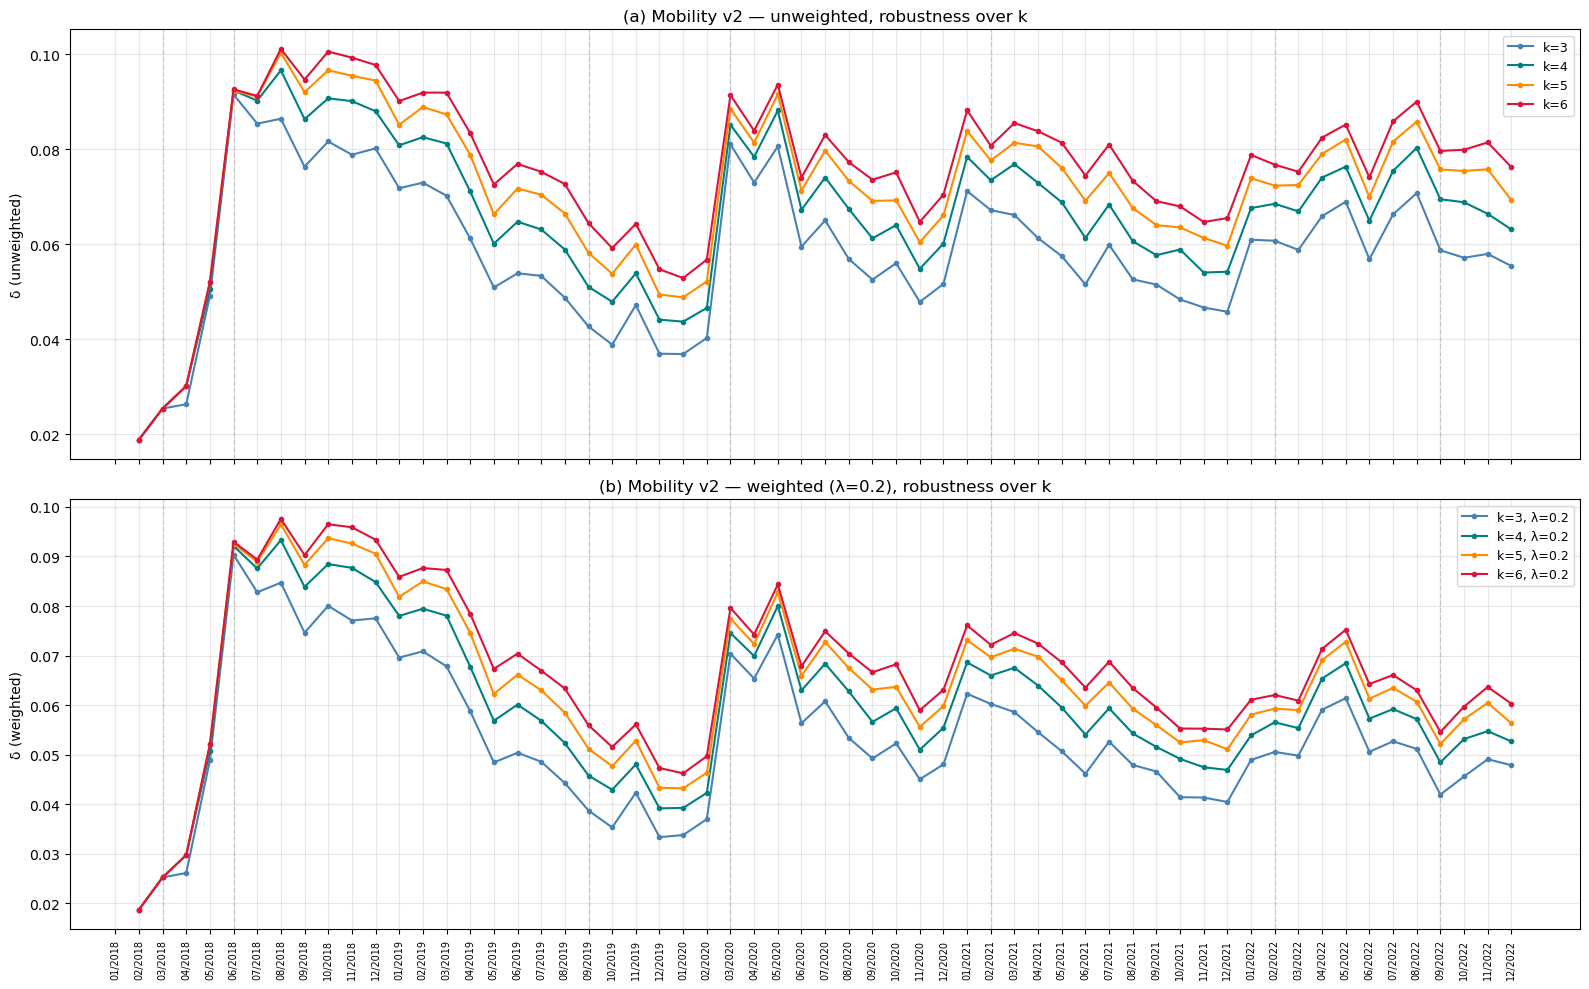

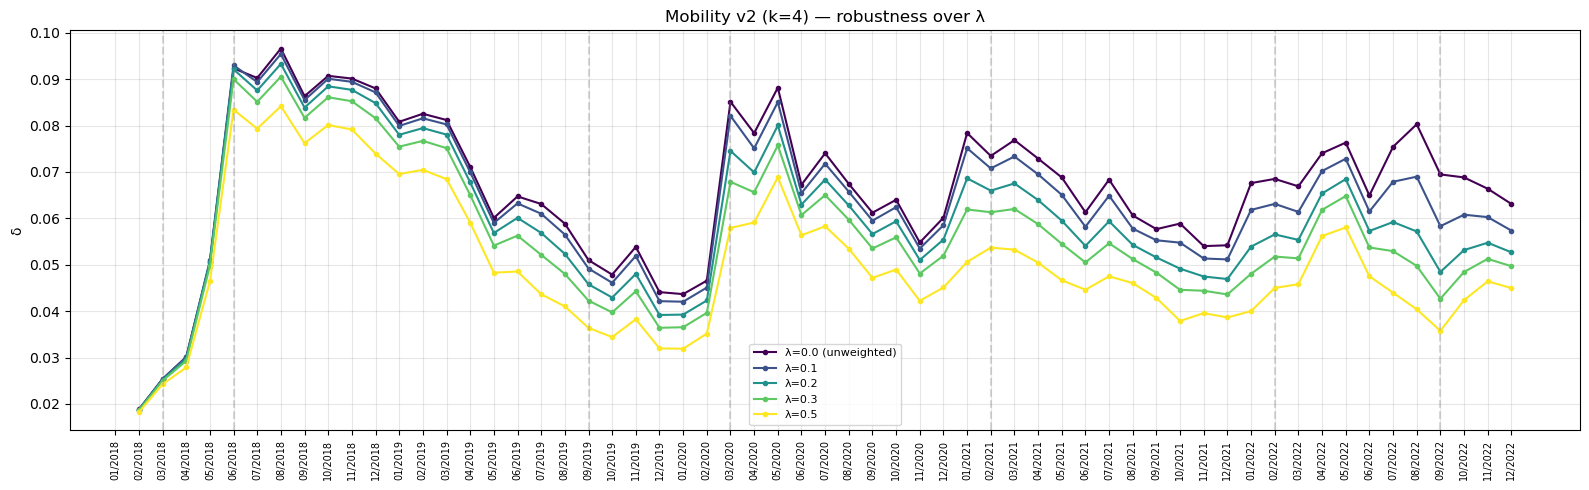

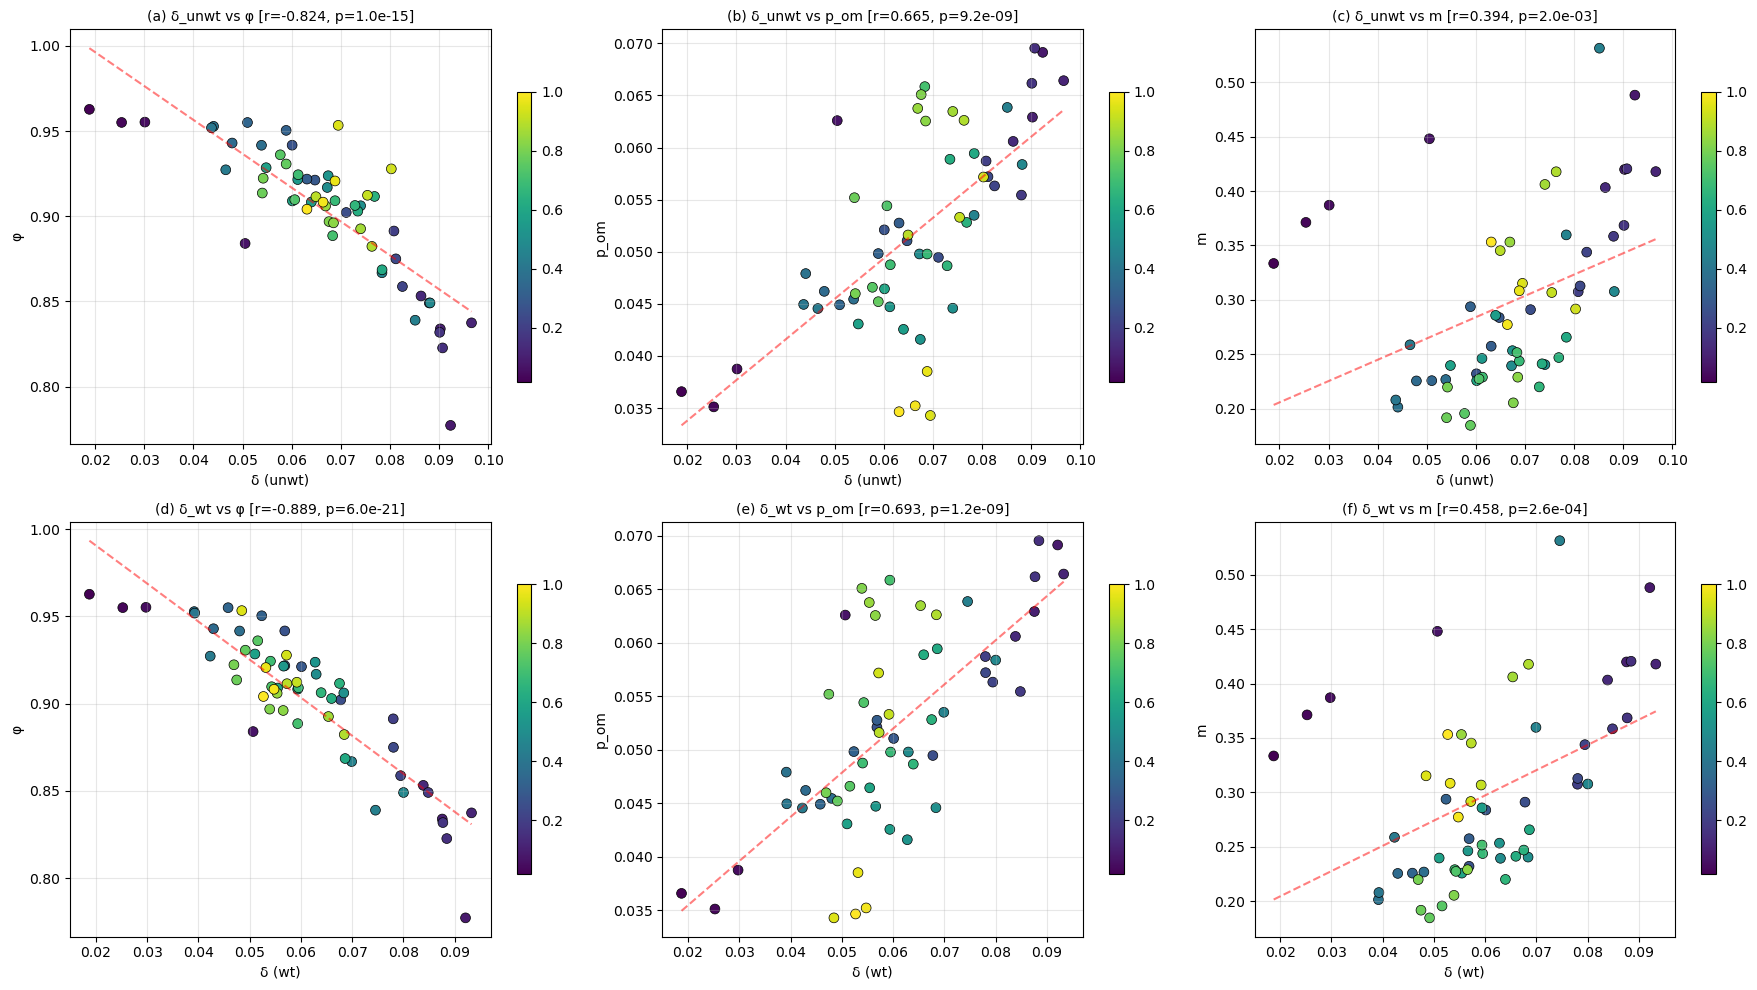

In [ ]:
# =============================================================================
# Mobility v2: Multidimensional Standard Deviation of Last k Steps
# =============================================================================
#
# For each agent at time t (where they have an observation), take the last k
# observations (actual appearances, not necessarily consecutive months).
#
# UNWEIGHTED:
#   x_centroid = (1/k) Σ x_i
#   δ = sqrt( (1/k) Σ ||x_i - x_centroid||² )
#
# WEIGHTED (exponential decay from current time):
#   w_i = exp(-λ · (t - t_i))       where t_i is the time of observation i
#   x_centroid = Σ w_i x_i / Σ w_i
#   δ_w = sqrt( Σ w_i ||x_i - x_centroid||² / Σ w_i )
#
# Population monthly mobility = mean of δ over all agents active that month.
# =============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# --- 0. Parse time and sort ---
def month_year_to_ordinal(my_str):
    parts = my_str.split('/')
    return (int(parts[1]) - 2018) * 12 + int(parts[0])

ov = opinion_vectors_monthly.copy()
ov['t_ord'] = ov['month_year'].apply(month_year_to_ordinal)
ov = ov.sort_values(['reference_author', 't_ord'])

# Pre-group by user for efficiency
print("Grouping by user...")
user_groups = {}
for user, group in ov.groupby('reference_author'):
    vecs = group[['comm_0', 'comm_1', 'comm_2']].values
    times = group['t_ord'].values
    months = group['month_year'].values
    if len(vecs) >= 2:  # need at least 2 observations
        user_groups[user] = (vecs, times, months)

print(f"Users with ≥2 observations: {len(user_groups):,}")

# --- 1. Compute mobility for given k and λ ---
def compute_mobility_monthly(user_groups, k, lam, all_months):
    """
    For each user at each observation, compute δ from last k steps.
    Returns dict: month_year → mean δ over all agents active that month.

    lam=0 → unweighted, lam>0 → exponential decay from current time.
    """
    # Collect (month, delta) pairs
    month_deltas = {m: [] for m in all_months}

    for user, (vecs, times, months) in user_groups.items():
        for idx in range(1, len(vecs)):  # skip first observation (no history)
            current_month = months[idx]
            current_time = times[idx]

            # Last k observations up to and including current
            start = max(0, idx - k + 1)
            window_vecs = vecs[start:idx + 1]
            window_times = times[start:idx + 1]

            if len(window_vecs) < 2:
                continue

            if lam == 0:
                # Unweighted
                centroid = window_vecs.mean(axis=0)
                diffs = window_vecs - centroid
                delta = np.sqrt(np.mean(np.sum(diffs**2, axis=1)))
            else:
                # Weighted by exponential decay from current time
                dt = current_time - window_times  # time gaps from current (≥0)
                weights = np.exp(-lam * dt)
                weights /= weights.sum()

                centroid = (weights[:, None] * window_vecs).sum(axis=0)
                diffs = window_vecs - centroid
                delta = np.sqrt((weights * np.sum(diffs**2, axis=1)).sum())

            if current_month in month_deltas:
                month_deltas[current_month].append(delta)

    # Average over agents per month
    result = {}
    for m in all_months:
        if month_deltas[m]:
            result[m] = np.mean(month_deltas[m])

    return result

# --- 2. Compute for multiple k values (unweighted) ---
k_values = [3, 4, 5, 6]
lam_default = 0.2

print("\nComputing unweighted mobility for different k...")
mob_unweighted = {}
for k in k_values:
    mob_unweighted[k] = compute_mobility_monthly(user_groups, k, lam=0, all_months=all_months)
    print(f"  k={k}: {len(mob_unweighted[k])} months")

print("\nComputing weighted mobility (λ=0.2) for different k...")
mob_weighted = {}
for k in k_values:
    mob_weighted[k] = compute_mobility_monthly(user_groups, k, lam=lam_default, all_months=all_months)
    print(f"  k={k}: {len(mob_weighted[k])} months")

# --- 3. Prepare reference series ---
phi_vals = [phi_monthly.get(m, np.nan) for m in all_months]
pom_vals = [pop_om_series.get(m, np.nan) for m in all_months]
m_vals   = [m_monthly_new.get(m, np.nan) for m in all_months]

# =====================================================================
# FIGURE 1: Time series — robustness over k (unweighted + weighted)
# =====================================================================
fig, axes = plt.subplots(2, 1, figsize=(16, 10), sharex=True)

colors_k = {3: 'steelblue', 4: 'teal', 5: 'darkorange', 6: 'crimson'}

for k in k_values:
    vals = [mob_unweighted[k].get(m, np.nan) for m in all_months]
    axes[0].plot(range(len(all_months)), vals, 'o-', markersize=3,
                 color=colors_k[k], label=f'k={k}')

axes[0].set_ylabel('δ (unweighted)')
axes[0].set_title('(a) Mobility v2 — unweighted, robustness over k')
axes[0].legend(fontsize=9)
axes[0].grid(alpha=0.3)

for k in k_values:
    vals = [mob_weighted[k].get(m, np.nan) for m in all_months]
    axes[1].plot(range(len(all_months)), vals, 'o-', markersize=3,
                 color=colors_k[k], label=f'k={k}, λ={lam_default}')

axes[1].set_ylabel('δ (weighted)')
axes[1].set_title(f'(b) Mobility v2 — weighted (λ={lam_default}), robustness over k')
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.3)
axes[1].set_xticks(range(len(all_months)))
axes[1].set_xticklabels(all_months, rotation=90, fontsize=7)

# Events
month_to_x = {m: i for i, m in enumerate(all_months)}
for ax in axes:
    for event_date, label in events.items():
        parts = event_date.split('-')
        month_key = event_date
        if month_key in month_to_x:
            xi = month_to_x[month_key]
            ax.axvline(xi, color='gray', alpha=0.3, linestyle='--', linewidth=1)

plt.tight_layout()
plt.savefig('Fig_mobility_v2_timeseries.png', dpi=300, bbox_inches='tight')
plt.show()

# =====================================================================
# FIGURE 2: Robustness over λ (fixed k=4)
# =====================================================================
k_fixed = 4
lambdas = [0.0, 0.1, 0.2, 0.3, 0.5]

fig, ax = plt.subplots(figsize=(16, 5))
colors_lam = plt.cm.viridis(np.linspace(0, 1, len(lambdas)))

for idx, lam in enumerate(lambdas):
    mob_lam = compute_mobility_monthly(user_groups, k_fixed, lam=lam, all_months=all_months)
    vals = [mob_lam.get(m, np.nan) for m in all_months]
    label = f'λ={lam}' + (' (unweighted)' if lam == 0 else '')
    ax.plot(range(len(all_months)), vals, 'o-', markersize=3,
            color=colors_lam[idx], label=label)

ax.set_xticks(range(len(all_months)))
ax.set_xticklabels(all_months, rotation=90, fontsize=7)
ax.set_ylabel('δ')
ax.set_title(f'Mobility v2 (k={k_fixed}) — robustness over λ')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

for event_date, label in events.items():
    parts = event_date.split('-')
    month_key = event_date
    if month_key in month_to_x:
        ax.axvline(month_to_x[month_key], color='gray', alpha=0.3, linestyle='--')

plt.tight_layout()
plt.savefig('Fig_mobility_v2_lambda_robustness.png', dpi=300, bbox_inches='tight')
plt.show()

# =====================================================================
# FIGURE 3: Scatter plots con colorbar (k=4, unweighted e weighted)
# =====================================================================
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
t_norm = np.linspace(0, 1, len(all_months))

def scatter_corr(ax, xvals, yvals, xlabel, ylabel, title):
    valid_idx = [i for i in range(len(xvals)) if not (np.isnan(xvals[i]) or np.isnan(yvals[i]))]
    if len(valid_idx) < 5:
        ax.set_title(f'{title} — insufficient data')
        return
    xv = [xvals[i] for i in valid_idx]
    yv = [yvals[i] for i in valid_idx]
    tv = [t_norm[i] for i in valid_idx]
    sc = ax.scatter(xv, yv, c=tv, cmap='viridis', s=50, edgecolors='black', linewidths=0.5)
    plt.colorbar(sc, ax=ax, shrink=0.7)
    z = np.polyfit(xv, yv, 1)
    xl = np.linspace(min(xv), max(xv), 100)
    ax.plot(xl, np.poly1d(z)(xl), 'r--', alpha=0.5)
    r, p = pearsonr(xv, yv)
    ax.set_xlabel(xlabel, fontsize=10)
    ax.set_ylabel(ylabel, fontsize=10)
    ax.set_title(f'{title} [r={r:.3f}, p={p:.1e}]', fontsize=10)
    ax.grid(alpha=0.3)

# Unweighted k=4
mob_uw = [mob_unweighted[4].get(m, np.nan) for m in all_months]
scatter_corr(axes[0, 0], mob_uw, phi_vals, 'δ (unwt)', 'φ', '(a) δ_unwt vs φ')
scatter_corr(axes[0, 1], mob_uw, pom_vals, 'δ (unwt)', 'p_om', '(b) δ_unwt vs p_om')
scatter_corr(axes[0, 2], mob_uw, m_vals, 'δ (unwt)', 'm', '(c) δ_unwt vs m')

# Weighted k=4
mob_wt = [mob_weighted[4].get(m, np.nan) for m in all_months]
scatter_corr(axes[1, 0], mob_wt, phi_vals, 'δ (wt)', 'φ', '(d) δ_wt vs φ')
scatter_corr(axes[1, 1], mob_wt, pom_vals, 'δ (wt)', 'p_om', '(e) δ_wt vs p_om')
scatter_corr(axes[1, 2], mob_wt, m_vals, 'δ (wt)', 'm', '(f) δ_wt vs m')

plt.tight_layout()
plt.savefig('Fig_mobility_v2_scatter.png', dpi=300, bbox_inches='tight')
plt.show()



# SECONDI MOMENTI DELLE DISTRIBUZIONI 

Mesi calcolati: 60


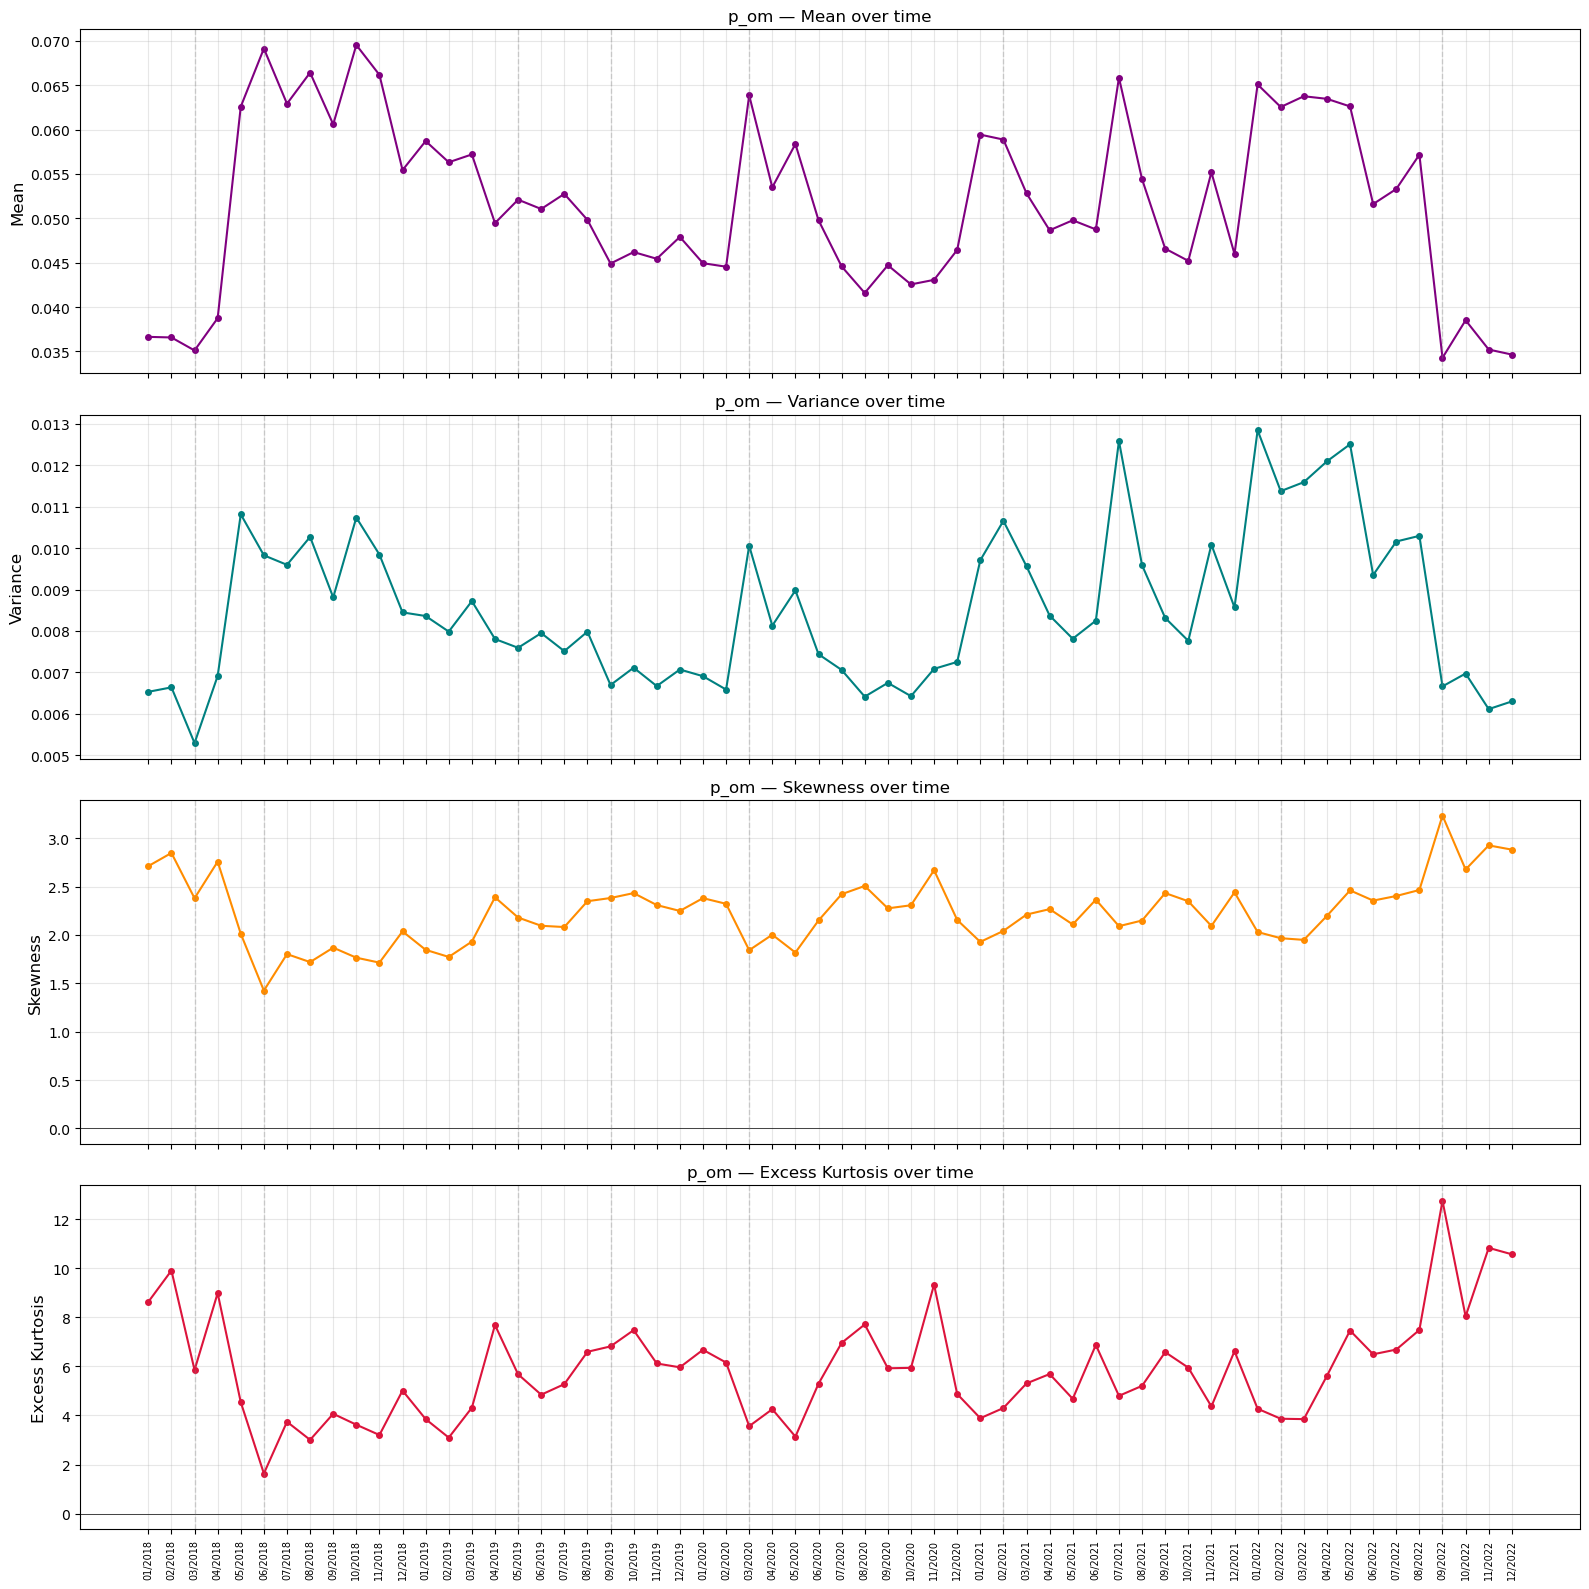


CORRELAZIONE MOMENTI DI p_om vs φ
  Mean                 vs φ: r=-0.759, p=2.15e-12
  Variance             vs φ: r=-0.527, p=1.52e-05
  Skewness             vs φ: r=0.760, p=1.96e-12
  Excess Kurtosis      vs φ: r=0.677, p=2.96e-09

TABELLA MOMENTI PER MESE
     Month       N     Mean      Var      Std     Skew     Kurt   Median
   01/2018    4922   0.0366   0.0065   0.0808    2.713    8.628   0.0000
   02/2018    5928   0.0366   0.0066   0.0815    2.849    9.905   0.0000
   03/2018    3855   0.0351   0.0053   0.0728    2.380    5.851   0.0000
   04/2018    2314   0.0387   0.0069   0.0832    2.759    8.985   0.0000
   05/2018    4140   0.0626   0.0108   0.1040    2.013    4.540   0.0000
   06/2018    9518   0.0691   0.0098   0.0991    1.425    1.634   0.0000
   07/2018    8096   0.0629   0.0096   0.0980    1.802    3.743   0.0000
   08/2018    8986   0.0664   0.0103   0.1013    1.720    3.006   0.0000
   09/2018    8518   0.0606   0.0088   0.0939    1.869    4.068   0.0000
   10/2018 

In [ ]:
# =============================================================================
# Momenti della distribuzione di p_om sulla popolazione: serie temporali
# =============================================================================
# Presuppone: quotes_with_dist (con colonna 'open_minded'), all_months,
#             events, event_colors, phi_monthly
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import skew, kurtosis, pearsonr

# --- 1. Calcolo p_om per utente-mese ---
p_om_user = (
    quotes_with_dist
    .groupby(['month_year', 'reference_author'])['open_minded']
    .mean()
    .reset_index()
    .rename(columns={'open_minded': 'p_om'})
)

# --- 2. Calcolo momenti per mese ---
moments = {}
for month in all_months:
    vals = p_om_user.loc[p_om_user['month_year'] == month, 'p_om'].values
    if len(vals) >= 10:
        moments[month] = {
            'mean':     np.mean(vals),
            'variance': np.var(vals),
            'std':      np.std(vals),
            'skewness': skew(vals),
            'kurtosis': kurtosis(vals),          # excess kurtosis (Fisher)
            'median':   np.median(vals),
            'N':        len(vals),
        }

print(f"Mesi calcolati: {len(moments)}")

# --- 3. Plot: 4 pannelli ---
fig, axes = plt.subplots(4, 1, figsize=(16, 16), sharex=True)

x = range(len(all_months))
month_to_x = {m: i for i, m in enumerate(all_months)}

series = [
    ('Mean',              [moments[m]['mean'] if m in moments else np.nan for m in all_months],     'purple'),
    ('Variance',          [moments[m]['variance'] if m in moments else np.nan for m in all_months], 'teal'),
    ('Skewness',          [moments[m]['skewness'] if m in moments else np.nan for m in all_months], 'darkorange'),
    ('Excess Kurtosis',   [moments[m]['kurtosis'] if m in moments else np.nan for m in all_months], 'crimson'),
]

for idx, (name, vals, color) in enumerate(series):
    ax = axes[idx]
    ax.plot(x, vals, 'o-', color=color, markersize=4)
    ax.set_ylabel(name, fontsize=12)
    ax.set_title(f'p_om — {name} over time')
    ax.grid(alpha=0.3)

    # Zero line per skewness e kurtosis
    if name in ('Skewness', 'Excess Kurtosis'):
        ax.axhline(0, color='black', linewidth=0.5, linestyle='-')

    # Eventi
    for event_date, label in events.items():
        parts = event_date.split('-')
        month_key = event_date
        if month_key in month_to_x:
            xi = month_to_x[month_key]
            ax.axvline(xi, color='gray', alpha=0.3, linestyle='--', linewidth=1)

axes[-1].set_xticks(x)
axes[-1].set_xticklabels(all_months, rotation=90, fontsize=7)

plt.tight_layout()
plt.savefig('Fig_pom_moments_timeseries.png', dpi=300, bbox_inches='tight')
plt.show()

# --- 4. Correlazione momenti vs φ ---
print("\n" + "="*60)
print("CORRELAZIONE MOMENTI DI p_om vs φ")
print("="*60)

phi_vals = [phi_monthly.get(m, np.nan) for m in all_months]

for name, vals, _ in series:
    valid = [(a, b) for a, b in zip(vals, phi_vals) if not (np.isnan(a) or np.isnan(b))]
    if len(valid) >= 5:
        a, b = zip(*valid)
        r, p = pearsonr(a, b)
        print(f"  {name:20s} vs φ: r={r:.3f}, p={p:.2e}")

# --- 5. Tabella riassuntiva ---
print("\n" + "="*60)
print("TABELLA MOMENTI PER MESE")
print("="*60)
print(f"{'Month':>10s} {'N':>7s} {'Mean':>8s} {'Var':>8s} {'Std':>8s} {'Skew':>8s} {'Kurt':>8s} {'Median':>8s}")
for m in all_months:
    if m in moments:
        d = moments[m]
        print(f"{m:>10s} {d['N']:>7d} {d['mean']:>8.4f} {d['variance']:>8.4f} {d['std']:>8.4f} {d['skewness']:>8.3f} {d['kurtosis']:>8.3f} {d['median']:>8.4f}")

# stessa cosa per m 

Mesi calcolati: 60


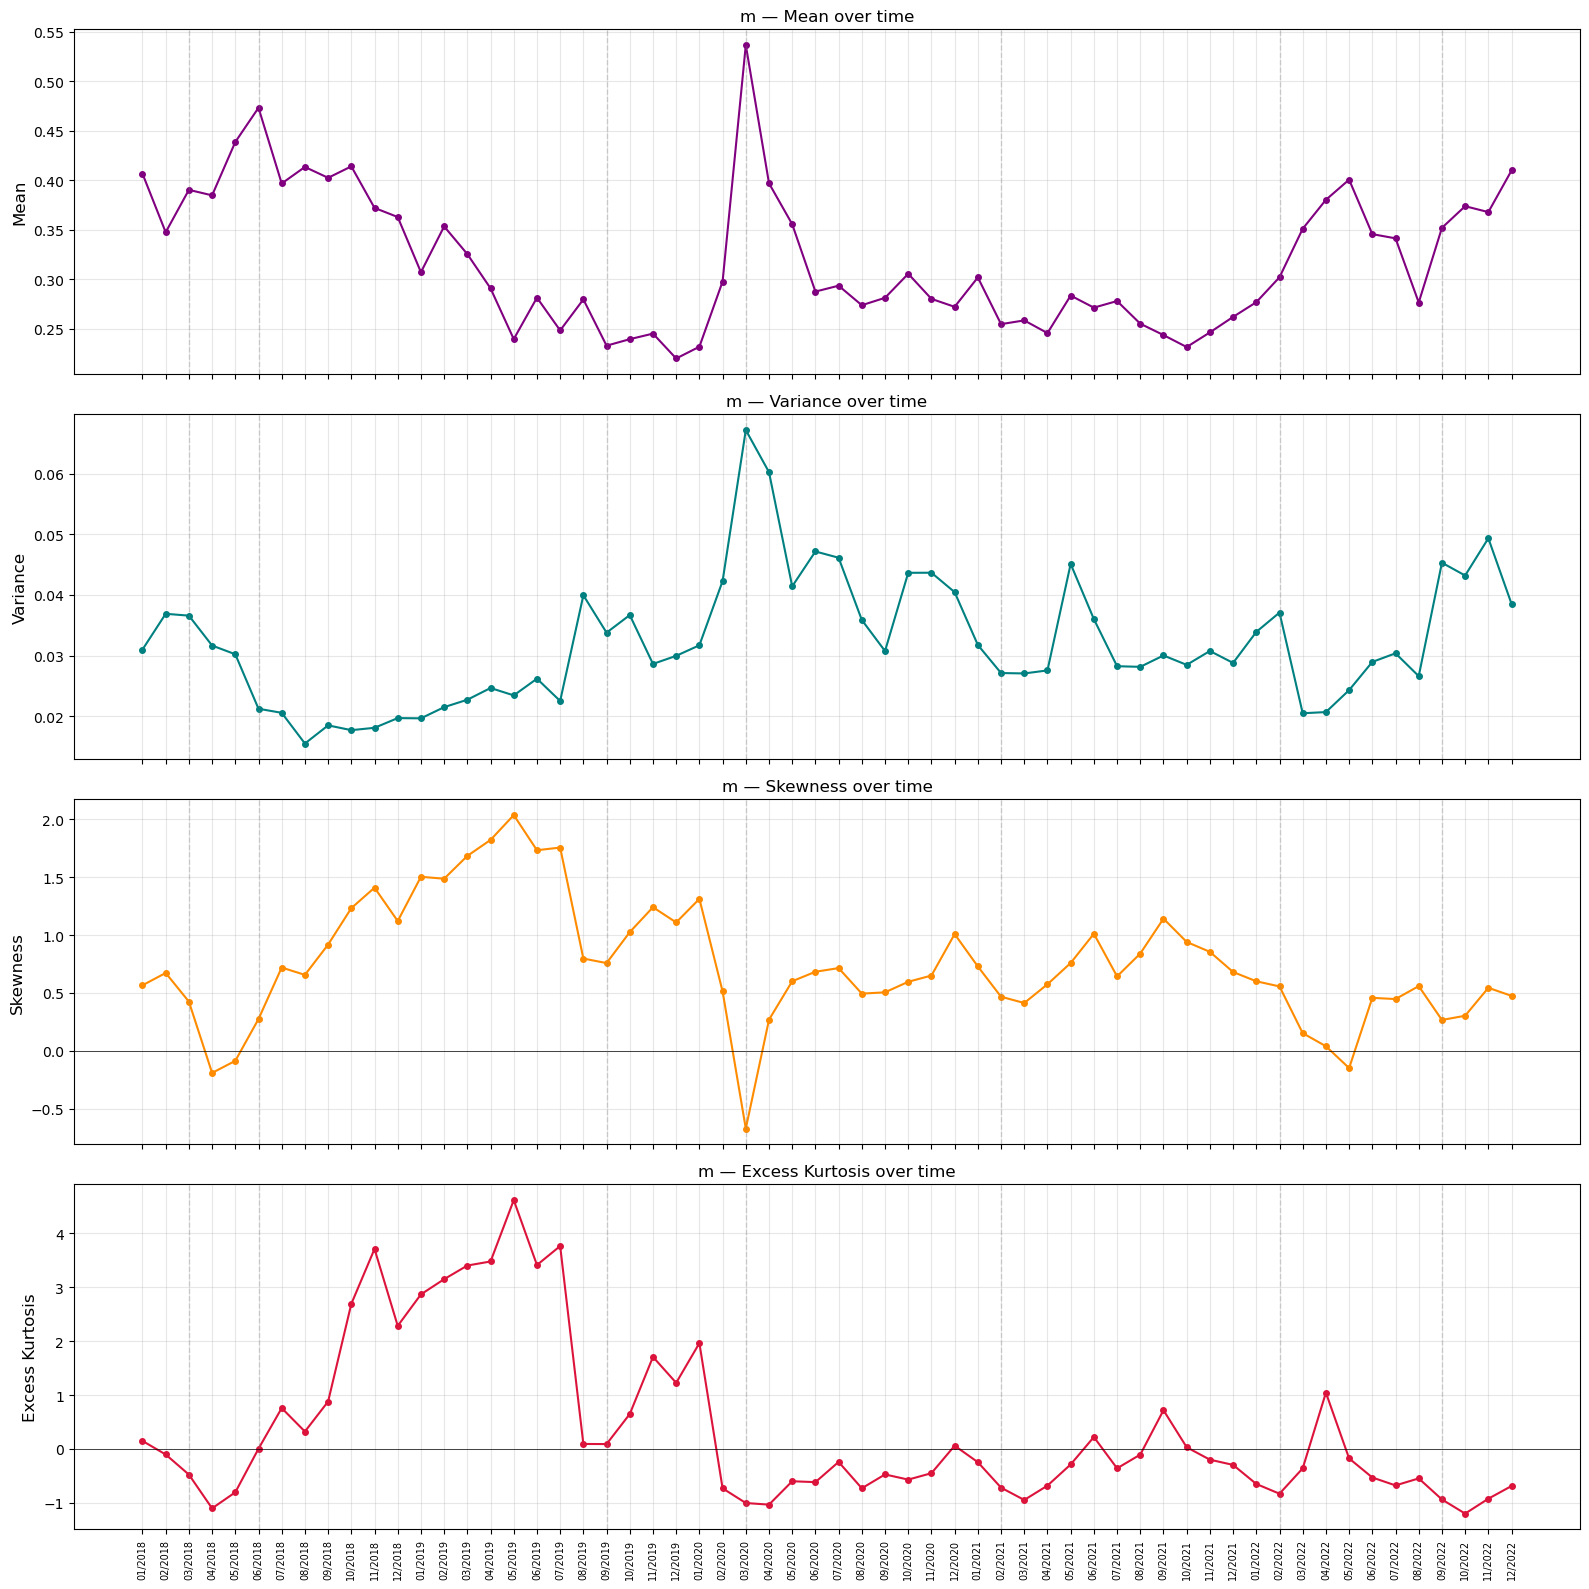


CORRELAZIONE MOMENTI DI m vs φ
  Mean                 vs φ: r=-0.596, p=4.97e-07
  Variance             vs φ: r=0.246, p=5.78e-02
  Skewness             vs φ: r=0.075, p=5.71e-01
  Excess Kurtosis      vs φ: r=-0.150, p=2.52e-01

TABELLA MOMENTI PER MESE (m)
     Month       N     Mean      Var      Std     Skew     Kurt   Median
   01/2018    3600   0.4065   0.0310   0.1760    0.566    0.149   0.3772
   02/2018    4207   0.3473   0.0369   0.1921    0.672   -0.103   0.3152
   03/2018    2954   0.3902   0.0366   0.1913    0.425   -0.475   0.3784
   04/2018    1744   0.3846   0.0316   0.1779   -0.191   -1.102   0.3966
   05/2018    3407   0.4385   0.0302   0.1738   -0.087   -0.804   0.4438
   06/2018    7486   0.4730   0.0212   0.1456    0.274    0.005   0.4639
   07/2018    6510   0.3966   0.0205   0.1433    0.719    0.758   0.3753
   08/2018    7239   0.4133   0.0155   0.1243    0.656    0.323   0.3971
   09/2018    6614   0.4023   0.0185   0.1359    0.918    0.880   0.3748
   10/2018

In [ ]:
# =============================================================================
# Momenti della distribuzione di m sulla popolazione: serie temporali
# =============================================================================
# Presuppone: rt_u2s (con colonna 'mildness', da cella 7 "Mild Source Fraction"),
#             all_months, events, event_colors, phi_monthly
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import skew, kurtosis, pearsonr

# --- 1. Calcolo m per utente-mese (media della mildness delle source retwittate) ---
m_user = (
    rt_u2s
    .groupby(['month_year', 'reference_author'])['mildness']
    .mean()
    .reset_index()
    .rename(columns={'mildness': 'm'})
)

# --- 2. Calcolo momenti per mese ---
moments_m = {}
for month in all_months:
    vals = m_user.loc[m_user['month_year'] == month, 'm'].values
    if len(vals) >= 10:
        moments_m[month] = {
            'mean':     np.mean(vals),
            'variance': np.var(vals),
            'std':      np.std(vals),
            'skewness': skew(vals),
            'kurtosis': kurtosis(vals),          # excess kurtosis (Fisher)
            'median':   np.median(vals),
            'N':        len(vals),
        }

print(f"Mesi calcolati: {len(moments_m)}")

# --- 3. Plot: 4 pannelli ---
fig, axes = plt.subplots(4, 1, figsize=(16, 16), sharex=True)

x = range(len(all_months))
month_to_x = {m: i for i, m in enumerate(all_months)}

series_m = [
    ('Mean',              [moments_m[m]['mean'] if m in moments_m else np.nan for m in all_months],     'purple'),
    ('Variance',          [moments_m[m]['variance'] if m in moments_m else np.nan for m in all_months], 'teal'),
    ('Skewness',          [moments_m[m]['skewness'] if m in moments_m else np.nan for m in all_months], 'darkorange'),
    ('Excess Kurtosis',   [moments_m[m]['kurtosis'] if m in moments_m else np.nan for m in all_months], 'crimson'),
]

for idx, (name, vals, color) in enumerate(series_m):
    ax = axes[idx]
    ax.plot(x, vals, 'o-', color=color, markersize=4)
    ax.set_ylabel(name, fontsize=12)
    ax.set_title(f'm — {name} over time')
    ax.grid(alpha=0.3)

    if name in ('Skewness', 'Excess Kurtosis'):
        ax.axhline(0, color='black', linewidth=0.5, linestyle='-')

    for event_date, label in events.items():
        parts = event_date.split('-')
        month_key = event_date
        if month_key in month_to_x:
            xi = month_to_x[month_key]
            ax.axvline(xi, color='gray', alpha=0.3, linestyle='--', linewidth=1)

axes[-1].set_xticks(x)
axes[-1].set_xticklabels(all_months, rotation=90, fontsize=7)

plt.tight_layout()
plt.savefig('Fig_m_moments_timeseries.png', dpi=300, bbox_inches='tight')
plt.show()

# --- 4. Correlazione momenti vs φ ---
print("\n" + "="*60)
print("CORRELAZIONE MOMENTI DI m vs φ")
print("="*60)

phi_vals = [phi_monthly.get(m, np.nan) for m in all_months]

for name, vals, _ in series_m:
    valid = [(a, b) for a, b in zip(vals, phi_vals) if not (np.isnan(a) or np.isnan(b))]
    if len(valid) >= 5:
        a, b = zip(*valid)
        r, p = pearsonr(a, b)
        print(f"  {name:20s} vs φ: r={r:.3f}, p={p:.2e}")

# --- 5. Tabella riassuntiva ---
print("\n" + "="*60)
print("TABELLA MOMENTI PER MESE (m)")
print("="*60)
print(f"{'Month':>10s} {'N':>7s} {'Mean':>8s} {'Var':>8s} {'Std':>8s} {'Skew':>8s} {'Kurt':>8s} {'Median':>8s}")
for m in all_months:
    if m in moments_m:
        d = moments_m[m]
        print(f"{m:>10s} {d['N']:>7d} {d['mean']:>8.4f} {d['variance']:>8.4f} {d['std']:>8.4f} {d['skewness']:>8.3f} {d['kurtosis']:>8.3f} {d['median']:>8.4f}")

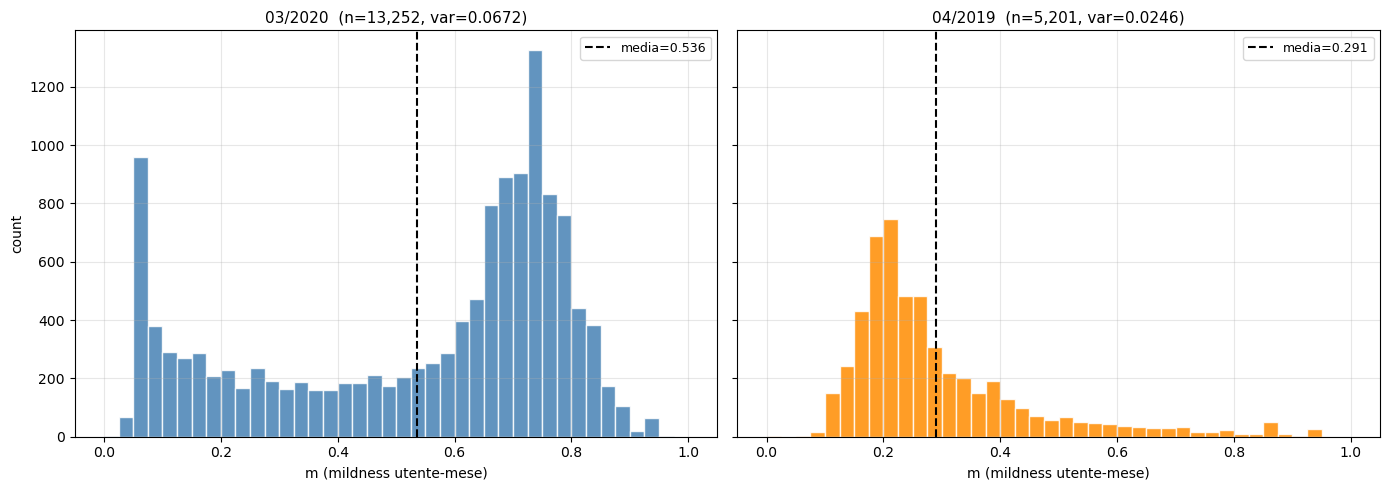

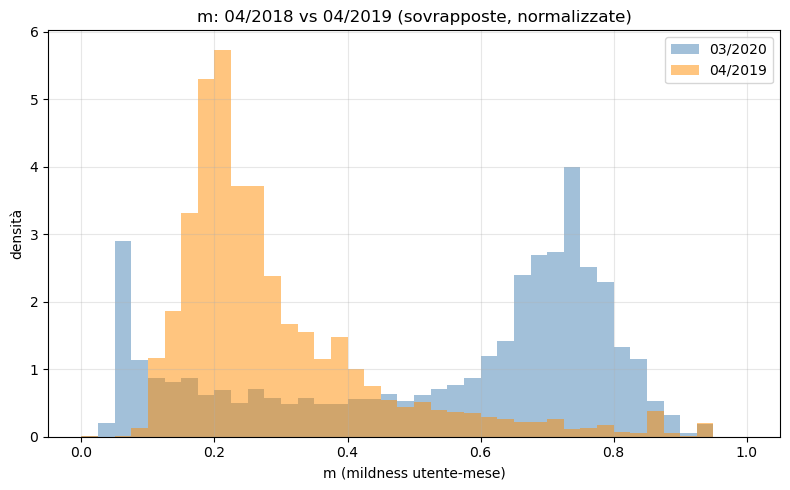

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- Ricalcola m_user da rt_u2s (se non già in memoria) ---
m_user = (
    rt_u2s
    .groupby(['month_year', 'reference_author'])['mildness']
    .mean()
    .reset_index()
    .rename(columns={'mildness': 'm'})
)

# --- Istogrammi affiancati ---
months_to_show = ['03/2020', '04/2019']
colors = ['steelblue', 'darkorange']

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, month, color in zip(axes, months_to_show, colors):
    vals = m_user.loc[m_user['month_year'] == month, 'm'].values
    ax.hist(vals, bins=40, range=(0, 1), color=color, edgecolor='white', alpha=0.85)
    ax.axvline(np.mean(vals), color='black', linestyle='--', linewidth=1.5,
               label=f'media={np.mean(vals):.3f}')
    ax.set_title(f'{month}  (n={len(vals):,}, var={np.var(vals):.4f})', fontsize=11)
    ax.set_xlabel('m (mildness utente-mese)')
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)

axes[0].set_ylabel('count')
plt.tight_layout()
plt.show()

# --- Sovrapposte, per confronto diretto della forma ---
fig, ax = plt.subplots(figsize=(8, 5))
for month, color in zip(months_to_show, colors):
    vals = m_user.loc[m_user['month_year'] == month, 'm'].values
    ax.hist(vals, bins=40, range=(0, 1), color=color, alpha=0.5, density=True, label=month)

ax.set_xlabel('m (mildness utente-mese)')
ax.set_ylabel('densità')
ax.set_title('m: 04/2018 vs 04/2019 (sovrapposte, normalizzate)')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation

# --- Assicura che m_user esista ---
m_user = (
    rt_u2s
    .groupby(['month_year', 'reference_author'])['mildness']
    .mean()
    .reset_index()
    .rename(columns={'mildness': 'm'})
)

fig, ax = plt.subplots(figsize=(8, 6))

# --- Bin fissi e y-limit comune, per confrontabilità tra frame ---
bins = np.linspace(0, 1, 41)
ymax = max(
    (np.histogram(m_user.loc[m_user['month_year'] == m, 'm'].values, bins=bins)[0].max()
     if len(m_user.loc[m_user['month_year'] == m, 'm'].values) > 0 else 0)
    for m in all_months
)

def update(frame):
    ax.clear()
    month = all_months[frame]
    vals = m_user.loc[m_user['month_year'] == month, 'm'].values
    is_event = month in events
    color = 'crimson' if is_event else 'teal'

    ax.hist(vals, bins=bins, color=color, edgecolor='white', alpha=0.85)
    if len(vals) > 0:
        ax.axvline(np.mean(vals), color='black', linestyle='--', linewidth=1.5)

    label = events.get(month, '')
    title = f'm — {month}' + (f'   ★ {label} ★' if label else '')
    ax.set_title(title, fontsize=13, color='crimson' if is_event else 'black')
    ax.set_xlabel('m (mildness utente-mese)')
    ax.set_ylabel('count')
    ax.set_xlim(0, 1)
    ax.set_ylim(0, ymax * 1.05)
    ax.grid(alpha=0.3)

anim = animation.FuncAnimation(fig, update, frames=len(all_months), interval=300)
anim.save('m_distribution_evolution.gif', writer='pillow', fps=3)
plt.close(fig)

print("GIF salvata: m_distribution_evolution.gif")

GIF salvata: m_distribution_evolution.gif


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from scipy.stats import gaussian_kde, skew, kurtosis

# --- Assicura che p_om_user esista ---
p_om_user = (
    quotes_with_dist
    .groupby(['month_year', 'reference_author'])['open_minded']
    .mean()
    .reset_index()
    .rename(columns={'open_minded': 'p_om'})
)

# --- Range adattivo: usa il 99° percentile di tutti i valori invece di [0,1] fisso ---
all_vals = p_om_user['p_om'].values
xmax = min(1.0, np.percentile(all_vals, 99) * 1.3)
bins = np.linspace(0, xmax, 41)
xgrid = np.linspace(0, xmax, 300)

ymax = 0
for m in all_months:
    vals = p_om_user.loc[p_om_user['month_year'] == m, 'p_om'].values
    if len(vals) > 1:
        ymax = max(ymax, np.histogram(vals, bins=bins)[0].max())

overall_mean = all_vals.mean()

# --- Costruisci la sequenza di frame, ripetendo i mesi-evento per "soffermarsi" ---
frame_months = []
for m in all_months:
    frame_months.append(m)
    if m in events:
        frame_months.extend([m, m])  # 3 frame totali sul mese elettorale/evento

fig, ax = plt.subplots(figsize=(9, 6))

def update(frame):
    ax.clear()
    month = frame_months[frame]
    vals = p_om_user.loc[p_om_user['month_year'] == month, 'p_om'].values
    is_event = month in events
    label = events.get(month, '')
    color = event_colors.get(label, 'purple') if is_event else 'purple'

    ax.hist(vals, bins=bins, color=color, edgecolor='white', alpha=0.75, density=True)

    

    ax.axvline(overall_mean, color='gray', linestyle=':', linewidth=1.5,
               label=f'media generale = {overall_mean:.3f}')
    if len(vals) > 0:
        ax.axvline(vals.mean(), color='crimson' if is_event else 'black',
                   linestyle='--', linewidth=1.5, label=f'media mese = {vals.mean():.3f}')

    title = f'p_om — {month}' + (f'   ★ {label} ★' if label else '')
    ax.set_title(title, fontsize=14, color='crimson' if is_event else 'black', fontweight='bold' if is_event else 'normal')
    ax.set_xlabel('p_om (utente-mese)')
    ax.set_ylabel('densità')
    ax.set_xlim(0, 0.35)
    ax.set_ylim(0, ymax / (len(vals) * (bins[1]-bins[0])) * 1.4 if len(vals) > 0 else 1)
    ax.legend(fontsize=8, loc='upper right')
    ax.grid(alpha=0.3)

    if len(vals) > 3:
        stats_txt = f"n={len(vals):,}\nvar={np.var(vals):.4f}\nskew={skew(vals):.2f}\nkurt={kurtosis(vals):.2f}"
        ax.text(0.98, 0.75, stats_txt, transform=ax.transAxes, fontsize=9,
                ha='right', va='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

anim = animation.FuncAnimation(fig, update, frames=len(frame_months), interval=350)
anim.save('p_om_distribution_evolution.gif', writer='pillow', fps=3)
plt.close(fig)

print(f"GIF salvata: p_om_distribution_evolution.gif ({len(frame_months)} frame, {len(all_months)} mesi)")

GIF salvata: p_om_distribution_evolution.gif (76 frame, 60 mesi)


# gif delle distanze sul simplesso 

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from scipy.stats import skew, kurtosis

tau = 2/3
bins = np.linspace(0, 1, 41)

ymax = 0
for m in all_months:
    vals = quotes_with_dist.loc[quotes_with_dist['month_year'] == m, 'distance'].values
    if len(vals) > 1:
        h, _ = np.histogram(vals, bins=bins, density=True)
        ymax = max(ymax, h.max())

# --- Sequenza di frame, con pausa sui mesi-evento ---
frame_months = []
for m in all_months:
    frame_months.append(m)
    if m in events:
        frame_months.extend([m, m])

fig, ax = plt.subplots(figsize=(9, 6))

def update(frame):
    ax.clear()
    month = frame_months[frame]
    vals = quotes_with_dist.loc[quotes_with_dist['month_year'] == month, 'distance'].values
    is_event = month in events
    label = events.get(month, '')
    color = event_colors.get(label, 'steelblue') if is_event else 'steelblue'

    ax.hist(vals, bins=bins, color=color, edgecolor='white', alpha=0.8, density=True)
    ax.axvline(tau, color='red', linestyle='--', linewidth=1.5, label=f'τ = {tau:.2f}')
    if len(vals) > 0:
        ax.axvline(vals.mean(), color='black', linestyle=':', linewidth=1.5,
                   label=f'media = {vals.mean():.3f}')

    title = f'Distanza sul simplesso — {month}' + (f'   ★ {label} ★' if label else '')
    ax.set_title(title, fontsize=14, color='crimson' if is_event else 'black',
                 fontweight='bold' if is_event else 'normal')
    ax.set_xlabel('distance')
    ax.set_ylabel('densità')
    ax.set_xlim(0, 1)
    ax.set_ylim(0, ymax * 1.15)
    ax.legend(fontsize=8, loc='upper center')
    ax.grid(alpha=0.3)

    if len(vals) > 3:
        stats_txt = f"n={len(vals):,}\nvar={np.var(vals):.4f}\nskew={skew(vals):.2f}\nkurt={kurtosis(vals):.2f}"
        ax.text(0.98, 0.75, stats_txt, transform=ax.transAxes, fontsize=9,
                ha='right', va='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

anim = animation.FuncAnimation(fig, update, frames=len(frame_months), interval=350)
anim.save('distance_distribution_evolution.gif', writer='pillow', fps=3)
plt.close(fig)

print(f"GIF salvata: distance_distribution_evolution.gif ({len(frame_months)} frame, {len(all_months)} mesi)")

GIF salvata: distance_distribution_evolution.gif (76 frame, 60 mesi)


# VERIFICA ANCORA ISTERESI

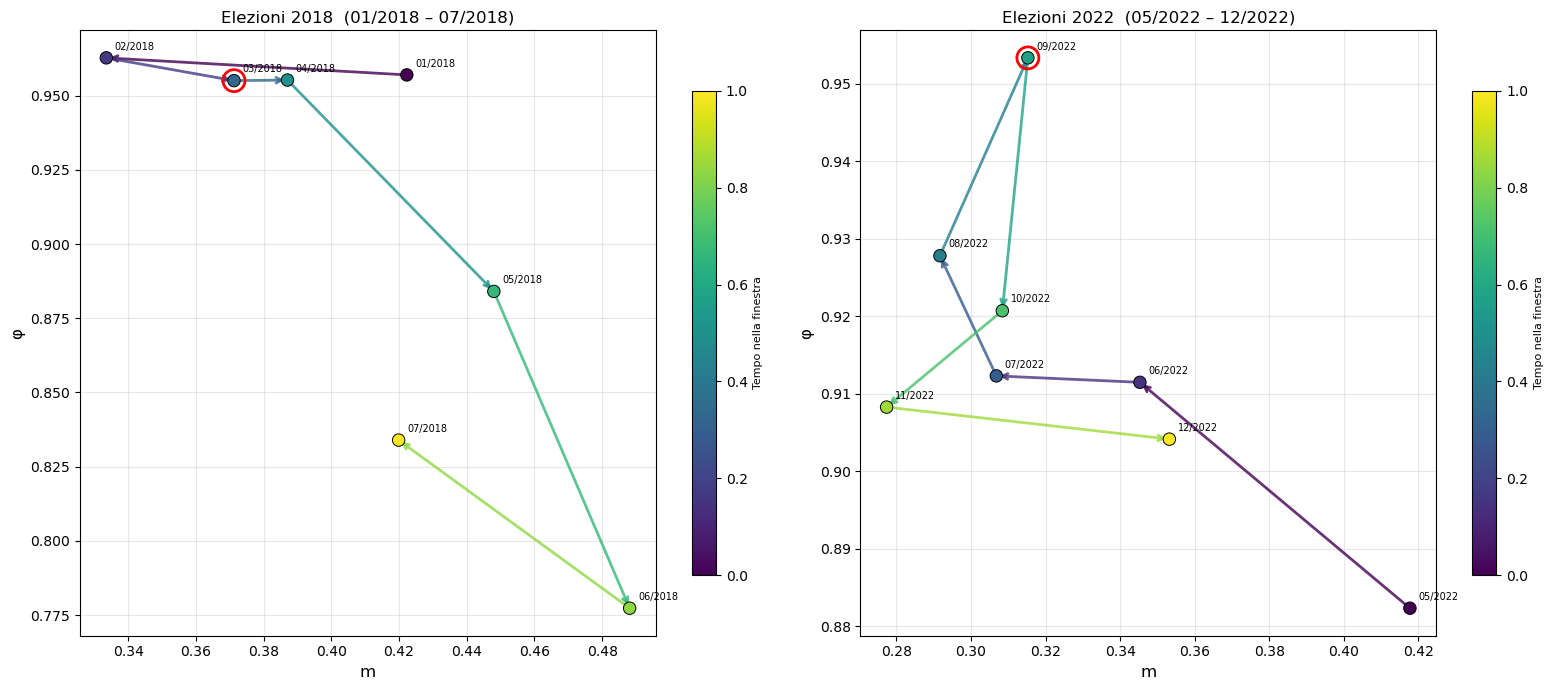

LOOP AREA NELLE FINESTRE ELETTORALI (m vs φ)

Elezioni 2018 (finestra 01/2018–07/2018, n=7 mesi):
  Area del loop:             -0.002625
  Area normalizzata (/bbox): 0.0916
  Bootstrap p-value:         0.594

Elezioni 2022 (finestra 05/2022–12/2022, n=8 mesi):
  Area del loop:             0.000249
  Area normalizzata (/bbox): 0.0250
  Bootstrap p-value:         0.896


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def window_around(month_key, months_list, before=4, after=4):
    idx = months_list.index(month_key)
    lo = max(0, idx - before)
    hi = min(len(months_list), idx + after + 1)
    return months_list[lo:hi]

def plot_local_trajectory(ax, win_months, xvals_all, yvals_all, xlabel, ylabel, title, highlight_month):
    idxs = [all_months.index(m) for m in win_months]
    xv = np.array([xvals_all[i] for i in idxs])
    yv = np.array([yvals_all[i] for i in idxs])
    t_local = np.linspace(0, 1, len(win_months))

    cmap = plt.cm.viridis
    colors = cmap(t_local)

    for i in range(len(xv) - 1):
        ax.annotate('', xy=(xv[i+1], yv[i+1]), xytext=(xv[i], yv[i]),
                     arrowprops=dict(arrowstyle='->', color=colors[i], lw=2, alpha=0.8))

    sc = ax.scatter(xv, yv, c=t_local, cmap='viridis', s=80,
                     edgecolors='black', linewidths=0.7, zorder=5)
    for i, m in enumerate(win_months):
        ax.annotate(m, (xv[i], yv[i]), textcoords="offset points", xytext=(6, 6), fontsize=7)

    if highlight_month in win_months:
        hi_idx = win_months.index(highlight_month)
        ax.scatter([xv[hi_idx]], [yv[hi_idx]], s=250, facecolors='none',
                   edgecolors='red', linewidths=2, zorder=10)

    cbar = plt.colorbar(sc, ax=ax, shrink=0.8)
    cbar.set_label('Tempo nella finestra', fontsize=8)

    ax.set_xlabel(xlabel, fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.set_title(title, fontsize=12)
    ax.grid(alpha=0.3)

elections = {'03/2018': 'Elezioni 2018', '09/2022': 'Elezioni 2022'}

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, (month_key, label) in zip(axes, elections.items()):
    win_months = window_around(month_key, all_months, before=4, after=4)
    plot_local_trajectory(ax, win_months, m_vals, phi_vals, 'm', 'φ',
                           f'{label}  ({win_months[0]} – {win_months[-1]})', month_key)

plt.tight_layout()
plt.savefig('Fig_hysteresis_election_windows.png', dpi=300, bbox_inches='tight')
plt.show()

# --- Area del loop, solo nella finestra elettorale ---
print("="*60)
print("LOOP AREA NELLE FINESTRE ELETTORALI (m vs φ)")
print("="*60)
for month_key, label in elections.items():
    win_months = window_around(month_key, all_months, before=4, after=4)
    idxs = [all_months.index(m) for m in win_months]
    m_win = [m_vals[i] for i in idxs]
    phi_win = [phi_vals[i] for i in idxs]

    area, coords = compute_loop_area(m_win, phi_win)
    bbox = bbox_area(m_win, phi_win)
    obs, null, p = bootstrap_loop_area(m_win, phi_win, n_boot=2000)

    print(f"\n{label} (finestra {win_months[0]}–{win_months[-1]}, n={len(win_months)} mesi):")
    print(f"  Area del loop:             {area:.6f}")
    print(f"  Area normalizzata (/bbox): {abs(area)/bbox:.4f}")
    print(f"  Bootstrap p-value:         {p:.3f}")

# 11. Isteresi su un panel di utenti "sempre attivi" (finestra evento)

Le serie usate finora (`phi_monthly`, `m_monthly_new`, `pop_om_series`) aggregano, mese per mese,
popolazioni diverse: il set di utenti con >=3 retweet verso politici cambia di mese in mese (turnover).
Per verificare l'isteresi in senso teorico (Fokker-Planck: una popolazione fissa che attraversa una
biforcazione) restringiamo l'analisi a un **panel di utenti stabili**: utenti che soddisfano il filtro
gia' esistente (>=3 retweet/mese) in **ogni mese** di una finestra piu' corta, centrata su un evento/crisi
(non sull'intero periodo 2018-2022, che lascerebbe un panel vuoto).

Finestra di default: prima=4/dopo=4 mesi attorno a Elezioni 2018 ed Elezioni 2022, la stessa scelta gia'
usata nella cella "VERIFICA ANCORA ISTERESI". Per testare altri eventi (Pandemia, Draghi, Guerra Ucraina, ...)
basta aggiungere la chiave a `panel_events` nella cella sottostante — usa le stesse etichette di `events`
definito piu' sopra.

**Nota:** questa cella presuppone che le celle precedenti siano gia' state eseguite (servono
`opinion_vectors_monthly`, `rt_u2s`, `quotes_with_dist`, `phi`, `all_months`, `window_around`,
`plot_local_trajectory`, `compute_loop_area`, `bbox_area`, `bootstrap_loop_area`, `m_vals`, `phi_vals`, `pom_vals`).


In [ ]:
# =============================================================================
# Hysteresis su un panel di utenti "sempre attivi" nella finestra evento
# =============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

panel_events = {'03/2018': 'Elezioni 2018', '09/2022': 'Elezioni 2022'}
BEFORE, AFTER = 6, 6


def get_panel_users(win_months, ov):
    """Utenti presenti (>=3 rt/mese, gia' filtrato in opinion_vectors_monthly)
    in OGNI mese della finestra."""
    sets = [set(ov.loc[ov['month_year'] == m, 'reference_author']) for m in win_months]
    return set.intersection(*sets) if sets else set()


def phi_series_for_users(win_months, ov, users):
    out = {}
    for m in win_months:
        df_m = ov[(ov['month_year'] == m) & (ov['reference_author'].isin(users))]
        pop = df_m[['comm_0', 'comm_1', 'comm_2']].values
        if len(pop) > 0:
            out[m] = phi(pop)
    return out


def mean_series_for_users(win_months, df, users, value_col):
    sub = df[df['reference_author'].isin(users)]
    out = {}
    for m in win_months:
        vals = sub.loc[sub['month_year'] == m, value_col]
        if len(vals) > 0:
            out[m] = vals.mean()
    return out


def plot_panel_trajectory(ax, win_months, xv_raw, yv_raw, xlabel, ylabel, title, highlight_month):
    """Come plot_local_trajectory ma per array gia' allineati a win_months
    (non all_months) -- evita l'IndexError di plot_local_trajectory quando
    gli array passati non coprono l'intera serie temporale."""
    xv = np.array(xv_raw, dtype=float)
    yv = np.array(yv_raw, dtype=float)
    valid = ~(np.isnan(xv) | np.isnan(yv))
    months_v = [m for m, ok in zip(win_months, valid) if ok]
    xv, yv = xv[valid], yv[valid]

    if len(xv) < 2:
        ax.set_title(title + "  (dati insufficienti)")
        return

    t_local = np.linspace(0, 1, len(xv))
    cmap = plt.cm.viridis
    colors = cmap(t_local)

    for i in range(len(xv) - 1):
        ax.annotate('', xy=(xv[i+1], yv[i+1]), xytext=(xv[i], yv[i]),
                     arrowprops=dict(arrowstyle='->', color=colors[i], lw=2, alpha=0.8))

    sc = ax.scatter(xv, yv, c=t_local, cmap='viridis', s=80,
                     edgecolors='black', linewidths=0.7, zorder=5)
    for i, m in enumerate(months_v):
        ax.annotate(m, (xv[i], yv[i]), textcoords="offset points", xytext=(6, 6), fontsize=7)

    if highlight_month in months_v:
        hi_idx = months_v.index(highlight_month)
        ax.scatter([xv[hi_idx]], [yv[hi_idx]], s=250, facecolors='none',
                   edgecolors='red', linewidths=2, zorder=10)

    cbar = plt.colorbar(sc, ax=ax, shrink=0.8)
    cbar.set_label('Tempo nella finestra', fontsize=8)
    ax.set_xlabel(xlabel, fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.set_title(title, fontsize=12)
    ax.grid(alpha=0.3)


panel_results = {}

for month_key, label in panel_events.items():
    win_months = window_around(month_key, all_months, before=BEFORE, after=AFTER)
    panel_users = get_panel_users(win_months, opinion_vectors_monthly)

    n_global = [
        opinion_vectors_monthly.loc[opinion_vectors_monthly['month_year'] == m, 'reference_author'].nunique()
        for m in win_months
    ]

    print("=" * 70)
    print(f"{label}  \u2014  finestra {win_months[0]}\u2013{win_months[-1]}  ({len(win_months)} mesi)")
    print(f"  Utenti attivi per mese (globale): {n_global}")
    print(f"  Panel 'sempre attivo' (>=3 rt/mese in TUTTI i mesi): {len(panel_users)} utenti")
    print("=" * 70)

    if len(panel_users) < 10:
        print("  ATTENZIONE: panel troppo piccolo (<10 utenti), risultati inaffidabili.\n")
        panel_results[label] = None
        continue

    phi_panel = phi_series_for_users(win_months, opinion_vectors_monthly, panel_users)
    m_panel = mean_series_for_users(win_months, rt_u2s, panel_users, 'mildness')
    pom_panel = mean_series_for_users(win_months, quotes_with_dist, panel_users, 'open_minded')

    phi_p = [phi_panel.get(m, np.nan) for m in win_months]
    m_p = [m_panel.get(m, np.nan) for m in win_months]
    pom_p = [pom_panel.get(m, np.nan) for m in win_months]

    # --- Traiettorie (m,phi) e (p_om,phi) sul panel ---
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    plot_panel_trajectory(axes[0], win_months, m_p, phi_p, 'm (panel)', '\u03c6 (panel)',
                           f'{label} \u2014 panel sempre attivo: m vs \u03c6', month_key)
    plot_panel_trajectory(axes[1], win_months, pom_p, phi_p, 'p_om (panel)', '\u03c6 (panel)',
                           f'{label} \u2014 panel sempre attivo: p_om vs \u03c6', month_key)
    plt.tight_layout()
    plt.savefig(f'Fig_hysteresis_panel_{label.replace(" ", "_")}.png', dpi=300, bbox_inches='tight')
    plt.show()

    # --- Area del loop + bootstrap, sul panel ---
    area_m_p, _ = compute_loop_area(m_p, phi_p)
    area_pom_p, _ = compute_loop_area(pom_p, phi_p)
    bbox_m_p = bbox_area(m_p, phi_p)
    bbox_pom_p = bbox_area(pom_p, phi_p)
    obs_m_p, null_m_p, p_m_p = bootstrap_loop_area(m_p, phi_p, n_boot=2000)
    obs_pom_p, null_pom_p, p_pom_p = bootstrap_loop_area(pom_p, phi_p, n_boot=2000)

    # --- Stesso identico calcolo sulla popolazione globale, nella stessa finestra (confronto) ---
    idxs = [all_months.index(m) for m in win_months]
    m_g = [m_vals[i] for i in idxs]
    phi_g = [phi_vals[i] for i in idxs]
    pom_g = [pom_vals[i] for i in idxs]
    area_m_g, _ = compute_loop_area(m_g, phi_g)
    bbox_m_g = bbox_area(m_g, phi_g)
    _, _, p_m_g = bootstrap_loop_area(m_g, phi_g, n_boot=2000)

    print(f"\n  (m, \u03c6)     \u2014 GLOBALE:  area/bbox={abs(area_m_g)/bbox_m_g:.4f}, p={p_m_g:.3f}")
    print(f"  (m, \u03c6)     \u2014 PANEL:    area/bbox={abs(area_m_p)/bbox_m_p:.4f}, p={p_m_p:.3f}  (N={len(panel_users)})")
    print(f"  (p_om, \u03c6)  \u2014 PANEL:    area/bbox={abs(area_pom_p)/bbox_pom_p:.4f}, p={p_pom_p:.3f}")

    panel_results[label] = {
        'n_panel': len(panel_users), 'win_months': win_months,
        'area_m_panel': area_m_p, 'p_m_panel': p_m_p,
        'area_pom_panel': area_pom_p, 'p_pom_panel': p_pom_p,
        'area_m_global': area_m_g, 'p_m_global': p_m_g,
    }

print("\n" + "=" * 70)
print("INTERPRETAZIONE")
print("=" * 70)
print("""
Se l'isteresi osservata sulla popolazione globale (turnover di utenti ogni
mese) persiste anche restringendo l'analisi al panel di utenti sempre attivi
nella finestra (area/bbox e p-value comparabili per (m, phi), assenza di
isteresi per (p_om, phi)), allora l'isteresi non e' un artefatto del turnover
di popolazione ma una proprieta' dinamica reale del sistema -- coerente con la
predizione teorica del modello Sirbu-Loreto (bistabilita' indotta da m via
Fokker-Planck, Sez. 9.2).

ATTENZIONE: N piccolo (poche decine di utenti) rende l'area del loop e il
p-value del bootstrap rumorosi. Se il panel e' troppo piccolo su questa
finestra, va allargata la finestra (BEFORE/AFTER) o scelto un evento con
piu' utenti stabilmente attivi.
""")


# 12. Phase diagram teorico (simulazione ABM statica)

Questa e' la griglia phi(m, p_om) gia' simulata con `Functions_sirbu_loreto.py` e salvata in
`dati_matrice.csv` (10x10 punti, un'unica run per cella, non una media). Serve come riferimento
"teorico" grezzo, ma **attenzione**: ogni cella e' una singola realizzazione stocastica, non una
media su piu' run ne' uno sweep quasi-statico di m verso l'alto/basso. Quindi questa heatmap mostra
*dove* il sistema puo' finire polarizzato o coeso, non dimostra da sola l'isteresi (che richiede
di vedere DUE rami diversi -- salendo e scendendo -- nella stessa zona (m, p_om)).

Dalla griglia si vede una banda di transizione diagonale per p_om tra ~0.2 e ~0.5, dove a p_om
fissato l'aumento di m sposta il sistema da polarizzato (phi alto) a coeso (phi basso) -- coerente
con la predizione che m guidi la biforcazione. Fuori da questa banda (p_om<0.2 o p_om>0.5) phi
non dipende quasi per niente da m: sempre polarizzato o sempre coeso.


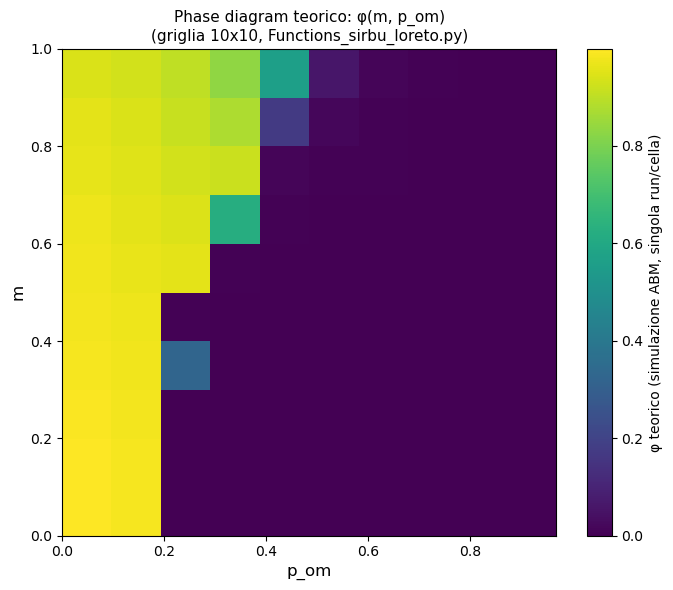

[[0.999 0.986 0.002 0.001 0.001 0.001 0.    0.    0.    0.   ]
 [0.996 0.986 0.002 0.001 0.001 0.001 0.    0.    0.    0.   ]
 [0.993 0.983 0.002 0.002 0.001 0.001 0.001 0.    0.    0.   ]
 [0.987 0.979 0.327 0.003 0.002 0.001 0.001 0.001 0.    0.   ]
 [0.982 0.972 0.006 0.003 0.002 0.002 0.001 0.001 0.    0.   ]
 [0.976 0.965 0.959 0.006 0.004 0.003 0.001 0.001 0.    0.   ]
 [0.973 0.959 0.947 0.621 0.006 0.004 0.002 0.002 0.001 0.   ]
 [0.963 0.951 0.929 0.918 0.015 0.007 0.004 0.002 0.001 0.   ]
 [0.957 0.943 0.916 0.878 0.169 0.017 0.008 0.003 0.002 0.   ]
 [0.942 0.931 0.906 0.834 0.562 0.061 0.013 0.007 0.004 0.002]]


In [ ]:
# =============================================================================
# Phase diagram teorico: heatmap statica phi(m, p_om) da dati_matrice.csv
# =============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

theory_grid = pd.read_csv('dati_matrice.csv')
m_vals_theory = np.sort(theory_grid['m_vals'].unique())
pom_vals_theory = np.sort(theory_grid['p_om_vals'].unique())
phi_grid = theory_grid.pivot(index='m_vals', columns='p_om_vals', values='phi_2d').values

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(phi_grid, origin='lower', aspect='auto', cmap='viridis',
               extent=[pom_vals_theory.min(), pom_vals_theory.max(),
                       m_vals_theory.min(), m_vals_theory.max()])
cbar = plt.colorbar(im, ax=ax)
cbar.set_label('\u03c6 teorico (simulazione ABM, singola run/cella)', fontsize=10)
ax.set_xlabel('p_om', fontsize=12)
ax.set_ylabel('m', fontsize=12)
ax.set_title('Phase diagram teorico: \u03c6(m, p_om)\n(griglia 10x10, Functions_sirbu_loreto.py)', fontsize=11)
plt.tight_layout()
plt.savefig('Fig_theory_phase_diagram.png', dpi=300, bbox_inches='tight')
plt.show()

print(np.round(phi_grid, 3))


In [ ]:
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

months = all_months
x = range(len(months))
phi_vals = [phi_monthly.get(m, np.nan) for m in months]
pom_vals = [pop_om_series.get(m, np.nan) for m in months]
m_vals_ts = [m_monthly_new.get(m, np.nan) for m in months]
mob_vals_ts = [mob_monthly.get(m, np.nan) for m in months]  # <- la serie di mobility che hai deciso di usare

def add_events(ax, months, events, event_colors, ypos=None):
    month_to_x = {m: i for i, m in enumerate(months)}
    if ypos is None:
        ypos = ax.get_ylim()[1]
    for event_date, label in events.items():
        if event_date in month_to_x:
            xi = month_to_x[event_date]
            color = event_colors.get(label, 'red')
            ax.axvline(xi, color=color, alpha=0.5, linestyle='--', linewidth=1)
            ax.text(xi + 0.3, ypos * 0.95, label, rotation=90, va='top', fontsize=7, color=color)

fig, axes = plt.subplots(4, 1, figsize=(14, 15), sharex=True)

axes[0].plot(x, phi_vals, 'o-', color='steelblue', markersize=4)
axes[0].set_ylabel('φ (polarization)', fontsize=12)
axes[0].set_title('(a) Polarization', fontsize=13)
axes[0].grid(alpha=0.3)
add_events(axes[0], months, events, event_colors)

axes[1].plot(x, pom_vals, 'o-', color='purple', markersize=4)
axes[1].set_ylabel('p_om', fontsize=12)
axes[1].set_title('(b) Open-mindedness', fontsize=13)
axes[1].grid(alpha=0.3)
add_events(axes[1], months, events, event_colors)

axes[2].plot(x, m_vals_ts, 'o-', color='teal', markersize=4)
axes[2].set_ylabel('m (mildness)', fontsize=12)
axes[2].set_title('(c) Mild source fraction', fontsize=13)
axes[2].grid(alpha=0.3)
add_events(axes[2], months, events, event_colors)

axes[3].plot(x, mob_vals_ts, 'o-', color='darkorange', markersize=4)
axes[3].set_ylabel('μ (mobility)', fontsize=12)
axes[3].set_title('(d) Mobility', fontsize=13)
axes[3].grid(alpha=0.3)
axes[3].set_xticks(x)
axes[3].set_xticklabels(months, rotation=90, fontsize=7)
add_events(axes[3], months, events, event_colors)

plt.savefig('Fig1_timeseries_IT.png', dpi=300, bbox_inches='tight')
plt.show()

NameError: name 'mob_monthly' is not defined

# 13. Robustezza dell'associazione p_om – φ: null model e direzione

La correlazione della sezione 9.2 (r ≈ −0.76) va difesa contro quattro spiegazioni alternative, ognuna con il suo test:

| Domanda | Test | Cella |
|---|---|---|
| **Artefatto di misura?** p_om usa distanze calcolate dagli *stessi* vettori di opinione da cui si calcola φ: la sola geometria dello spazio potrebbe produrre la correlazione. | Rimescolo le etichette di agreement tenendo fisse le distanze (dentro il mese / dentro l'utente-mese). | 13.2 |
| **Stessi utenti?** | Split-sample: φ da metà degli utenti, p_om dall'altra metà (come già fatto per m). | 13.3 |
| **Correlazione spuria tra serie autocorrelate?** Con ~60 mesi con trend, due serie indipendenti possono correlare molto (Yule 1926; Granger & Newbold 1974). | Surrogati IAAFT di p_om (stesso spettro e stessa distribuzione); correlazione su livelli, differenze prime e parziale rispetto a m. | 13.4 |
| **Direzione?** | Cross-correlazione ritardata sulle differenze prime + Granger in entrambe le direzioni, con e senza m. | 13.5 |

⚠️ Il p-value di `pearsonr` nella sezione 9.2 (p < 10⁻¹²) assume mesi indipendenti: con serie autocorrelate **non è valido**. Per il paper usare i p-value dei null model qui sotto.

In [4]:
# =============================================================================
# 13.1 Preparazione: serie mensili + array vettorizzati a livello di quote
# =============================================================================
import time, io, contextlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

T_POS, T_NEG = 2/3, 1/3          # soglie della sezione 5
rng = np.random.default_rng(42)

# --- Serie mensili allineate (mesi in cui esistono phi, p_om e m) ---
ts = pd.DataFrame({
    'phi':  pd.Series(phi_vals),
    'p_om': pop_om_series,
    'm':    m_monthly_new,
}).reindex(all_months).dropna()
months_ts = list(ts.index)
phi_arr, pom_arr, m_arr = ts['phi'].to_numpy(), ts['p_om'].to_numpy(), ts['m'].to_numpy()

r_obs, p_naive = pearsonr(pom_arr, phi_arr)
r_obs_diff = np.corrcoef(np.diff(pom_arr), np.diff(phi_arr))[0, 1]
print(f"Mesi usati: {len(ts)}")
print(f"r(p_om, φ) livelli      = {r_obs:+.3f}   (p naive = {p_naive:.1e}: NON valido, mesi autocorrelati)")
print(f"r(Δp_om, Δφ) diff. prime = {r_obs_diff:+.3f}")

# --- Array a livello di quote, ordinati per (mese, utente) ---
q = quotes_with_dist[['reference_author', 'month_year', 'distance', 'agreement']].copy()
q = q[q['month_year'].isin(months_ts)]
q['m_code'] = pd.Categorical(q['month_year'], categories=months_ts).codes
q['u_code'] = pd.factorize(q['reference_author'])[0]
q = q.sort_values(['m_code', 'u_code'], kind='stable').reset_index(drop=True)

dist  = q['distance'].to_numpy(float)
agr   = q['agreement'].to_numpy(float)     # eventuali NaN restano: contano nel denominatore come in sezione 5
mcode = q['m_code'].to_numpy()
ucode = q['u_code'].to_numpy()

# codice utente-mese contiguo e monotono (serve al rimescolamento a blocchi)
new_block = np.r_[True, (mcode[1:] != mcode[:-1]) | (ucode[1:] != ucode[:-1])]
um = np.cumsum(new_block) - 1
n_um, n_m = um[-1] + 1, len(months_ts)
um_month = mcode[new_block]                 # mese di ciascun utente-mese
n_q_um = np.bincount(um, minlength=n_um)
n_um_m = np.bincount(um_month, minlength=n_m)

def pom_series(agr_arr, um_mask=None):
    # p_om di popolazione per mese = media sugli utenti della frazione di quote open-minded (sezione 5)
    om = ((agr_arr > 0) & (dist > T_POS)) | ((agr_arr < 0) & (dist < T_NEG))
    pom_um = np.bincount(um, weights=om, minlength=n_um) / n_q_um
    if um_mask is None:
        return np.bincount(um_month, weights=pom_um, minlength=n_m) / n_um_m
    w = um_mask.astype(float)
    return (np.bincount(um_month, weights=pom_um * w, minlength=n_m)
            / np.bincount(um_month, weights=w, minlength=n_m))

def block_shuffle(values, block_codes):
    # permuta `values` dentro blocchi contigui (block_codes monotono non decrescente)
    idx = np.argsort(block_codes + rng.random(len(block_codes)))
    return values[idx]

def summarize(name, obs, null, alternative='less'):
    # alternative='less': atteso r < 0 (più p_om, meno φ); 'two-sided' per la cross-correlazione
    null = null[~np.isnan(null)]
    if alternative == 'less':
        p = (np.sum(null <= obs) + 1) / (len(null) + 1)
    else:
        p = (np.sum(np.abs(null - null.mean()) >= abs(obs - null.mean())) + 1) / (len(null) + 1)
    z = (obs - null.mean()) / null.std()
    print(f"{name:38s} r_obs={obs:+.3f}  null={null.mean():+.3f}±{null.std():.3f}  z={z:+.1f}  p={p:.4f}")
    return p

# --- Sanity check: la versione vettorizzata deve riprodurre pop_om_series ---
err = np.nanmax(np.abs(pom_series(agr) - pom_arr))
print(f"Quote: {len(q):,} | utenti-mese: {n_um:,} | max |Δ| con pop_om_series = {err:.2e}")
assert err < 1e-9, "La ricostruzione di p_om non coincide con la sezione 5: controllare prima di proseguire"

NameError: name 'phi_vals' is not defined

In [ ]:
# =============================================================================
# 13.2 Null model 1–2: rimescolamento delle etichette di agreement
# =============================================================================
# Restano fissi: le distanze (quindi la geometria legata a φ), il numero di quote per
# utente-mese e il tasso di agreement. Si rompe SOLO il legame agreement ↔ distanza.
#   'month'      : rimescolo dentro il mese        (preserva il tasso di agreement mensile)
#   'user_month' : rimescolo dentro l'utente-mese  (preserva il tasso di ogni utente: più severo)
# Lettura: la media del null dice quanta correlazione produce la sola geometria;
# se r osservato cade fuori dal null, l'associazione è portata dal comportamento
# (chi approva / critica chi), non dalla forma dello spazio delle opinioni.

N_PERM = 500      # ~1–2 s per permutazione e per livello su ~8M quote; ridurre per un test rapido

null_label = {}
for level, codes in [('month', mcode), ('user_month', um)]:
    t0 = time.time()
    out = np.empty((N_PERM, 2))
    for k in range(N_PERM):
        pom_null = pom_series(block_shuffle(agr, codes))
        out[k] = (np.corrcoef(pom_null, phi_arr)[0, 1],
                  np.corrcoef(np.diff(pom_null), np.diff(phi_arr))[0, 1])
        if k == 9:
            print(f"[{level}] tempo stimato: {(time.time() - t0) / 10 * N_PERM / 60:.1f} min")
    null_label[level] = out

print()
p_label = {}
for level, out in null_label.items():
    p_label[(level, 'livelli')] = summarize(f"label shuffle [{level}] livelli", r_obs, out[:, 0])
    p_label[(level, 'diff')]    = summarize(f"label shuffle [{level}] diff. prime", r_obs_diff, out[:, 1])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, j, obs, lab in [(axes[0], 0, r_obs, 'livelli'), (axes[1], 1, r_obs_diff, 'differenze prime')]:
    for level, c in [('month', 'tab:blue'), ('user_month', 'tab:orange')]:
        ax.hist(null_label[level][:, j], bins=40, alpha=0.6, color=c, label=f'null: shuffle {level}')
    ax.axvline(obs, color='red', lw=2, label='osservato')
    ax.set_title(f'r(p_om, φ) — {lab}')
    ax.set_xlabel('r')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig('FigS_null_label_shuffle.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# =============================================================================
# 13.3 Controllo split-sample: φ e p_om da utenti disgiunti
# =============================================================================
# Come il test già fatto per m: φ dal gruppo A, p_om dal gruppo B (split casuale 50/50
# degli utenti). Se r resta vicino al valore pieno, l'associazione non nasce dal fatto
# che le due grandezze sono calcolate sugli stessi utenti.

N_SPLIT = 100

ov = opinion_vectors_monthly[opinion_vectors_monthly['month_year'].isin(months_ts)]
X = ov[['comm_0', 'comm_1', 'comm_2']].to_numpy(float)
K = X.shape[1]
d2 = np.sum((X - 1 / K) ** 2, axis=1) * K / (K - 1)            # contributo individuale a φ
ov_m = pd.Categorical(ov['month_year'], categories=months_ts).codes

all_ids = pd.Index(pd.unique(np.concatenate([ov['reference_author'].to_numpy(),
                                             q['reference_author'].to_numpy()])))
ov_uid = all_ids.get_indexer(ov['reference_author'].to_numpy())
um_uid = all_ids.get_indexer(q['reference_author'].to_numpy()[new_block])   # utente di ogni utente-mese

r_split = np.empty((N_SPLIT, 2))
for k in range(N_SPLIT):
    in_A = rng.random(len(all_ids)) < 0.5          # A → φ ;  B → p_om
    a = in_A[ov_uid]
    phi_A = np.bincount(ov_m[a], weights=d2[a], minlength=n_m) / np.bincount(ov_m[a], minlength=n_m)
    pom_B = pom_series(agr, um_mask=~in_A[um_uid])
    r_split[k] = (np.corrcoef(pom_B, phi_A)[0, 1],
                  np.corrcoef(np.diff(pom_B), np.diff(phi_A))[0, 1])

for j, (lab, full) in enumerate([('livelli', r_obs), ('diff. prime', r_obs_diff)]):
    print(f"split-sample {lab:12s}: r = {r_split[:, j].mean():+.3f} ± {r_split[:, j].std():.3f}  "
          f"[min {r_split[:, j].min():+.3f}, max {r_split[:, j].max():+.3f}]   (campione pieno {full:+.3f})")

In [ ]:
# =============================================================================
# 13.4 Null model 4: correlazione spuria tra serie autocorrelate (surrogati IAAFT)
# =============================================================================
# I surrogati IAAFT (Schreiber & Schmitz 1996) hanno lo stesso spettro di potenza
# (quindi la stessa autocorrelazione/trend) e la stessa distribuzione di p_om, ma nessun
# legame con φ. Il test risponde: due serie con questa struttura temporale, indipendenti,
# quanto correlerebbero per caso?

N_SURR = 2000

def iaaft(x, n_iter=100):
    x = np.asarray(x, float)
    amp, xs = np.abs(np.fft.rfft(x)), np.sort(x)
    y = rng.permutation(x)
    for _ in range(n_iter):
        y = np.fft.irfft(amp * np.exp(1j * np.angle(np.fft.rfft(y))), n=len(x))
        y = xs[np.argsort(np.argsort(y))]
    return y

def partial_r(a, b, z):
    # correlazione tra a e b al netto (lineare) di z
    Z = np.column_stack([np.ones(len(z)), z])
    ra = a - Z @ np.linalg.lstsq(Z, a, rcond=None)[0]
    rb = b - Z @ np.linalg.lstsq(Z, b, rcond=None)[0]
    return np.corrcoef(ra, rb)[0, 1]

dpom, dphi, dm = np.diff(pom_arr), np.diff(phi_arr), np.diff(m_arr)
obs_s = {
    'livelli':               r_obs,
    'livelli | m':           partial_r(pom_arr, phi_arr, m_arr),
    'diff. prime':           r_obs_diff,
    'diff. prime | Δm':      partial_r(dpom, dphi, dm),
}
null_s = {k: np.empty(N_SURR) for k in obs_s}
for k in range(N_SURR):
    s, ds = iaaft(pom_arr), iaaft(dpom)
    null_s['livelli'][k]          = np.corrcoef(s, phi_arr)[0, 1]
    null_s['livelli | m'][k]      = partial_r(s, phi_arr, m_arr)
    null_s['diff. prime'][k]      = np.corrcoef(ds, dphi)[0, 1]
    null_s['diff. prime | Δm'][k] = partial_r(ds, dphi, dm)

p_iaaft = {name: summarize(f"IAAFT {name}", obs_s[name], null_s[name]) for name in obs_s}

In [ ]:
# =============================================================================
# 13.5 Direzione: cross-correlazione ritardata e causalità di Granger
# =============================================================================
# Tutto sulle differenze prime (serie stazionarie). Convenzione: lag L > 0 = p_om ANTICIPA φ.
# Granger = "il passato di X migliora la previsione di Y" → precedenza temporale, NON causalità.
from statsmodels.tsa.stattools import adfuller, grangercausalitytests
from statsmodels.tsa.api import VAR

import warnings
with warnings.catch_warnings():
    warnings.simplefilter('ignore', FutureWarning)
    for name, x in [('phi', phi_arr), ('p_om', pom_arr), ('m', m_arr)]:
        print(f"ADF {name:4s}: livelli p = {adfuller(x)[1]:.3f} | diff. prime p = {adfuller(np.diff(x))[1]:.3f}")

# --- (a) Cross-correlazione ritardata con banda nulla IAAFT ---
LAGS = np.arange(-3, 4)

def xcorr(a, b, L):  # corr(a_t, b_{t+L})
    if L > 0:
        a, b = a[:-L], b[L:]
    elif L < 0:
        a, b = a[-L:], b[:L]
    return np.corrcoef(a, b)[0, 1]

ccf_obs = np.array([xcorr(dpom, dphi, L) for L in LAGS])
ccf_null = np.empty((N_SURR, len(LAGS)))
for k in range(N_SURR):
    s = iaaft(dpom)
    ccf_null[k] = [xcorr(s, dphi, L) for L in LAGS]

print("\nCross-correlazione Δp_om(t) vs Δφ(t+L)   (L>0: p_om anticipa φ)")
for i, L in enumerate(LAGS):
    summarize(f"  lag {L:+d}", ccf_obs[i], ccf_null[:, i], alternative='two-sided')

fig, ax = plt.subplots(figsize=(7, 4))
lo, hi = np.percentile(ccf_null, [2.5, 97.5], axis=0)
ax.fill_between(LAGS, lo, hi, color='grey', alpha=0.3, label='95% null IAAFT')
ax.bar(LAGS, ccf_obs, color='purple', alpha=0.8, label='osservato')
ax.axhline(0, color='black', lw=0.8)
ax.set_xlabel('lag L [mesi]   (L>0: p_om anticipa φ)')
ax.set_ylabel('corr(Δp_om(t), Δφ(t+L))')
ax.legend()
plt.tight_layout()
plt.savefig('FigS_ccf_pom_phi.png', dpi=300, bbox_inches='tight')
plt.show()

# --- (b) Granger bivariato ---
d = pd.DataFrame({'phi': dphi, 'p_om': dpom, 'm': dm})
print("\nGranger bivariato (diff. prime) — p-value F-test")
for tgt, src in [('phi', 'p_om'), ('p_om', 'phi')]:
    with contextlib.redirect_stdout(io.StringIO()):     # compatibile con versioni di statsmodels con/senza `verbose`
        res = grangercausalitytests(d[[tgt, src]], maxlag=3)
    print(f"  {src:>4} → {tgt:<4}: " + "  ".join(f"lag {L}: p={res[L][0]['ssr_ftest'][1]:.3f}" for L in res))

# --- (c) VAR trivariato: controlla per m ---
p_lag = max(1, VAR(d).select_order(maxlags=3).aic)
var_res = VAR(d).fit(p_lag)
print(f"\nVAR (φ, p_om, m) su diff. prime, lag = {p_lag} (AIC)")
for tgt, src in [('phi', 'p_om'), ('p_om', 'phi'), ('phi', 'm'), ('m', 'phi')]:
    t = var_res.test_causality(tgt, [src], kind='f')
    print(f"  {src:>4} → {tgt:<4} (al netto dell'altra variabile): F = {t.test_statistic:.2f}, p = {t.pvalue:.3f}")

### 13.6 Come leggere i risultati

**Null model (13.2–13.4)**
- *Label shuffle*: la media del null è la correlazione prodotta dalla sola geometria (distanze legate a φ). Nel paper conta lo scarto tra osservato e null (z, p), non l'r grezzo. Se il null è già fortemente negativo, una parte della correlazione è meccanica e va detto.
- *Split-sample*: se r resta vicino al valore pieno, non è un effetto "stessi utenti".
- *IAAFT*: è il test che sostituisce il p naive della sezione 9.2. Per il paper il risultato più solido è quello sulle **differenze prime** e **al netto di m**: dice che i *cambiamenti* mensili di p_om e φ vanno insieme, non solo i trend.

**Direzione (13.5)**
- Picco della cross-correlazione a lag 0 e nessun lag ≠ 0 significativo → i due si muovono insieme **entro il mese**: la risoluzione mensile non basta per stabilire una direzione (coerente con il rilassamento più veloce di un mese già visto per m). Prossimo passo: serie settimanali, almeno attorno agli eventi.
- Granger significativo solo p_om → φ (e non viceversa), anche nel VAR con m → **precedenza temporale** compatibile con "p_om guida φ". Non è causalità: un terzo fattore che colpisce prima p_om produrrebbe lo stesso risultato.
- Con ~60 mesi la potenza è bassa e i test sono tanti (7 lag × 2 direzioni × 3 ordini): un singolo p < 0.05 isolato non va interpretato.